In [1]:
from google.colab import files
uploaded = files.upload()

Saving Final_Weekly_Natural_TPHCM.csv to Final_Weekly_Natural_TPHCM.csv
Saving Final_Weekly_Natural_HaNoi.csv to Final_Weekly_Natural_HaNoi.csv


In [2]:
import pandas as pd

df_hanoi = pd.read_csv("/content/Final_Weekly_Natural_HaNoi.csv")
df_tphcm = pd.read_csv("/content/Final_Weekly_Natural_TPHCM.csv")

print("Hà Nội:", df_hanoi.shape)
print("TP.HCM:", df_tphcm.shape)

Hà Nội: (670, 74)
TP.HCM: (670, 74)


In [3]:
import pandas as pd

df_hanoi = pd.read_csv("Final_Weekly_Natural_HaNoi.csv")
df_tphcm = pd.read_csv("Final_Weekly_Natural_TPHCM.csv")

print("HÀ NỘI")
print(df_hanoi.info())
print("\nSố giá trị thiếu:")
print(df_hanoi.isnull().sum().sum())
print("Số dòng trùng:")
print(df_hanoi.duplicated().sum())

print("\nTP.HCM")
print(df_tphcm.info())
print("\nSố giá trị thiếu:")
print(df_tphcm.isnull().sum().sum())
print("Số dòng trùng:")
print(df_tphcm.duplicated().sum())

HÀ NỘI
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 670 entries, 0 to 669
Data columns (total 74 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   date                       670 non-null    object 
 1   áo chống nắng              670 non-null    float64
 2   kính râm                   670 non-null    float64
 3   áo thun                    670 non-null    float64
 4   quần đùi                   670 non-null    float64
 5   váy maxi                   670 non-null    float64
 6   áo sơ mi                   670 non-null    float64
 7   đồ bơi                     670 non-null    float64
 8   dép sandal                 670 non-null    float64
 9   áo mưa                     670 non-null    float64
 10  ô dù                       670 non-null    float64
 11  áo mưa bộ                  670 non-null    float64
 12  áo khoác gió               670 non-null    float64
 13  dép nhựa                   670 non-null    

**Chuẩn hóa định dạng dữ liệu (Data Type Conversion)**

Sau khi kiểm tra kiểu dữ liệu của hai bộ dữ liệu Hà Nội và TP.HCM, nhóm nhận thấy phần lớn các biến đã được định dạng phù hợp. Các biến từ khóa thời trang và các chỉ tiêu thời tiết dạng số được lưu dưới kiểu dữ liệu số thực hoặc số nguyên. Các biến thời tiết được mã hóa dưới dạng Boolean.

Tuy nhiên, biến `date` vẫn đang ở dạng chuỗi ký tự (object), chưa phù hợp cho các thao tác xử lý và phân tích thời gian. Vì vậy, nhóm tiến hành chuyển đổi biến này sang định dạng datetime bằng Python. Đồng thời, nhóm kiểm tra các cột còn lại và chuyển đổi sang kiểu số nếu phát hiện cột nào vẫn đang ở dạng object nhưng chứa dữ liệu số.

Sau khi chuẩn hóa, dữ liệu được lưu thành hai tệp `clean_data_HaNoi.csv` và `clean_data_TPHCM.csv`, phục vụ cho các bước phát hiện giá trị ngoại lai, phân tích dữ liệu và xây dựng mô hình tiếp theo.

In [4]:

import pandas as pd
import numpy as np
import os

# 1. Doc du lieu
df_hanoi = pd.read_csv(
    "/content/Final_Weekly_Natural_HaNoi.csv"
)

df_tphcm = pd.read_csv(
    "/content/Final_Weekly_Natural_TPHCM.csv"
)

# 2. Ham chuan hoa kieu du lieu
def convert_data_types(df, city):

    df = df.copy()

    # Chuyen cot date sang datetime
    df["date"] = pd.to_datetime(
        df["date"],
        errors="raise"
    )

    # Chuyen cac cot dang object con lai sang numeric
    # Neu co cot object khong phai so thi se bao loi
    for col in df.columns:
        if col != "date" and df[col].dtype == "object":
            df[col] = pd.to_numeric(
                df[col],
                errors="raise"
            )

    print(f"\n===== {city} =====")
    print("Kieu du lieu sau chuan hoa:")
    print(df.dtypes.value_counts())

    print("\nChi tiet cac cot:")
    print(df.dtypes)

    return df


# 3. Thuc hien chuan hoa
df_hanoi_clean = convert_data_types(
    df_hanoi, "HA NOI"
)

df_tphcm_clean = convert_data_types(
    df_tphcm, "TP.HCM"
)

# 4. Kiem tra ket qua
print("\n===== KIEM TRA =====")

print("Ha Noi - date:", df_hanoi_clean["date"].dtype)
print("TP.HCM - date:", df_tphcm_clean["date"].dtype)

print("Ha Noi - kich thuoc:", df_hanoi_clean.shape)
print("TP.HCM - kich thuoc:", df_tphcm_clean.shape)

# 5. Luu du lieu sau chuan hoa
df_hanoi_clean.to_csv(
    "/content/clean_data_HaNoi.csv",
    index=False,
    encoding="utf-8-sig"
)

df_tphcm_clean.to_csv(
    "/content/clean_data_TPHCM.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nDa luu thanh cong 2 file du lieu!")



===== HA NOI =====
Kieu du lieu sau chuan hoa:
float64           61
bool              10
int64              2
datetime64[ns]     1
Name: count, dtype: int64

Chi tiet cac cot:
date             datetime64[ns]
áo chống nắng           float64
kính râm                float64
áo thun                 float64
quần đùi                float64
                      ...      
weather_53                 bool
weather_55                 bool
weather_61                 bool
weather_63                 bool
weather_65                 bool
Length: 74, dtype: object

===== TP.HCM =====
Kieu du lieu sau chuan hoa:
float64           61
bool              10
int64              2
datetime64[ns]     1
Name: count, dtype: int64

Chi tiet cac cot:
date             datetime64[ns]
áo chống nắng           float64
kính râm                float64
áo thun                 float64
quần đùi                float64
                      ...      
weather_53                 bool
weather_55                 bool
weather_61  

In [5]:

import pandas as pd
import numpy as np

# 1. Doc du lieu da chuan hoa
df_hanoi = pd.read_csv(
    "/content/clean_data_HaNoi.csv",
    parse_dates=["date"]
)

df_tphcm = pd.read_csv(
    "/content/clean_data_TPHCM.csv",
    parse_dates=["date"]
)

# 2. Xac dinh cac bien thoi tiet dang so
weather_cols = [
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "apparent_temperature_mean",
    "apparent_temperature_max",
    "apparent_temperature_min",
    "precipitation_sum",
    "rain_sum",
    "precipitation_hours",
    "daylight_duration",
    "sunshine_duration",
    "relative_humidity_2m_mean",
    "relative_humidity_2m_max",
    "relative_humidity_2m_min"
]

# 3. Ham phat hien outliers bang IQR
def detect_outliers(df, city):

    results = []

    for col in weather_cols:

        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)

        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        outliers = df[
            (df[col] < lower) |
            (df[col] > upper)
        ]

        results.append({
            "City": city,
            "Variable": col,
            "Q1": Q1,
            "Q3": Q3,
            "IQR": IQR,
            "Lower_Bound": lower,
            "Upper_Bound": upper,
            "Min": df[col].min(),
            "Max": df[col].max(),
            "Outlier_Count": len(outliers),
            "Outlier_Rate(%)": len(outliers) / len(df) * 100
        })

    return pd.DataFrame(results)


# 4. Phat hien cho hai thanh pho
outliers_hanoi = detect_outliers(df_hanoi, "HaNoi")
outliers_tphcm = detect_outliers(df_tphcm, "TPHCM")

outlier_report = pd.concat(
    [outliers_hanoi, outliers_tphcm],
    ignore_index=True
)

# 5. Hien thi ket qua
print("===== KET QUA PHAT HIEN OUTLIERS =====")

display(
    outlier_report.round(2)
)

print("\nTong so truong hop outlier:")
print(
    outlier_report.groupby("City")["Outlier_Count"].sum()
)

# 6. Luu bao cao
outlier_report.to_csv(
    "/content/Outlier_Report.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nDa luu bao cao Outlier_Report.csv")


===== KET QUA PHAT HIEN OUTLIERS =====


,City,Variable,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Min,Max,Outlier_Count,Outlier_Rate(%)
0,HaNoi,temperature_2m_mean,20.42,28.09,7.68,8.90,39.60,11.19,32.29,0,0.00
1,HaNoi,temperature_2m_max,27.60,34.20,6.60,17.70,44.10,16.80,40.20,3,0.45
2,HaNoi,temperature_2m_min,14.30,24.30,10.00,-0.70,39.30,4.40,27.90,0,0.00
3,HaNoi,apparent_temperature_mean,21.65,33.93,12.28,3.22,52.35,7.99,37.89,0,0.00
4,HaNoi,apparent_temperature_max,29.72,41.80,12.07,11.61,59.91,16.00,47.60,0,0.00
5,HaNoi,apparent_temperature_min,13.80,28.70,14.90,-8.55,51.05,-0.10,33.20,0,0.00
6,HaNoi,precipitation_sum,6.22,58.08,51.85,-71.55,135.85,0.00,299.80,42,6.27
7,HaNoi,rain_sum,6.22,58.08,51.85,-71.55,135.85,0.00,299.80,42,6.27
8,HaNoi,precipitation_hours,19.00,65.00,46.00,-50.00,134.00,0.00,141.00,4,0.60
9,HaNoi,daylight_duration,40705.06,46860.18,6155.12,31472.38,56092.85,39066.40,48281.31,0,0.00



Tong so truong hop outlier:
City
HaNoi    216
TPHCM    208
Name: Outlier_Count, dtype: int64

Da luu bao cao Outlier_Report.csv


In [6]:
import pandas as pd

files = {
    "HaNoi": "/content/Final_Weekly_Natural_HaNoi.csv",
    "TPHCM": "/content/Final_Weekly_Natural_TPHCM.csv"
}

weather_cols = [
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "apparent_temperature_mean",
    "apparent_temperature_max",
    "apparent_temperature_min",
    "precipitation_sum",
    "rain_sum",
    "precipitation_hours",
    "daylight_duration",
    "sunshine_duration",
    "relative_humidity_2m_mean",
    "relative_humidity_2m_max",
    "relative_humidity_2m_min"
]

outlier_details = []

for city, path in files.items():
    df = pd.read_csv(path, parse_dates=["date"])

    for col in weather_cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        mask = (df[col] < lower) | (df[col] > upper)

        for _, row in df.loc[mask].iterrows():
            outlier_details.append({
                "City": city,
                "Date": row["date"],
                "Variable": col,
                "Value": row[col],
                "Lower_Bound": lower,
                "Upper_Bound": upper
            })

outlier_df = pd.DataFrame(outlier_details)

outlier_df.to_csv(
    "/content/Outlier_Details.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Số trường hợp Outlier:", len(outlier_df))
print(outlier_df.to_string(index=False))
print("\nĐã lưu file Outlier_Details.csv")

Số trường hợp Outlier: 424
 City       Date                  Variable    Value  Lower_Bound  Upper_Bound
HaNoi 2018-01-28        temperature_2m_max    16.80     17.70000     44.10000
HaNoi 2022-01-30        temperature_2m_max    17.20     17.70000     44.10000
HaNoi 2024-01-21        temperature_2m_max    16.90     17.70000     44.10000
HaNoi 2014-08-24         precipitation_sum   138.60    -71.55000    135.85000
HaNoi 2014-09-14         precipitation_sum   151.60    -71.55000    135.85000
HaNoi 2016-07-24         precipitation_sum   210.70    -71.55000    135.85000
HaNoi 2016-08-14         precipitation_sum   221.20    -71.55000    135.85000
HaNoi 2017-07-02         precipitation_sum   158.90    -71.55000    135.85000
HaNoi 2017-07-30         precipitation_sum   173.30    -71.55000    135.85000
HaNoi 2017-10-01         precipitation_sum   136.70    -71.55000    135.85000
HaNoi 2018-07-15         precipitation_sum   212.40    -71.55000    135.85000
HaNoi 2018-08-12         precipitatio

**Xử lý giá trị ngoại lệ (Outliers)**

Nhóm sử dụng phương pháp IQR để phát hiện các giá trị ngoại lệ trong 14 biến thời tiết dạng số tại Hà Nội và TP.HCM. Kết quả ghi nhận 216 trường hợp tại Hà Nội và 208 trường hợp tại TP.HCM, tổng cộng 424 trường hợp được đánh dấu theo từng biến.

Sau khi kiểm tra, nhóm nhận thấy phần lớn các giá trị ngoại lệ vẫn nằm trong giới hạn hợp lý của các hiện tượng thời tiết thực tế. Chẳng hạn, một số tuần có lượng mưa cao, nhiệt độ thấp hoặc độ ẩm thấp hơn phân bố thông thường nhưng không đồng nghĩa với dữ liệu sai lệch. Do đó, nhóm quyết định giữ lại các giá trị này nhằm bảo toàn đặc điểm và tính biến động của dữ liệu. Nhóm không thực hiện loại bỏ hoặc thay thế Outlier chỉ dựa trên ngưỡng IQR.

In [7]:
import pandas as pd

files = {
    "HaNoi": "/content/Final_Weekly_Natural_HaNoi.csv",
    "TPHCM": "/content/Final_Weekly_Natural_TPHCM.csv"
}

for city, path in files.items():
    df = pd.read_csv(path)

    print(f"\n{city}")
    print(
        "precipitation_sum và rain_sum giống nhau:",
        df["precipitation_sum"].equals(df["rain_sum"])
    )


HaNoi
precipitation_sum và rain_sum giống nhau: True

TPHCM
precipitation_sum và rain_sum giống nhau: True


In [8]:
for city, path in files.items():
    df = pd.read_csv(path)

    print(f"\n===== {city} =====")

    # Nhiệt độ tối thiểu <= trung bình <= tối đa
    print("Lỗi thứ tự nhiệt độ:",
          ((df["temperature_2m_min"] > df["temperature_2m_mean"]) |
           (df["temperature_2m_mean"] > df["temperature_2m_max"])).sum())

    # Độ ẩm tối thiểu <= trung bình <= tối đa
    print("Lỗi thứ tự độ ẩm:",
          ((df["relative_humidity_2m_min"] > df["relative_humidity_2m_mean"]) |
           (df["relative_humidity_2m_mean"] > df["relative_humidity_2m_max"])).sum())

    # Thời gian nắng không vượt thời gian ban ngày
    print("Lỗi thời gian nắng:",
          (df["sunshine_duration"] > df["daylight_duration"]).sum())

    # Số giờ mưa không vượt 168 giờ/tuần
    print("Lỗi số giờ mưa:",
          (df["precipitation_hours"] > 168).sum())

    # Độ ẩm ngoài khoảng 0–100%
    print("Lỗi giới hạn độ ẩm:",
          ((df["relative_humidity_2m_min"] < 0) |
           (df["relative_humidity_2m_max"] > 100)).sum())


===== HaNoi =====
Lỗi thứ tự nhiệt độ: 0
Lỗi thứ tự độ ẩm: 0
Lỗi thời gian nắng: 0
Lỗi số giờ mưa: 0
Lỗi giới hạn độ ẩm: 0

===== TPHCM =====
Lỗi thứ tự nhiệt độ: 0
Lỗi thứ tự độ ẩm: 0
Lỗi thời gian nắng: 0
Lỗi số giờ mưa: 0
Lỗi giới hạn độ ẩm: 0


In [9]:
# Gắn tên thành phố
df_hanoi["CityName"] = "HaNoi"
df_tphcm["CityName"] = "TPHCM"

# Gộp dữ liệu
df_all = pd.concat([df_hanoi, df_tphcm], ignore_index=True)

print(df_all.shape)

(1340, 75)


In [10]:
# Tạo Dim_Date
dim_date = pd.DataFrame({
    "Date": sorted(df_all["date"].unique())
})

dim_date["DateKey"] = (
    dim_date["Date"].dt.strftime("%Y%m%d").astype(int)
)

dim_date["Year"] = dim_date["Date"].dt.year
dim_date["Quarter"] = dim_date["Date"].dt.quarter
dim_date["Month"] = dim_date["Date"].dt.month
dim_date["WeekOfYear"] = (
    dim_date["Date"].dt.isocalendar().week.astype(int)
)

dim_date = dim_date[
    ["DateKey", "Date", "Year", "Quarter", "Month", "WeekOfYear"]
]

In [11]:
# Tạo Dim_City
dim_city = pd.DataFrame({
    "CityKey": [1, 2],
    "CityName": ["HaNoi", "TPHCM"],
    "Region": ["North", "South"]
})

In [12]:
# Tạo bảng Fact
fact = df_all.merge(
    dim_date[["Date", "DateKey"]],
    left_on="date",
    right_on="Date",
    how="left"
)

fact = fact.merge(
    dim_city[["CityName", "CityKey"]],
    on="CityName",
    how="left"
)

# Loại bỏ các cột liên kết dư thừa
fact = fact.drop(columns=["date", "Date", "CityName"])

# Sắp xếp lại thứ tự cột đưa DateKey và CityKey lên đầu
fact = fact[
    ["DateKey", "CityKey"] +
    [col for col in fact.columns if col not in ["DateKey", "CityKey"]]
]

In [13]:
print("Dim_Date:", dim_date.shape)
print("Dim_City:", dim_city.shape)
print("Fact:", fact.shape)

print("Thiếu DateKey:", fact["DateKey"].isna().sum())
print("Thiếu CityKey:", fact["CityKey"].isna().sum())
print("Dòng trùng khóa:", fact.duplicated(
    subset=["DateKey", "CityKey"]
).sum())

dim_date.to_csv("/content/Dim_Date.csv", index=False)
dim_city.to_csv("/content/Dim_City.csv", index=False)
fact.to_csv("/content/Fact_Weekly_TrendWeather.csv", index=False)

Dim_Date: (670, 6)
Dim_City: (2, 3)
Fact: (1340, 75)
Thiếu DateKey: 0
Thiếu CityKey: 0
Dòng trùng khóa: 0


##EDA

In [14]:
weather_cols = [
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "apparent_temperature_mean",
    "apparent_temperature_max",
    "apparent_temperature_min",
    "precipitation_sum",
    "rain_sum",
    "precipitation_hours",
    "daylight_duration",
    "sunshine_duration",
    "relative_humidity_2m_mean",
    "relative_humidity_2m_max",
    "relative_humidity_2m_min"
]

In [15]:
# Xác định các cột thời tiết dạng Boolean
weather_bool_cols = df_all.select_dtypes(
    include="bool"
).columns.tolist()

# Xác định các cột Google Trends
trend_cols = [
    col for col in df_all.select_dtypes(include="number").columns #lấy các cột có kiểu dữ liệu số
    if col not in weather_cols
    and col not in weather_bool_cols
    and col not in ["CityKey"]
]

# Hiển thị danh sách biến Google Trends
print("CÁC BIẾN GOOGLE TRENDS:")
print(trend_cols)

print("\nSố lượng biến Google Trends:", len(trend_cols))

CÁC BIẾN GOOGLE TRENDS:
['áo chống nắng', 'kính râm', 'áo thun', 'quần đùi', 'váy maxi', 'áo sơ mi', 'đồ bơi', 'dép sandal', 'áo mưa', 'ô dù', 'áo mưa bộ', 'áo khoác gió', 'dép nhựa', 'giày nhựa', 'áo gió', 'áo khoác', 'áo hoodie', 'áo len', 'áo phao', 'áo giữ nhiệt', 'khăn len', 'áo sweater', 'áo cardigan', 'áo nỉ', 'áo dài', 'quần jean', 'chân váy', 'thắt lưng', 'kính cận', 'giày thể thao', 'giày da', 'quần tây', 'áo polo', 'áo phông', 'váy dài', 'quần bò', 'quần ống rộng', 'nón lá', 'giày cao gót', 'quần âu', 'quần short', 'giày tây', 'quần kaki', 'giày sneaker', 'váy hoa', 'áo vest', 'dép lào', 'dép quai hậu', 'mũ len']

Số lượng biến Google Trends: 49


In [16]:
#3.1 Thống kê mô tả:
#Thống kê mô tả các biến Google Trends
print("THỐNG KÊ GOOGLE TRENDS")

trend_stats = df_all.groupby("CityName")[trend_cols].describe()

display(trend_stats.round(2))

THỐNG KÊ GOOGLE TRENDS


áo chống nắng                                                 \
                 count   mean    std  min    25%    50%    75%    max   
CityName                                                                
HaNoi            670.0  11.68  14.98  0.0   0.00   7.17  16.13  100.0   
TPHCM            670.0  23.31  17.11  0.0  14.89  23.03  37.21  100.0   

         kính râm         ... dép quai hậu        mũ len                    \
            count   mean  ...          75%    max  count  mean    std  min   
CityName                  ...                                                
HaNoi       670.0  25.18  ...        39.31  100.0  670.0  7.59  13.36  0.0   
TPHCM       670.0  14.64  ...         0.00  100.0  670.0  8.02  13.13  0.0   

                                  
          25%  50%    75%    max  
CityName                          
HaNoi     0.0  0.0   9.02  100.0  
TPHCM     0.0  0.0  13.34  100.0  

[2 rows x 392 columns]

In [17]:
# Thống kê các biến thời tiết theo thành phố
weather_stats = df_all.groupby("CityName")[weather_cols].describe()

display(weather_stats.round(2))

temperature_2m_mean                                                  \
                       count   mean   std    min    25%    50%    75%    max   
CityName                                                                       
HaNoi                  670.0  24.16  4.78  11.19  20.42  25.48  28.09  32.29   
TPHCM                  670.0  27.52  1.24  24.30  26.64  27.29  28.20  32.06   

         temperature_2m_max         ... relative_humidity_2m_max         \
                      count   mean  ...                      75%    max   
CityName                            ...                                   
HaNoi                 670.0  30.65  ...                     99.0  100.0   
TPHCM                 670.0  33.30  ...                     99.0  100.0   

         relative_humidity_2m_min                                              
                            count   mean    std   min   25%   50%   75%   max  
CityName                                                                       
HaNoi                       670.0  53.94  10.07  21.0  48.0  55.0  61.0  74.0  
TPHCM                       670.0  50.46  13.57  21.0  37.0  54.5  62.0  75.0  

[2 rows x 112 columns]

In [18]:
# Chọn các từ khóa Google Trends tiêu biểu
selected_trends = [
    "áo thun", "quần short", "áo len",
    "áo hoodie", "áo mưa", "ô dù",
    "áo sơ mi", "quần jean",
    "kính râm", "giày thể thao"
]

# Chọn các biến thời tiết tiêu biểu
selected_weather = [
    "temperature_2m_mean",
    "precipitation_sum",
    "sunshine_duration",
    "relative_humidity_2m_mean"
]

# Thống kê Google Trends theo thành phố
for city, data in df_all.groupby("CityName"):
    print("GOOGLE TRENDS:", city)
    display(data[selected_trends].describe().round(2))

# Thống kê thời tiết theo thành phố
for city, data in df_all.groupby("CityName"):
    print("WEATHER:", city)
    display(data[selected_weather].describe().round(2))

GOOGLE TRENDS: HaNoi


,áo thun,quần short,áo len,áo hoodie,áo mưa,ô dù,áo sơ mi,quần jean,kính râm,giày thể thao
count,670.00,670.00,670.00,670.00,670.00,670.00,670.00,670.00,670.00,670.00
mean,17.62,28.68,18.89,13.94,19.40,17.84,39.62,39.16,25.18,29.43
std,9.68,22.98,20.62,18.79,13.00,23.56,13.06,15.04,21.05,15.33
min,3.97,0.00,0.00,0.00,0.00,0.00,15.57,7.91,0.00,6.06
25%,13.02,0.00,4.29,0.00,11.45,0.00,29.82,28.41,0.00,19.06
50%,16.08,28.61,9.00,7.97,16.00,0.00,37.27,39.26,24.70,26.03
75%,19.53,43.77,28.96,18.75,22.72,40.45,46.70,47.44,37.95,36.33
max,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00


GOOGLE TRENDS: TPHCM


,áo thun,quần short,áo len,áo hoodie,áo mưa,ô dù,áo sơ mi,quần jean,kính râm,giày thể thao
count,670.00,670.00,670.00,670.00,670.00,670.00,670.00,670.00,670.00,670.00
mean,57.53,52.81,15.41,12.03,25.88,11.30,45.77,37.01,14.64,27.38
std,13.26,15.79,9.73,9.42,17.75,20.56,12.27,14.90,25.42,11.07
min,16.94,0.00,3.34,0.00,0.00,0.00,16.18,10.36,0.00,6.35
25%,48.31,40.00,9.20,6.36,12.89,0.00,37.34,26.04,0.00,19.05
50%,59.17,53.33,12.64,9.86,20.63,0.00,45.41,34.72,0.00,26.02
75%,66.02,64.29,18.42,14.78,35.83,0.00,53.32,43.40,40.00,33.33
max,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00


WEATHER: HaNoi


,temperature_2m_mean,precipitation_sum,sunshine_duration,relative_humidity_2m_mean
count,670.00,670.00,670.00,670.00
mean,24.16,40.66,24036.01,79.78
std,4.78,49.79,10495.54,7.30
min,11.19,0.00,0.00,52.71
25%,20.42,6.22,16958.42,76.00
50%,25.48,21.25,24847.96,81.29
75%,28.09,58.08,32386.39,85.29
max,32.29,299.80,44545.60,91.29


WEATHER: TPHCM


,temperature_2m_mean,precipitation_sum,sunshine_duration,relative_humidity_2m_mean
count,670.00,670.00,670.00,670.00
mean,27.52,39.98,35140.15,78.01
std,1.24,37.06,6498.27,9.46
min,24.30,0.00,9365.81,52.57
25%,26.64,3.52,31237.27,69.14
50%,27.29,33.55,36520.49,82.00
75%,28.20,65.38,40590.10,86.00
max,32.06,153.40,43257.75,91.29


In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

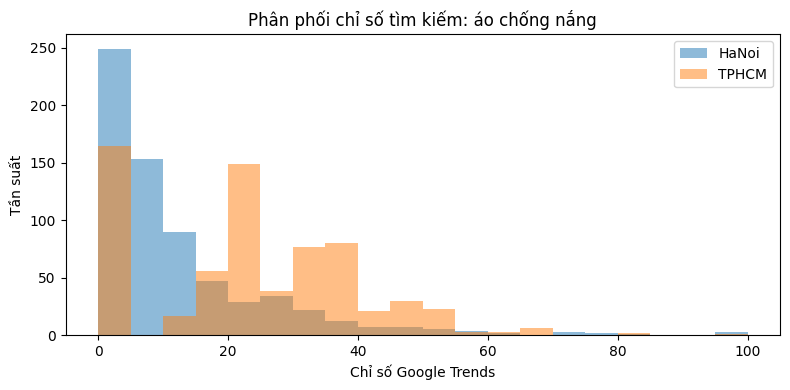

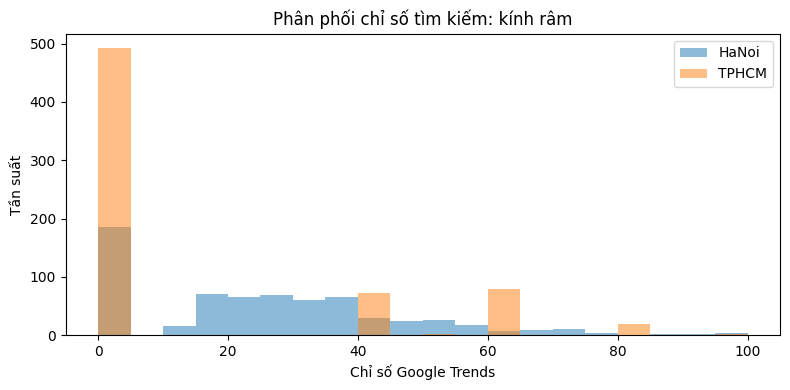

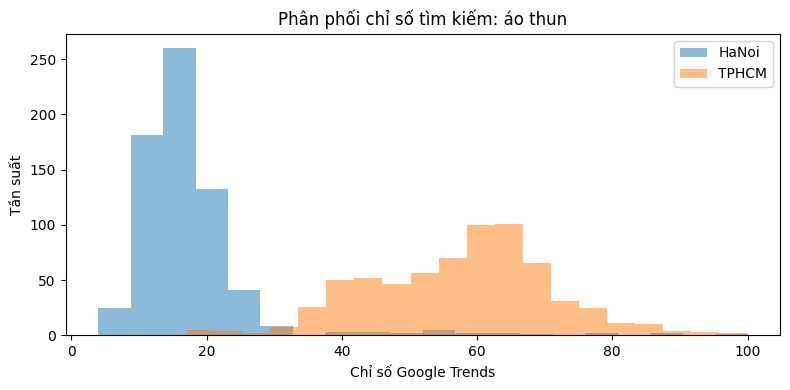

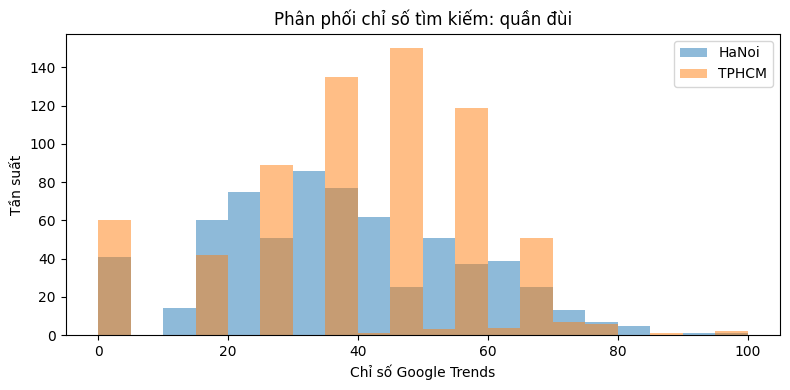

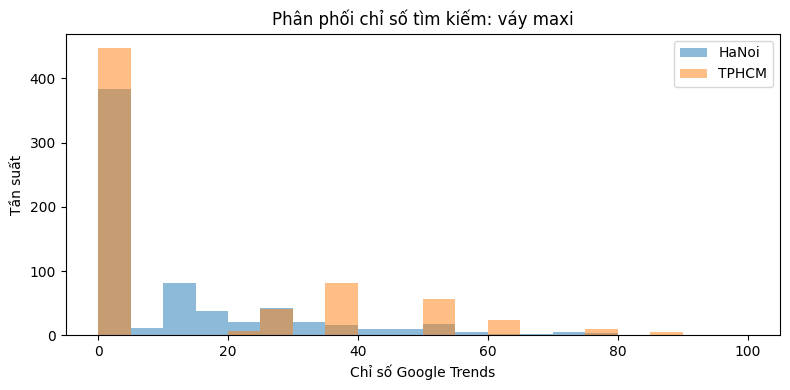

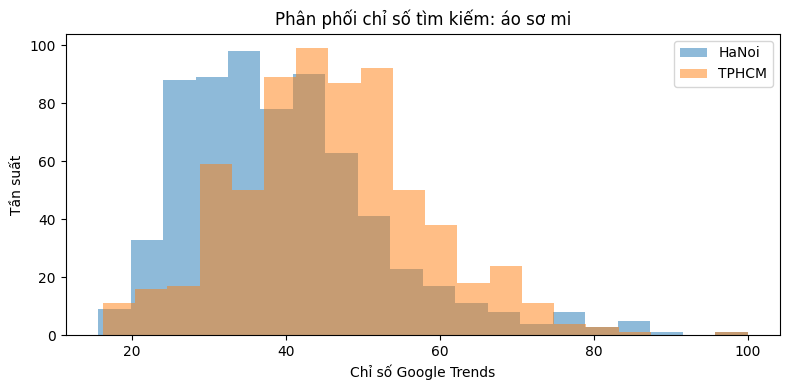

In [20]:
#3.2 Phân phối dữ liệu

#Histogram
# Chọn các từ khóa thời trang để minh họa
selected_trends = trend_cols[:6]

for col in selected_trends:

    plt.figure(figsize=(8, 4))

    for city in df_all["CityName"].unique():

        data = df_all.loc[
            df_all["CityName"] == city, col
        ].dropna()

        plt.hist(
            data,
            bins=20,
            alpha=0.5,
            label=city
        )

    plt.title(f"Phân phối chỉ số tìm kiếm: {col}")
    plt.xlabel("Chỉ số Google Trends")
    plt.ylabel("Tần suất")
    plt.legend()
    plt.tight_layout()
    plt.show()

## Xem chỉ số tìm kiếm thời trang phân bố như thế nào giữa các khí hậu
So sánh phân phối chỉ số tìm kiếm của từng từ khóa giữa các mùa khí hậu trong cùng một thành phố.

Dựa theo date(tháng) để xác định mỗi quan sát thuộc mùa nào:
- Hà Nội: chia mùa nóng: tháng 5-9, mùa lạnh: 11-3, chuyển tiếp: tháng 4-10
- HCM: Mùa mưa: tháng 5-11, mùa khô: 12-4
(Quy ước dựa trên đặc điểm khí hậu thông thường, không phải xác định trực tiếp từ nhiệt độ và lượng mưa thực tế theo tuần)

In [21]:
# Lấy tháng từ cột ngày
df_all["Month"] = df_all["date"].dt.month

# Hàm xác định mùa theo từng thành phố
def classify_season(row):

    city = row["CityName"]
    month = row["Month"]

    if city == "HaNoi":
        if month in [5, 6, 7, 8, 9]:
            return "Mua nong"
        elif month in [11, 12, 1, 2, 3]:
            return "Mua lanh"
        else:
            return "Chuyen tiep"

    elif city == "TPHCM":
        if month in [5, 6, 7, 8, 9, 10, 11]:
            return "Mua mua"
        else:
            return "Mua kho"

# Tạo cột mùa
df_all["Season"] = df_all.apply(classify_season, axis=1)

# Kiểm tra kết quả
display(
    df_all[["CityName", "date", "Month", "Season"]].head(20)
)

,CityName,date,Month,Season
0,HaNoi,2013-12-29,12,Mua lanh
1,HaNoi,2014-01-05,1,Mua lanh
2,HaNoi,2014-01-12,1,Mua lanh
3,HaNoi,2014-01-19,1,Mua lanh
4,HaNoi,2014-01-26,1,Mua lanh
5,HaNoi,2014-02-02,2,Mua lanh
6,HaNoi,2014-02-09,2,Mua lanh
7,HaNoi,2014-02-16,2,Mua lanh
8,HaNoi,2014-02-23,2,Mua lanh
9,HaNoi,2014-03-02,3,Mua lanh


In [22]:
# Kiểm tra số lượng quan sát theo thành phố và mùa
season_counts = pd.crosstab(
    df_all["CityName"],
    df_all["Season"]
)

display(season_counts)

Season,Chuyen tiep,Mua kho,Mua lanh,Mua mua,Mua nong
CityName,,,,,
HaNoi,112,0,274,0,284
TPHCM,0,277,0,393,0


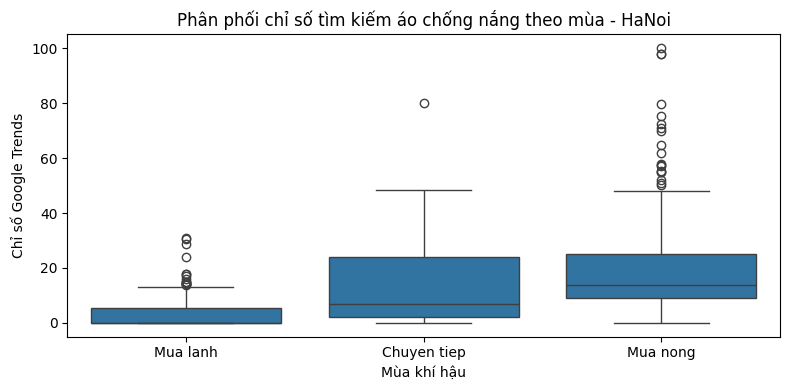

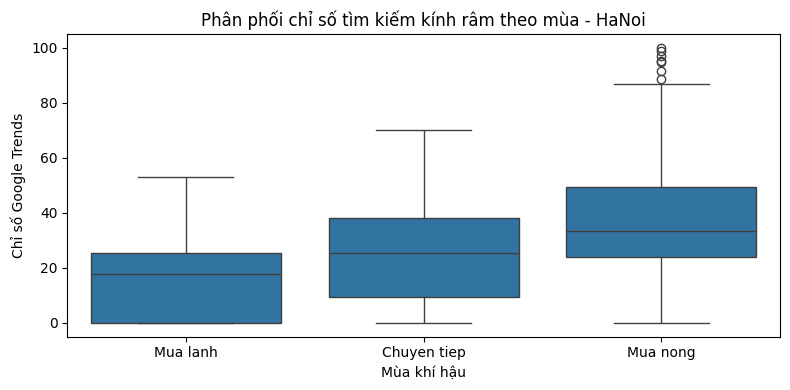

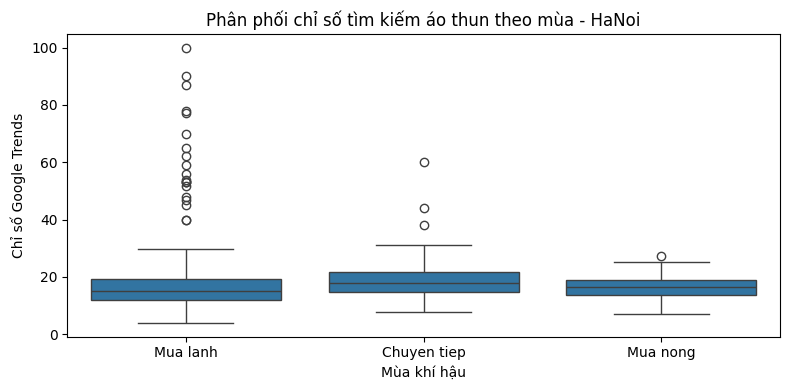

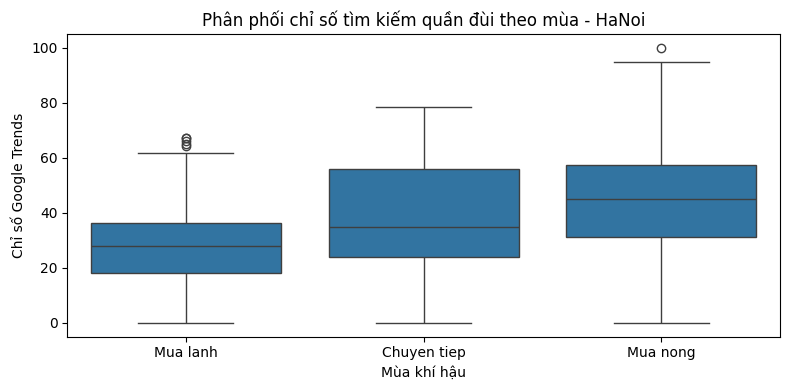

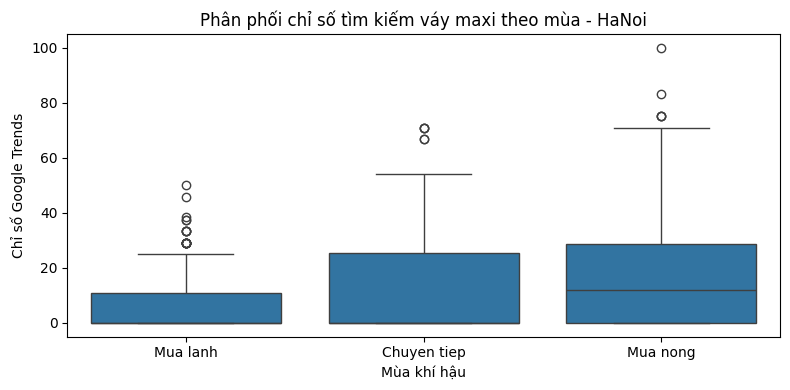

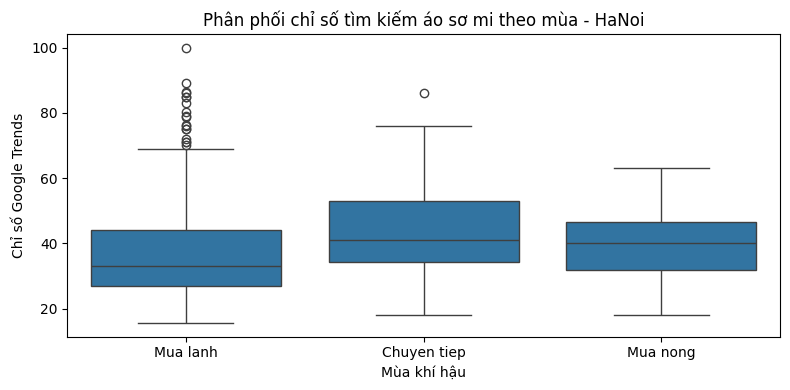

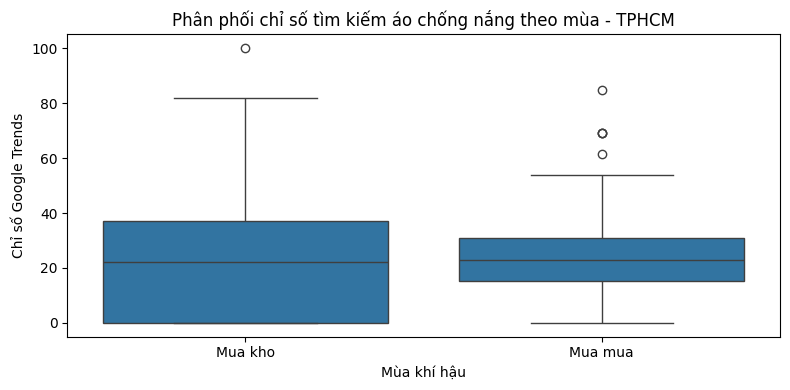

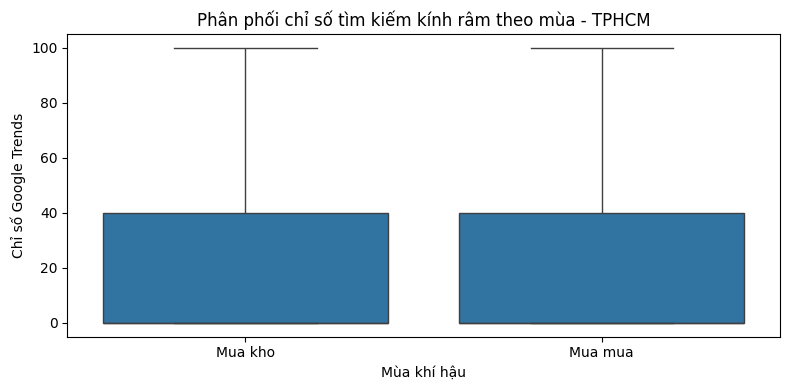

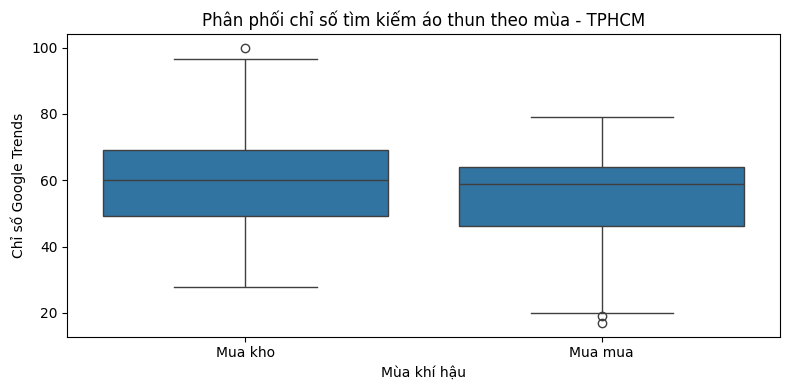

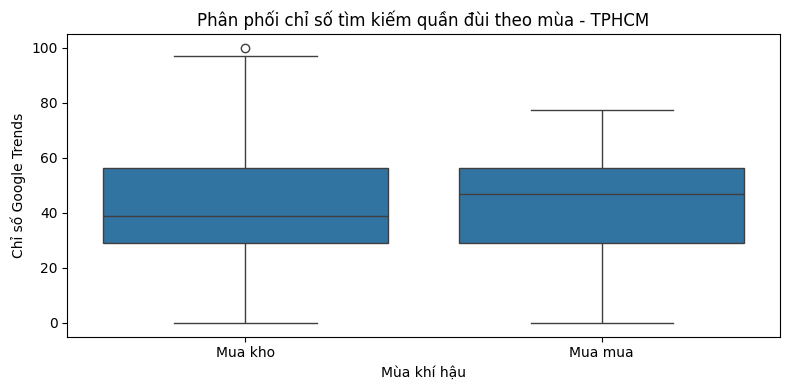

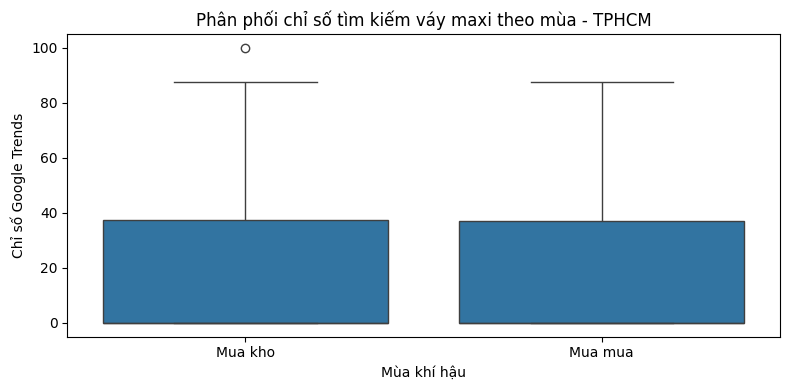

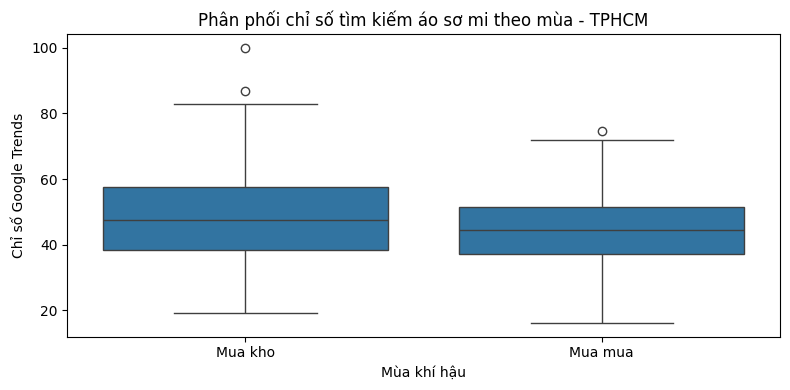

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# Chọn 6 biến Google Trends để phân tích
selected_trends = trend_cols[:6]

# Thứ tự mùa hiển thị
season_order = {
    "HaNoi": ["Mua lanh", "Chuyen tiep", "Mua nong"],
    "TPHCM": ["Mua kho", "Mua mua"],
}

# Vẽ biểu đồ theo từng thành phố và từng từ khóa
for city in df_all["CityName"].unique():

    df_city = df_all[df_all["CityName"] == city]

    for col in selected_trends:

        plt.figure(figsize=(8, 4))

        sns.boxplot(
            data=df_city,
            x="Season",  #TRục ngang thể hiện các mùa khí hậu
            y=col,          #Trục dọc thể hiện chỉ số tìm kiếm của từ khóa
            order=season_order[city]
        )

        plt.title(f"Phân phối chỉ số tìm kiếm {col} theo mùa - {city}")
        plt.xlabel("Mùa khí hậu")
        plt.ylabel("Chỉ số Google Trends")
        plt.tight_layout()
        plt.show()

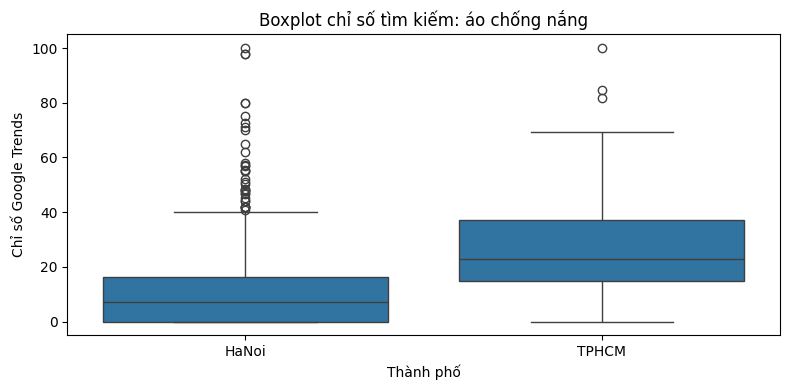

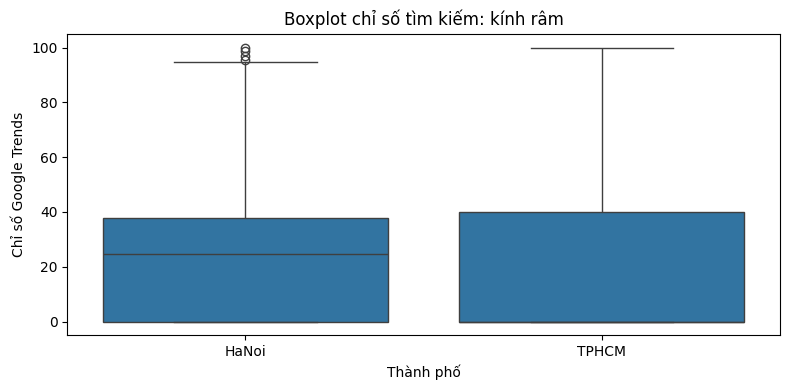

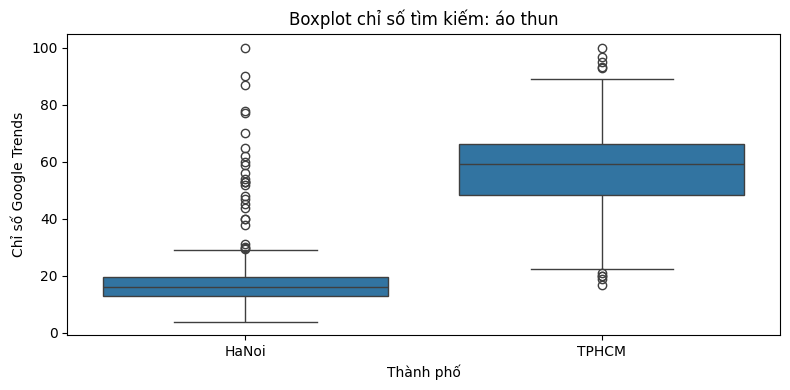

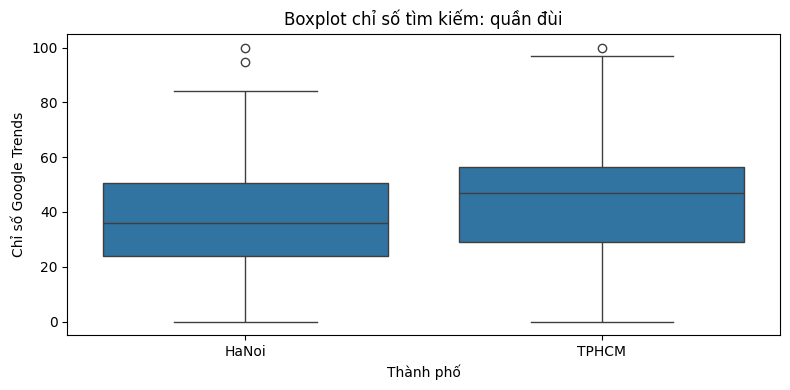

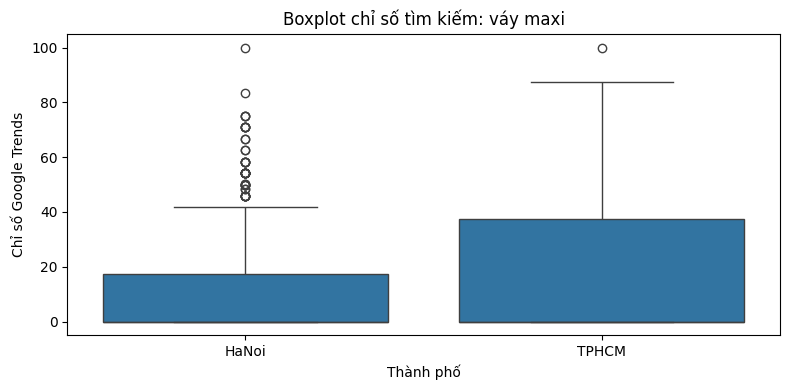

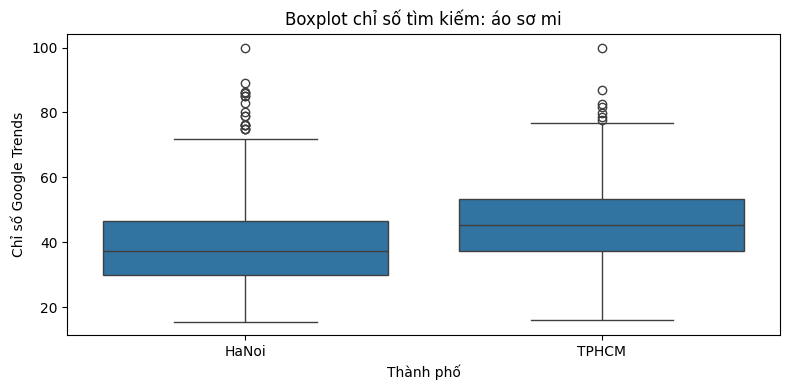

In [24]:
#Xem sự phân bố mức tìm kiếm các biến thời trang ở hai nơi
for col in selected_trends:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=df_all,
        x="CityName",
        y=col
    )

    plt.title(f"Boxplot chỉ số tìm kiếm: {col}")
    plt.xlabel("Thành phố")
    plt.ylabel("Chỉ số Google Trends")
    plt.tight_layout()
    plt.show()

In [25]:
#Phân tích độ lệch và độ nhọn

for city, data in df_all.groupby("CityName"):
    print(f"THỐNG KÊ PHÂN PHỐI: {city}")

    distribution_stats = data[trend_cols].agg(
        ["mean", "median", "std", "skew", "kurt"]
    ).T

    display(distribution_stats.round(3))

THỐNG KÊ PHÂN PHỐI: HaNoi


,mean,median,std,skew,kurt
áo chống nắng,11.684,7.170,14.983,2.308,7.384
kính râm,25.178,24.700,21.054,0.671,0.337
áo thun,17.615,16.085,9.678,4.208,24.371
quần đùi,36.932,36.140,18.716,0.197,-0.177
váy maxi,11.530,0.000,17.340,1.726,2.820
áo sơ mi,39.625,37.270,13.063,1.132,1.775
đồ bơi,20.583,12.770,21.888,1.421,1.550
dép sandal,17.002,0.000,20.377,0.823,-0.322
áo mưa,19.402,16.000,13.003,2.170,6.769
ô dù,17.837,0.000,23.557,0.819,-0.702


THỐNG KÊ PHÂN PHỐI: TPHCM


,mean,median,std,skew,kurt
áo chống nắng,23.308,23.03,17.112,0.328,0.168
kính râm,14.635,0.00,25.423,1.362,0.335
áo thun,57.534,59.17,13.264,-0.121,0.163
quần đùi,41.221,46.87,18.630,-0.564,0.222
váy maxi,14.528,0.00,22.412,1.263,0.469
áo sơ mi,45.774,45.41,12.269,0.350,0.461
đồ bơi,31.496,28.97,15.473,0.668,0.539
dép sandal,30.270,0.00,34.714,0.471,-1.403
áo mưa,25.882,20.63,17.748,1.250,1.738
ô dù,11.304,0.00,20.562,1.486,0.819


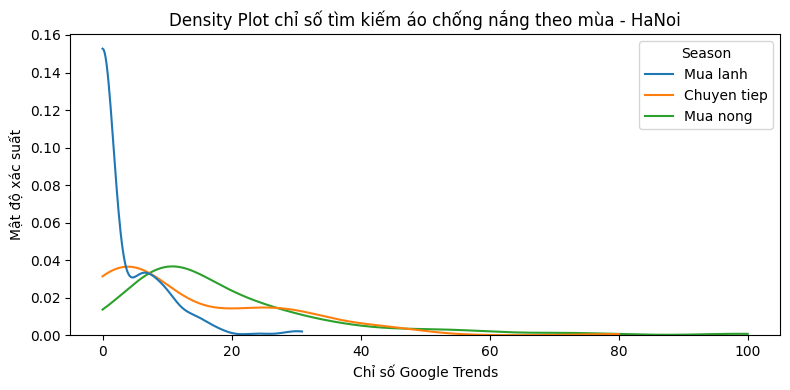

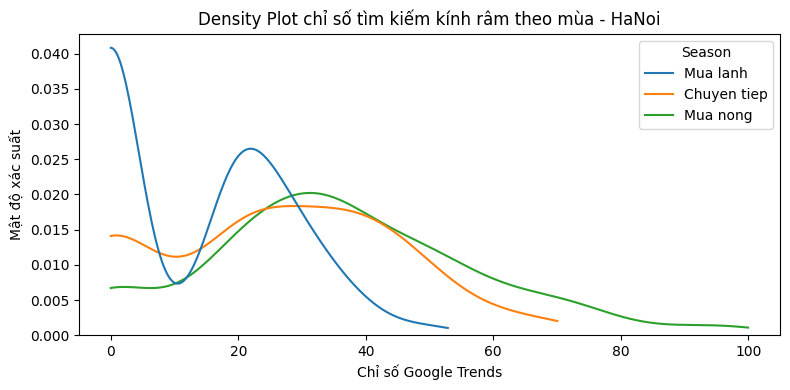

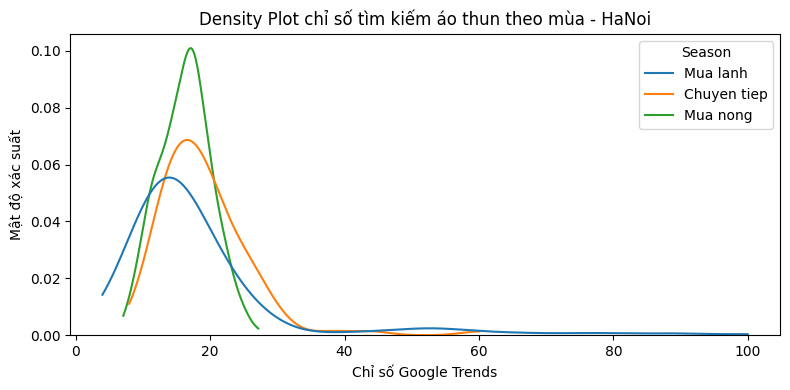

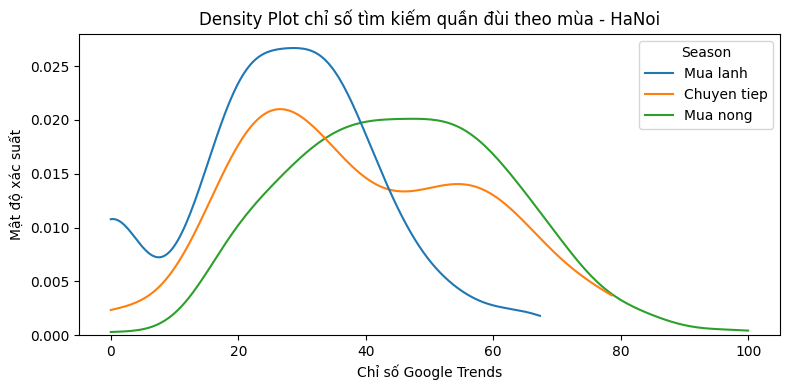

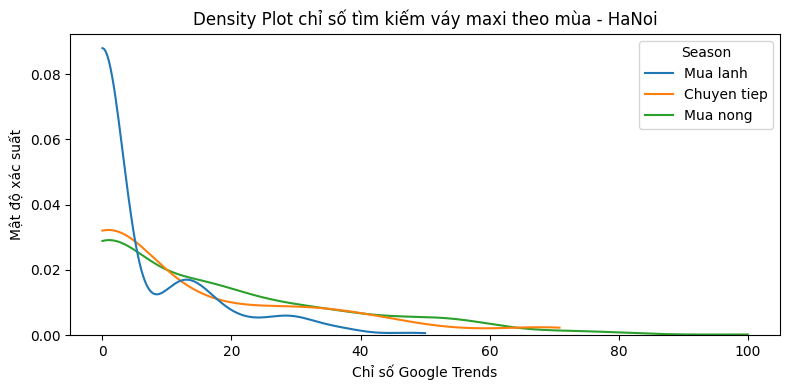

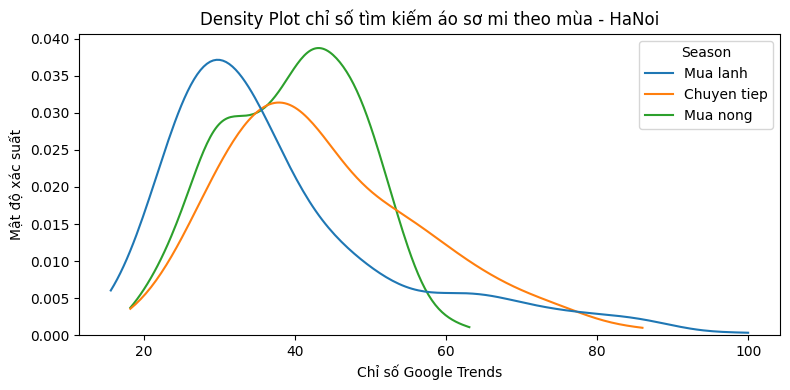

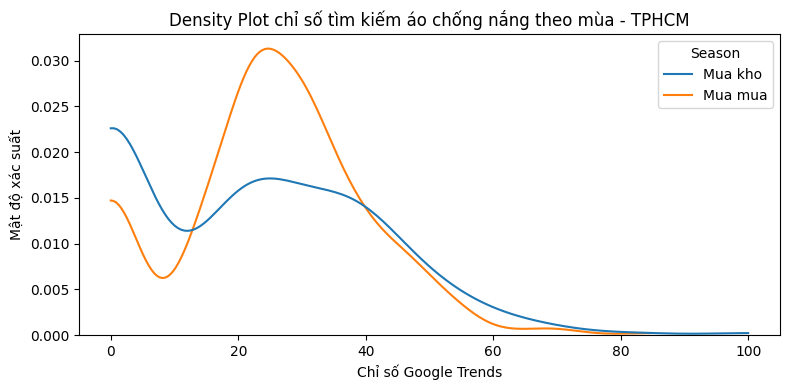

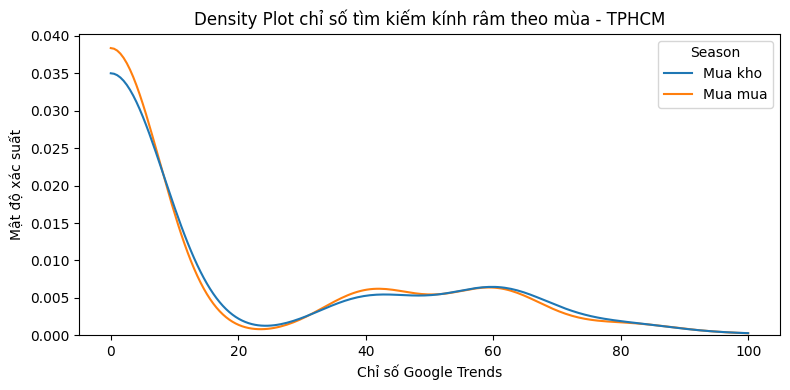

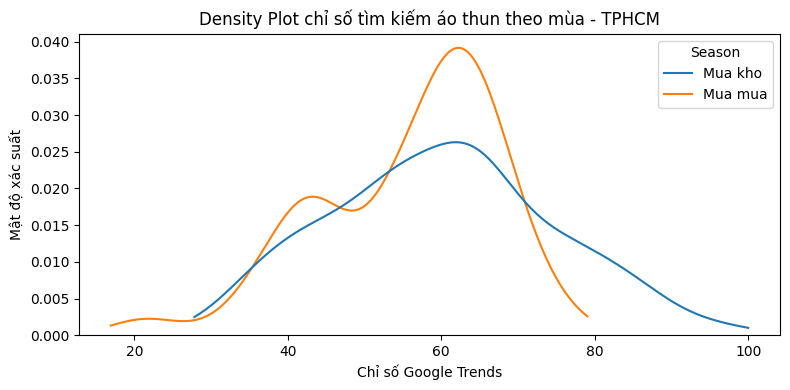

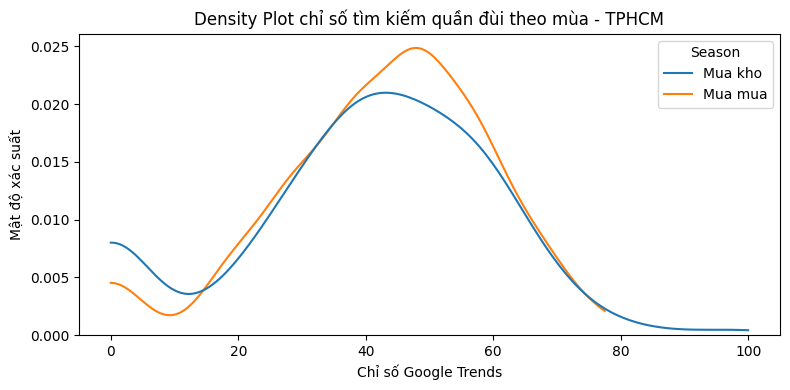

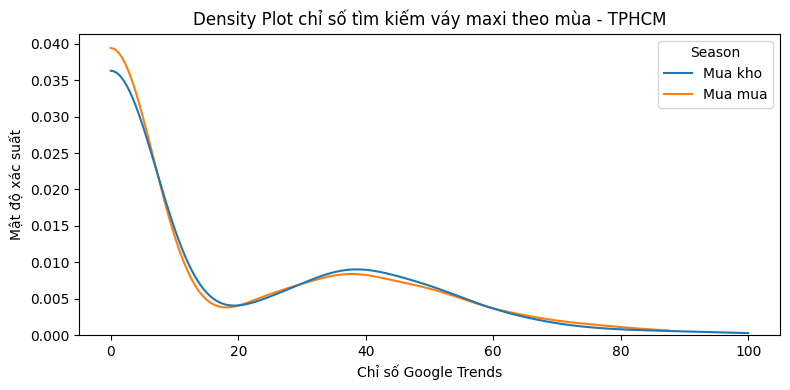

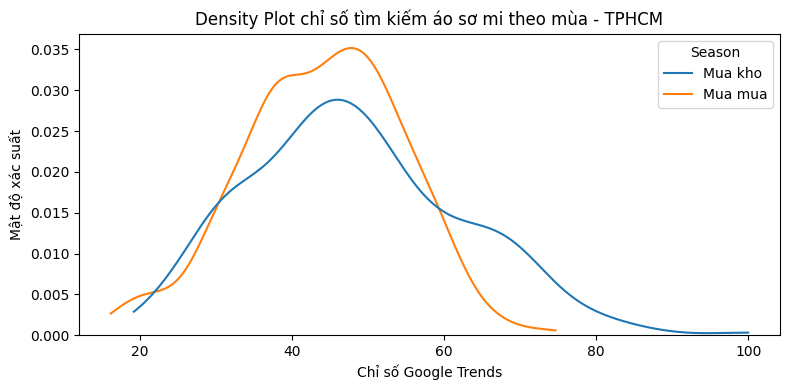

In [26]:
#Density
# Density Plot: Phân phối chỉ số tìm kiếm theo mùa khí hậu

for city in df_all["CityName"].unique():

    df_city = df_all[df_all["CityName"] == city]

    for col in selected_trends:

        plt.figure(figsize=(8, 4))

        sns.kdeplot(
            data=df_city,
            x=col,
            hue="Season",
            common_norm=False,
            fill=False,
            bw_adjust=1,
            cut=0,
            clip=(0, 100)
        )

        plt.title(f"Density Plot chỉ số tìm kiếm {col} theo mùa - {city}")
        plt.xlabel("Chỉ số Google Trends")
        plt.ylabel("Mật độ xác suất")
        plt.tight_layout()
        plt.show()


Đã lưu biểu đồ lưới của HaNoi tại: /content/density_grid_HaNoi.png


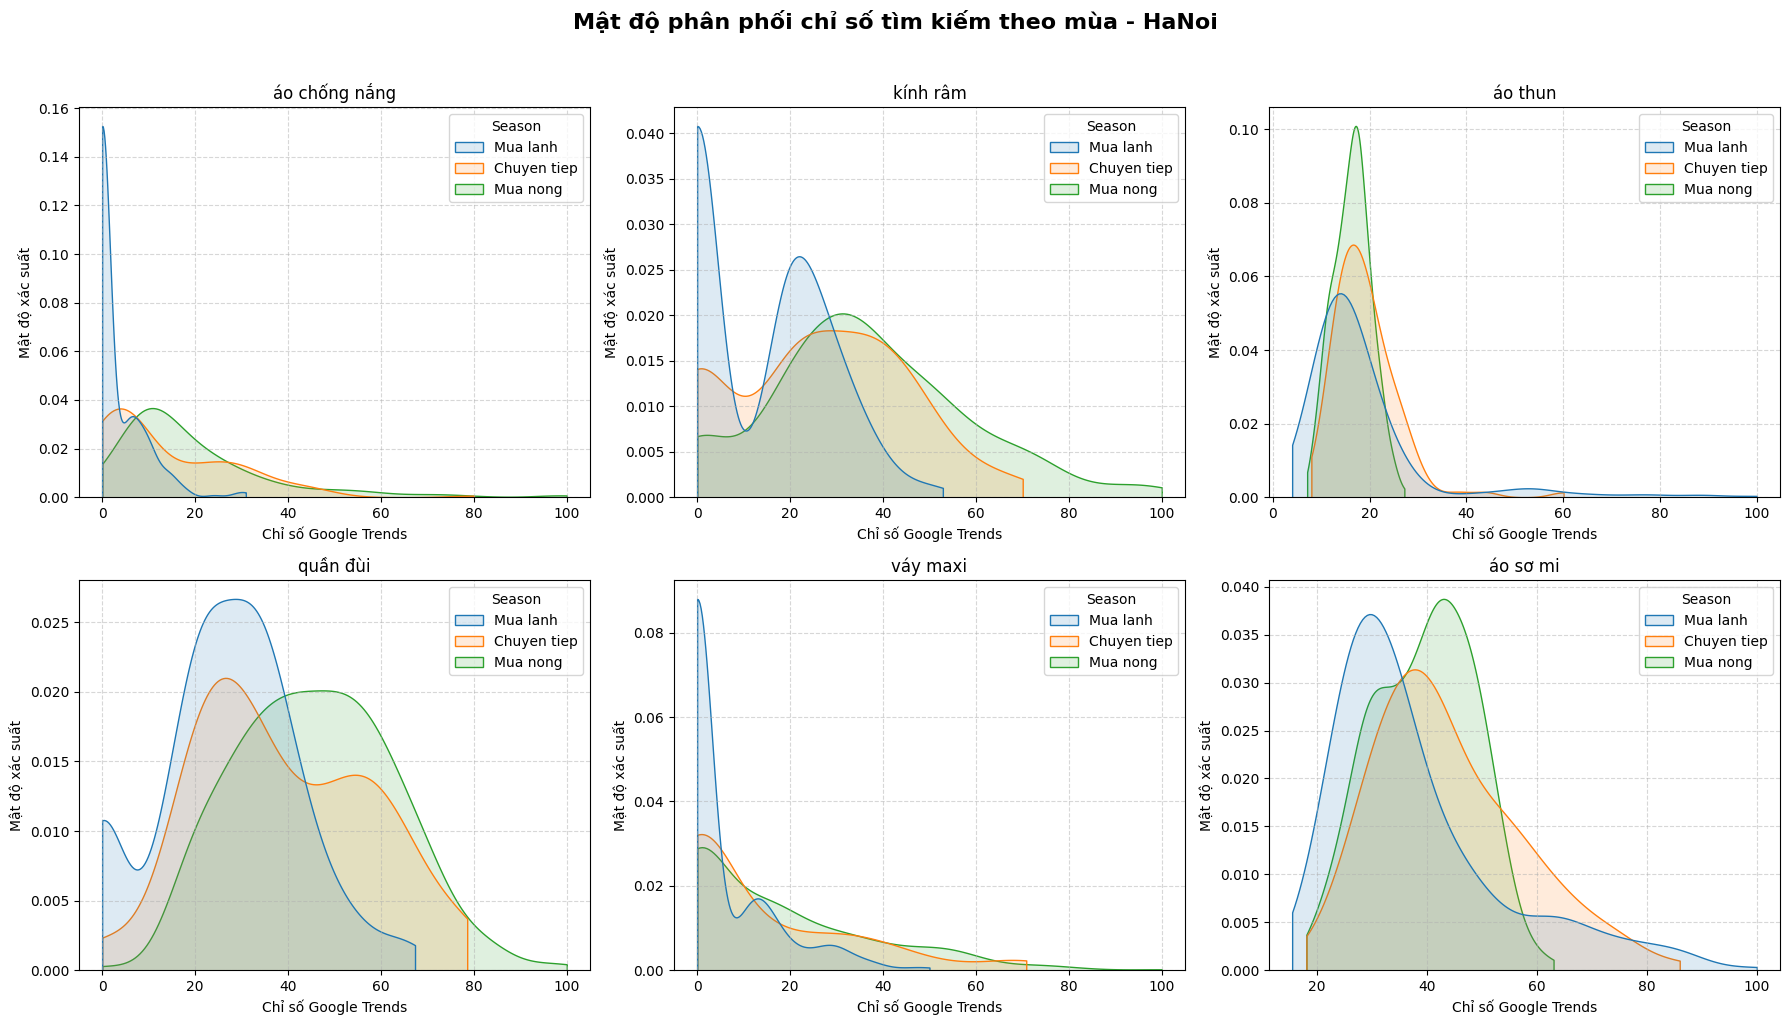

Đã lưu biểu đồ lưới của TPHCM tại: /content/density_grid_TPHCM.png


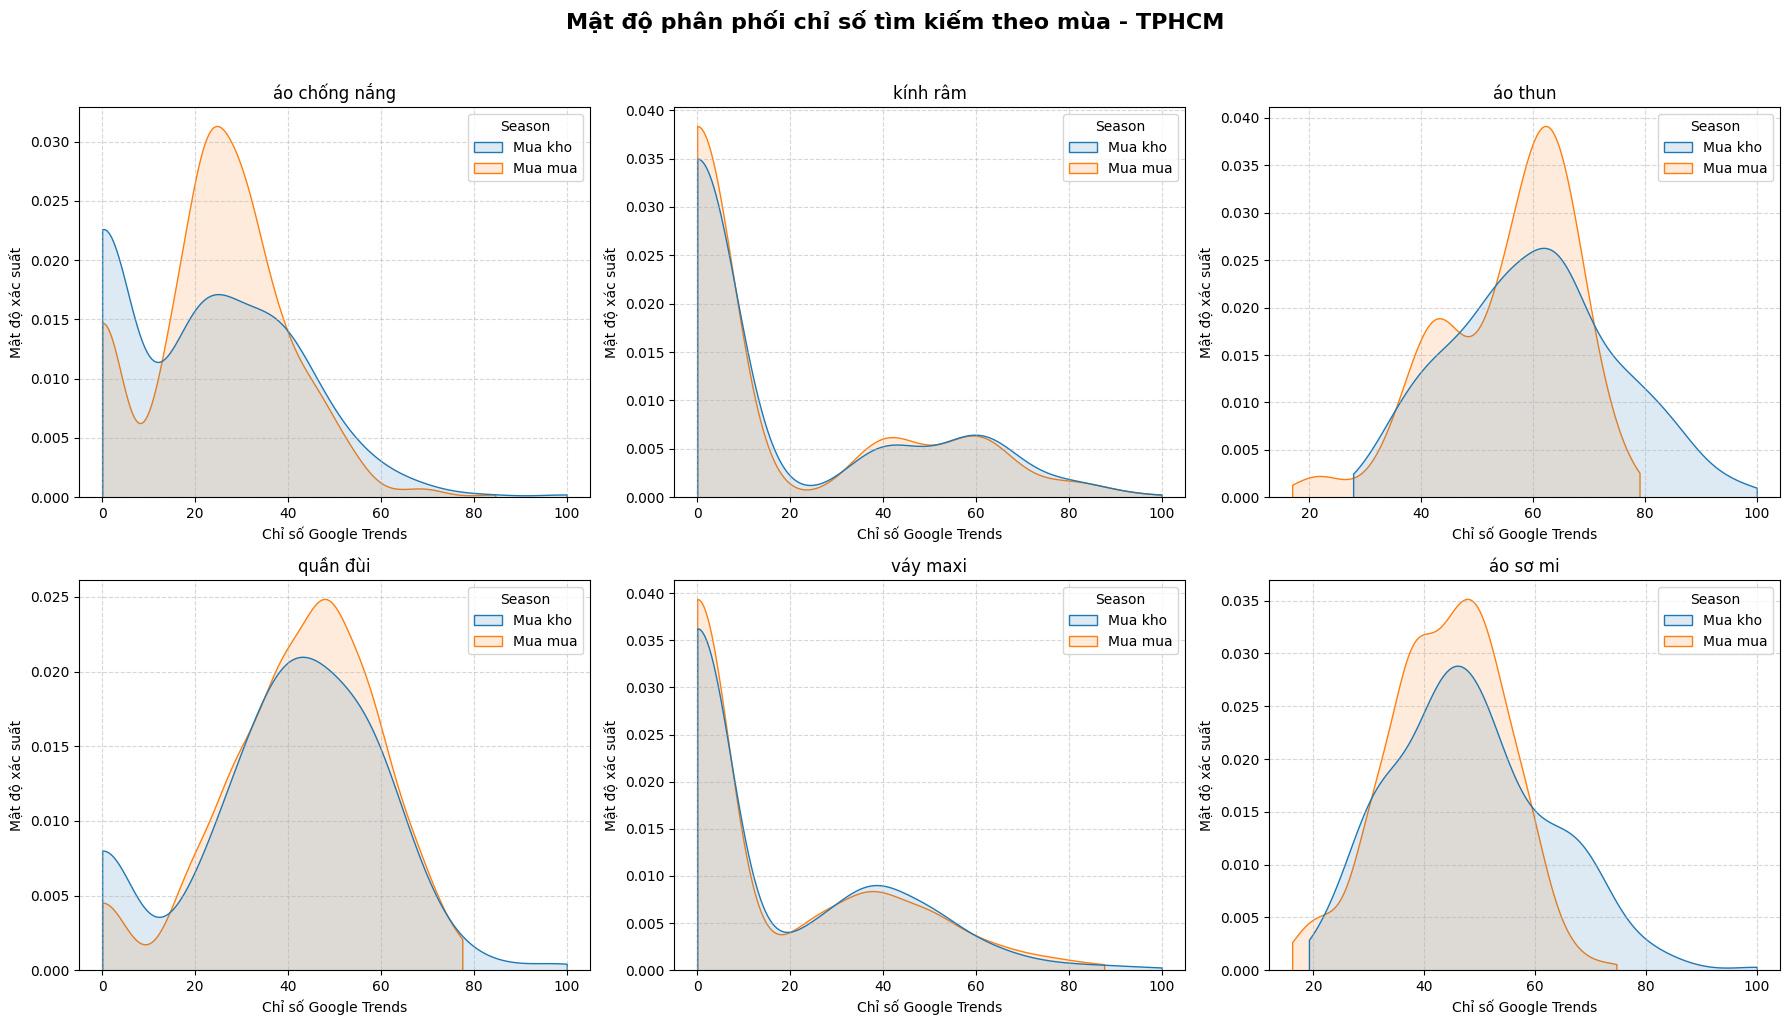

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# Chọn 6 từ khóa thời trang đầu tiên
selected_trends = trend_cols[:6]

# Vẽ biểu đồ gộp theo từng thành phố
for city in df_all["CityName"].unique():
    df_city = df_all[df_all["CityName"] == city]

    # Tạo lưới 2 hàng 3 cột cho mỗi thành phố
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()

    for idx, col in enumerate(selected_trends):
        ax = axes[idx]
        sns.kdeplot(
            data=df_city,
            x=col,
            hue="Season",
            common_norm=False,
            fill=True,
            alpha=0.15,
            bw_adjust=1,
            cut=0,
            clip=(0, 100),
            ax=ax
        )
        ax.set_title(f"{col}", fontsize=12)
        ax.set_xlabel("Chỉ số Google Trends")
        ax.set_ylabel("Mật độ xác suất")
        ax.grid(True, linestyle="--", alpha=0.5)

    plt.suptitle(f"Mật độ phân phối chỉ số tìm kiếm theo mùa - {city}", fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()

    # Lưu ảnh chất lượng cao để chèn slide
    filename = f"/content/density_grid_{city}.png"
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"Đã lưu biểu đồ lưới của {city} tại: {filename}")
    plt.show()

Nhận xét:

Tại Hà Nội, các mặt hàng mang tính mùa vụ rõ rệt (như áo chống nắng, quần short) có sự dịch chuyển phân phối cực kỳ rõ nét giữa mùa lạnh và mùa nóng.

Tại TP.HCM, các trang phục cơ bản (như áo thun, quần short) giữ nguyên phân phối ổn định ở vùng giá trị cao qua các mùa, phản ánh đặc thù khí hậu hai mùa mưa - khô ôn hòa hơn.

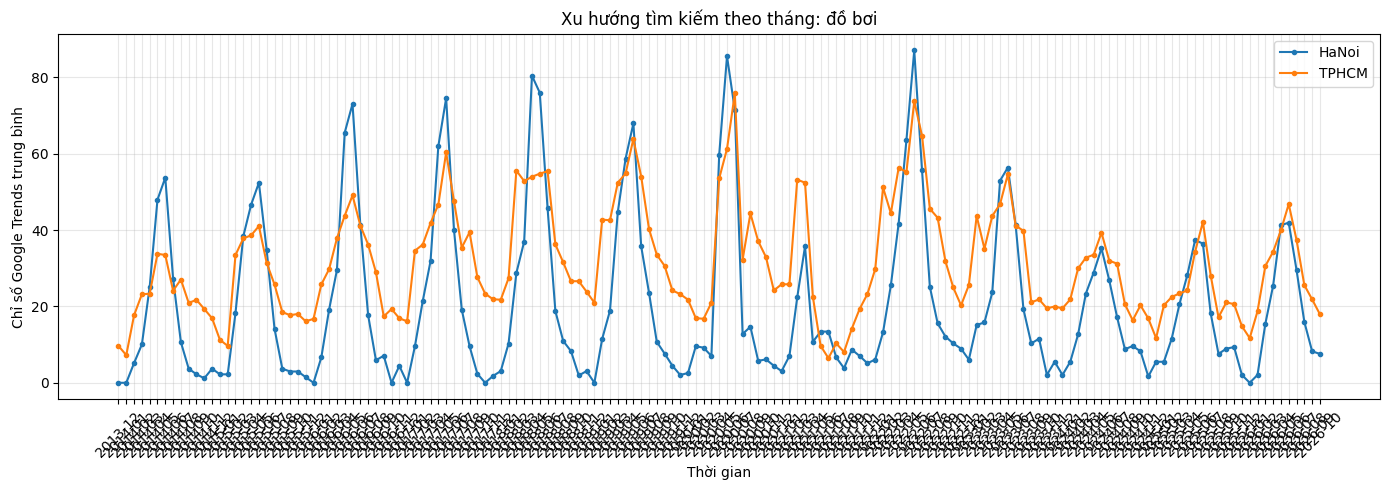

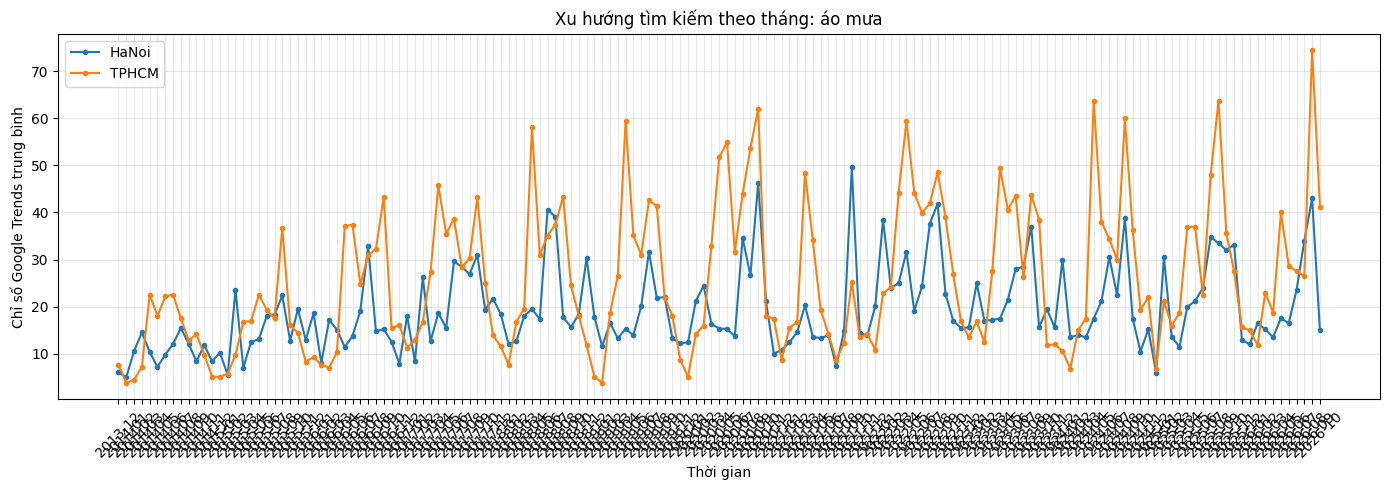

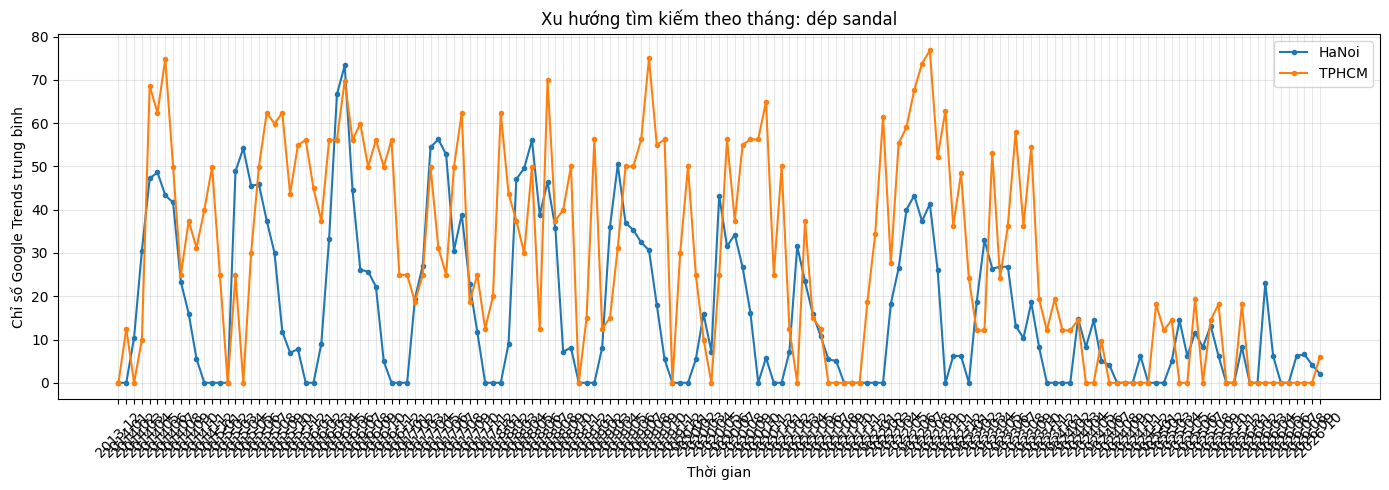

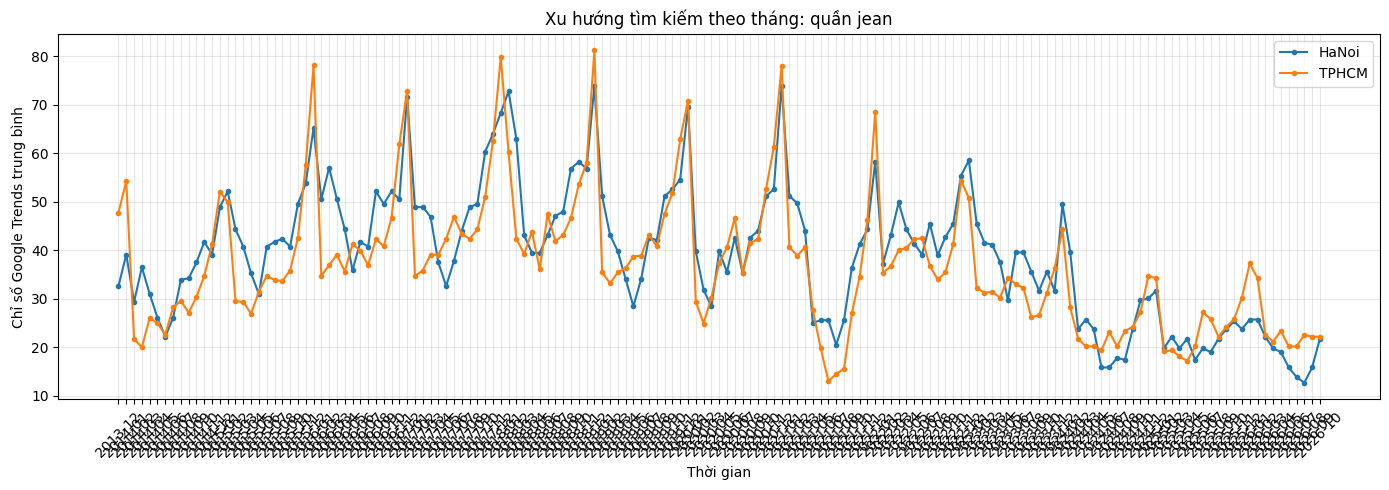

In [28]:
#Chọn các biến: Đồ bơi, Áo mưa, Dép sandal, Quần jeans
#3.3. Phân tích xu hướng tìm kiếm thời trang theo thời gian
#1. Xu hướng tìm kiếm theo tháng và năm
# Tạo cột tháng
df_all["YearMonth"] = df_all["date"].dt.to_period("M")

# Tính trung bình chỉ số tìm kiếm theo tháng và thành phố
monthly_trend = (
    df_all.groupby(["CityName", "YearMonth"])[trend_cols]
    .mean()
    .reset_index()
)

# Chuyển YearMonth về dạng chuỗi để vẽ biểu đồ
monthly_trend["YearMonth"] = (
    monthly_trend["YearMonth"].astype(str)
)

# Chọn một số từ khóa để hiển thị (được sửa thành dạng chuỗi hợp lệ)
selected_trends = ["đồ bơi", "áo mưa", "dép sandal", "quần jean"]

for col in selected_trends:

    plt.figure(figsize=(14, 5))

    for city in monthly_trend["CityName"].unique():

        city_data = monthly_trend[
            monthly_trend["CityName"] == city
        ]

        plt.plot(
            city_data["YearMonth"],
            city_data[col],
            marker="o",
            markersize=3,
            label=city
        )

    plt.title(f"Xu hướng tìm kiếm theo tháng: {col}")
    plt.xlabel("Thời gian")
    plt.ylabel("Chỉ số Google Trends trung bình")
    plt.xticks(rotation=45)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [29]:
#theo năm
# Tính trung bình chỉ số tìm kiếm theo năm
yearly_trend = (
    df_all.groupby(
        ["CityName", df_all["date"].dt.year]
    )[trend_cols]
    .mean()
    .reset_index()
)

yearly_trend = yearly_trend.rename(
    columns={"date": "Year"}
)

print("===== XU HƯỚNG TÌM KIẾM THEO NĂM =====")

display(yearly_trend.round(2))

===== XU HƯỚNG TÌM KIẾM THEO NĂM =====


,CityName,Year,áo chống nắng,kính râm,áo thun,quần đùi,váy maxi,áo sơ mi,đồ bơi,dép sandal,...,quần âu,quần short,giày tây,quần kaki,giày sneaker,váy hoa,áo vest,dép lào,dép quai hậu,mũ len
0,HaNoi,2013,0.00,0.00,7.12,0.00,0.00,19.00,0.00,0.00,...,16.97,0.00,0.00,35.71,0.00,11.01,49.00,0.00,0.00,61.00
1,HaNoi,2014,4.93,13.27,16.13,16.45,29.89,46.63,16.13,22.38,...,24.32,18.92,6.48,39.77,6.40,39.05,30.21,0.00,7.86,16.63
2,HaNoi,2015,11.32,19.63,19.41,22.12,26.52,48.56,18.51,24.73,...,32.26,25.71,9.60,60.99,14.32,42.49,30.38,0.00,11.19,13.73
3,HaNoi,2016,12.31,21.73,17.88,32.32,21.80,49.60,23.00,25.53,...,43.90,32.06,12.95,58.48,20.61,37.99,28.42,1.59,21.17,12.19
4,HaNoi,2017,13.29,22.18,18.09,37.86,17.30,46.12,22.01,25.52,...,49.93,26.43,29.15,50.03,33.24,39.99,26.68,1.56,24.77,8.49
5,HaNoi,2018,15.81,26.23,17.69,36.66,15.28,48.54,26.81,24.91,...,53.41,28.92,36.09,49.97,48.32,39.44,25.53,4.49,24.17,8.53
6,HaNoi,2019,14.71,20.43,16.94,34.07,11.92,40.27,23.92,21.21,...,45.36,29.38,34.33,47.71,53.02,31.83,23.46,0.00,18.96,4.18
7,HaNoi,2020,15.56,27.89,16.55,40.38,8.32,35.58,23.92,16.08,...,45.63,29.09,33.75,40.82,49.87,44.52,24.31,0.00,23.44,5.98
8,HaNoi,2021,10.85,17.64,15.48,41.55,3.47,31.76,11.10,8.04,...,47.46,27.46,28.79,33.91,38.78,34.48,21.20,6.37,3.85,5.69
9,HaNoi,2022,12.99,35.91,16.71,49.47,8.73,41.53,30.72,20.34,...,64.09,44.12,50.54,42.34,43.93,43.38,24.27,2.32,30.37,5.44


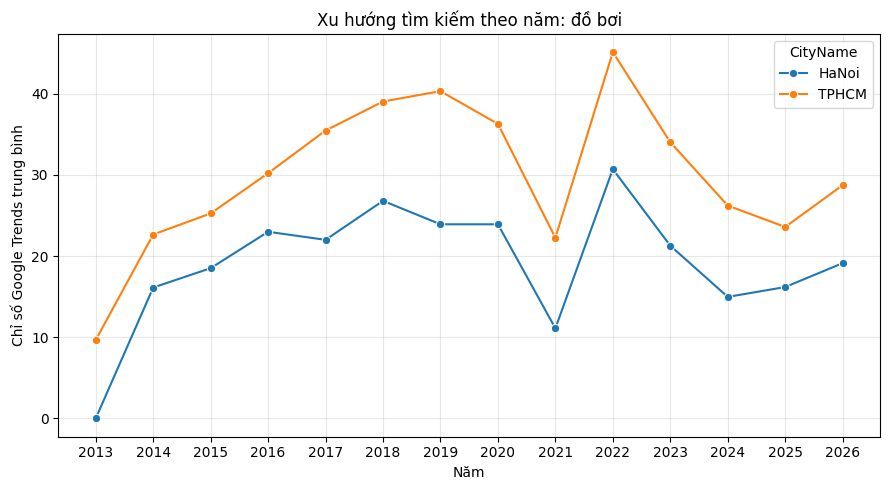

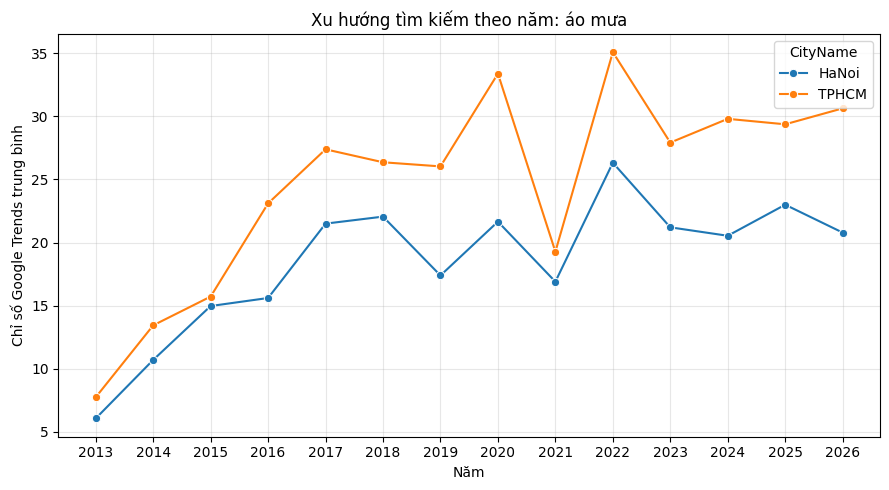

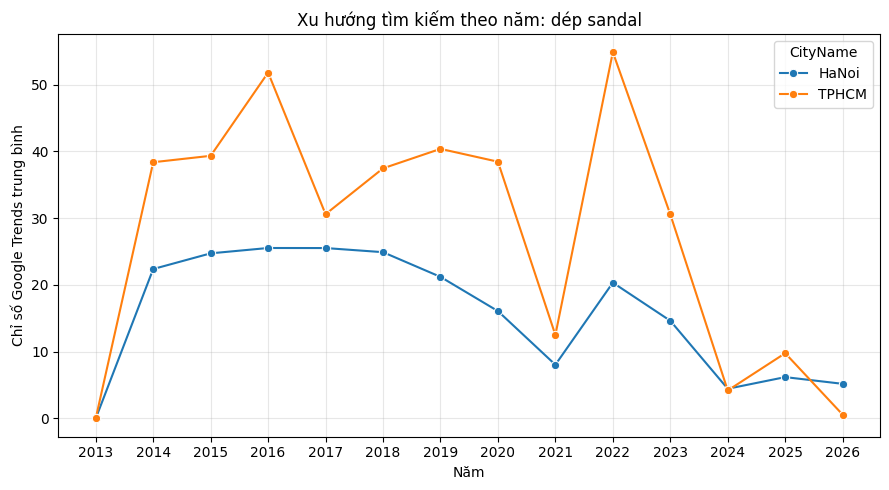

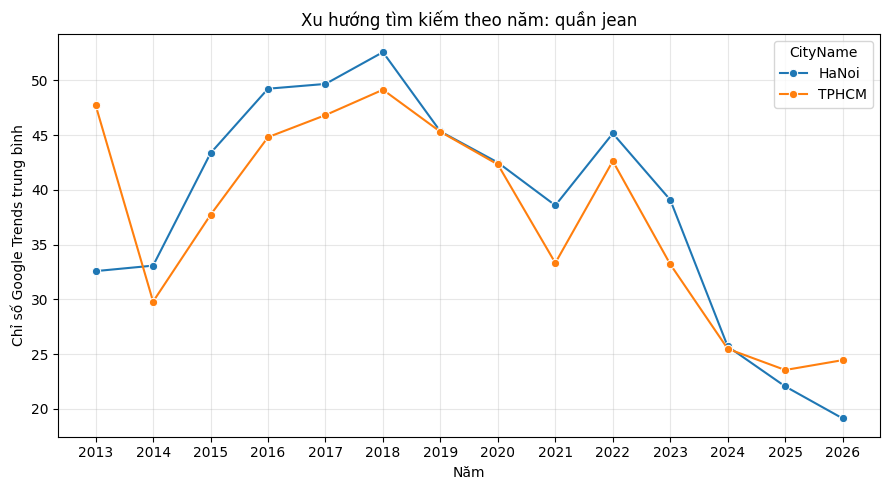

In [30]:
for col in selected_trends:

    plt.figure(figsize=(9, 5))

    sns.lineplot(
        data=yearly_trend,
        x="Year",
        y=col,
        hue="CityName",
        marker="o"
    )

    plt.title(f"Xu hướng tìm kiếm theo năm: {col}")
    plt.xlabel("Năm")
    plt.ylabel("Chỉ số Google Trends trung bình")
    plt.xticks(sorted(df_all["date"].dt.year.unique()))
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

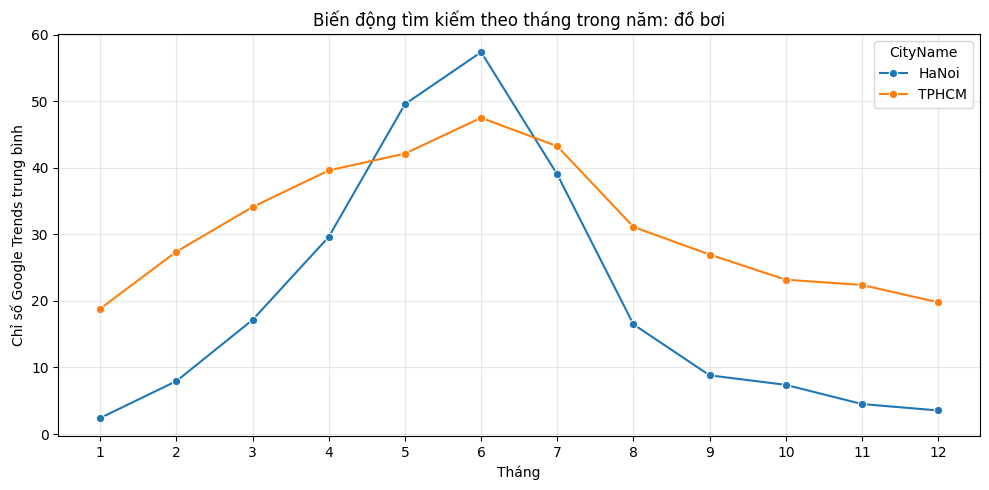

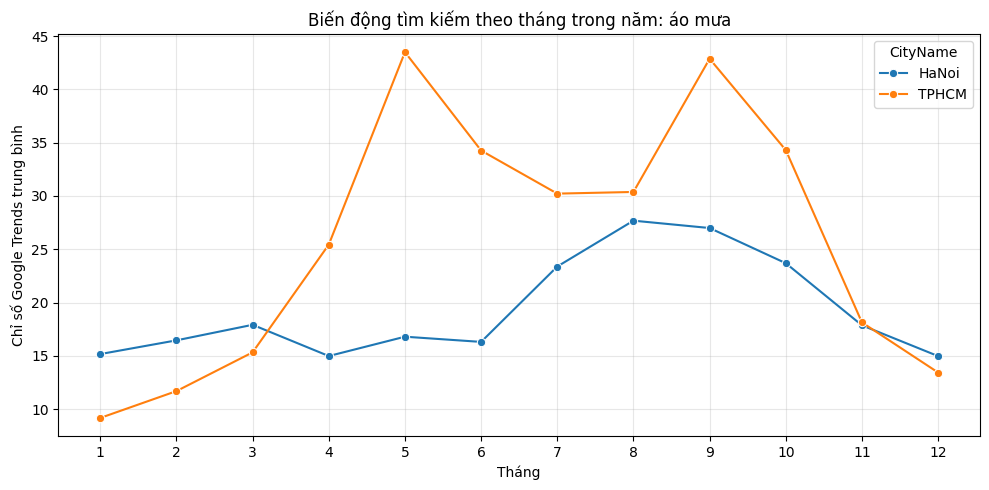

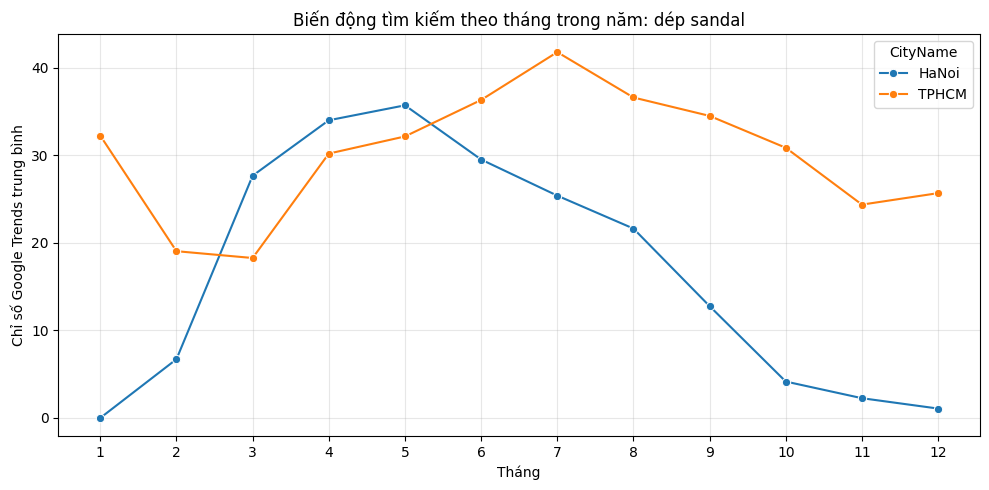

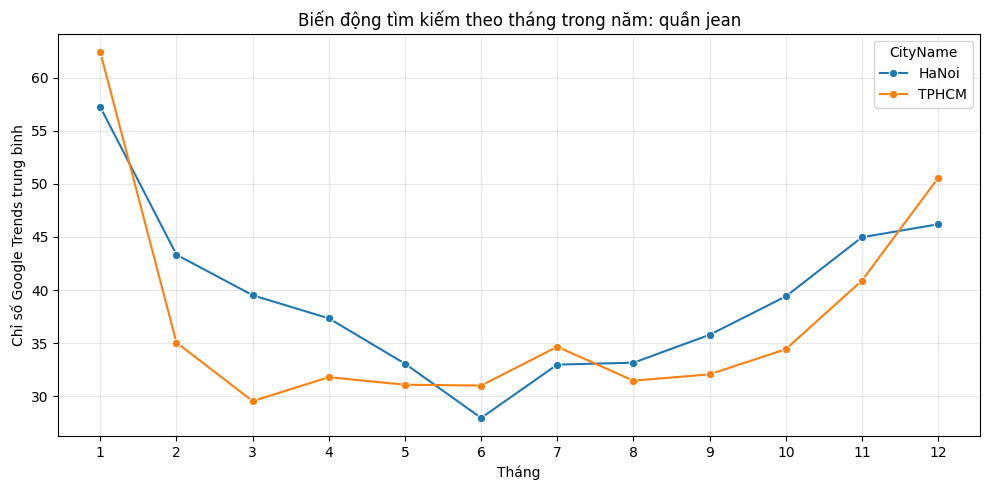

In [31]:
#3.3.2 Biến động xu hướng tìm kiếm theo mùa
# kiểm tra liệu các từ khóa thời trang có mức độ quan tâm khác nhau giữa các thời điểm trong năm hay không.
df_all["Month"] = df_all["date"].dt.month

# Tính mức tìm kiếm trung bình theo tháng trong năm
seasonal_trend = (
    df_all.groupby(["CityName", "Month"])[trend_cols]
    .mean()
    .reset_index()
)

for col in selected_trends:

    plt.figure(figsize=(10, 5))

    sns.lineplot(
        data=seasonal_trend,
        x="Month",
        y=col,
        hue="CityName",
        marker="o"
    )

    plt.title(f"Biến động tìm kiếm theo tháng trong năm: {col}")
    plt.xlabel("Tháng")
    plt.ylabel("Chỉ số Google Trends trung bình")
    plt.xticks(range(1, 13))
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [32]:
#3.3.3 Nhận diện các giai đoạn tăng trưởng và đột biến:
# Chọn từ khóa cần kiểm tra
keyword = selected_trends[0]

spike_results = []

for city in df_all["CityName"].unique():

    city_df = df_all[
        df_all["CityName"] == city
    ].copy()

    mean_value = city_df[keyword].mean()
    std_value = city_df[keyword].std()

    city_df["Z_score"] = (
        city_df[keyword] - mean_value
    ) / std_value

    # Lấy các tuần có Z-score lớn hơn 2
    spikes = city_df[
        city_df["Z_score"] > 2
    ][["date", keyword, "Z_score"]]

    spikes["CityName"] = city

    spike_results.append(spikes)

spike_df = pd.concat(
    spike_results,
    ignore_index=True
)

display(spike_df.sort_values(
    "Z_score",
    ascending=False
))

,date,đồ bơi,Z_score,CityName
49,2020-07-19,100.00,4.427286,TPHCM
14,2018-06-03,100.00,3.628356,HaNoi
54,2022-06-26,87.24,3.602636,TPHCM
48,2020-07-12,87.10,3.593589,TPHCM
13,2018-05-27,98.52,3.560738,HaNoi
29,2022-05-29,95.40,3.418194,HaNoi
7,2017-06-04,94.49,3.376619,HaNoi
32,2022-06-19,94.02,3.355146,HaNoi
30,2022-06-05,91.37,3.234075,HaNoi
44,2019-06-16,80.65,3.176740,TPHCM


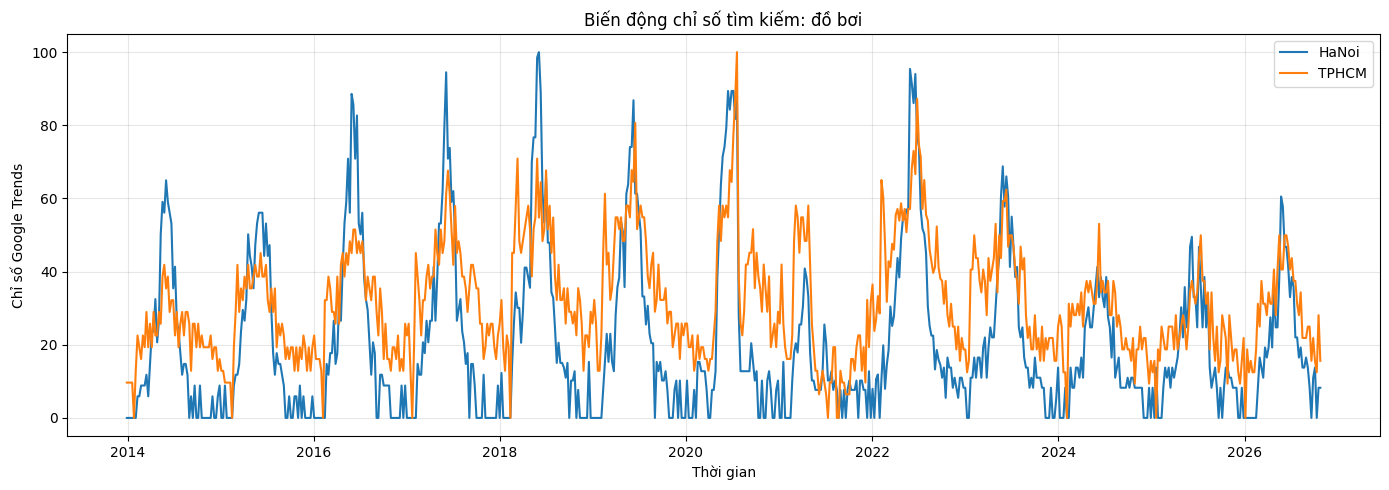

In [33]:
plt.figure(figsize=(14, 5))

for city in df_all["CityName"].unique():

    city_df = df_all[
        df_all["CityName"] == city
    ]

    plt.plot(
        city_df["date"],
        city_df[keyword],
        label=city
    )

plt.title(f"Biến động chỉ số tìm kiếm: {keyword}")
plt.xlabel("Thời gian")
plt.ylabel("Chỉ số Google Trends")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [34]:
# Nhận diện các tuần có chỉ số tìm kiếm tăng đột biến
keyword = "quần tây"

spike_results = []

for city in df_all["CityName"].unique():

    # Lọc dữ liệu theo từng thành phố
    city_df = df_all[
        df_all["CityName"] == city
    ].copy()

    # Tính trung bình và độ lệch chuẩn
    mean_value = city_df[keyword].mean()
    std_value = city_df[keyword].std()

    # Tính Z-score cho từng tuần
    if std_value == 0:
        continue

    city_df["Z_score"] = (
        city_df[keyword] - mean_value
    ) / std_value

    # Lọc những tuần có Z-score > 2
    spikes = city_df[
        city_df["Z_score"] > 2
    ][["date", keyword, "Z_score"]].copy()

    spikes["CityName"] = city

    spike_results.append(spikes)

# Tổng hợp kết quả
spike_df = pd.concat(
    spike_results,
    ignore_index=True
)

# Sắp xếp theo mức độ tăng đột biến
display(
    spike_df.sort_values(
        "Z_score",
        ascending=False
    )
)

,date,quần tây,Z_score,CityName
7,2022-03-13,100.00,9.544248,HaNoi
6,2022-03-06,71.24,6.089513,HaNoi
8,2022-03-20,57.52,4.441427,HaNoi
11,2022-05-01,53.10,3.910483,HaNoi
5,2022-02-27,51.31,3.695463,HaNoi
27,2022-01-09,100.00,3.376863,TPHCM
2,2021-12-26,46.90,3.165721,HaNoi
9,2022-04-17,46.90,3.165721,HaNoi
3,2022-01-02,45.59,3.008360,HaNoi
22,2021-01-03,92.89,2.929356,TPHCM


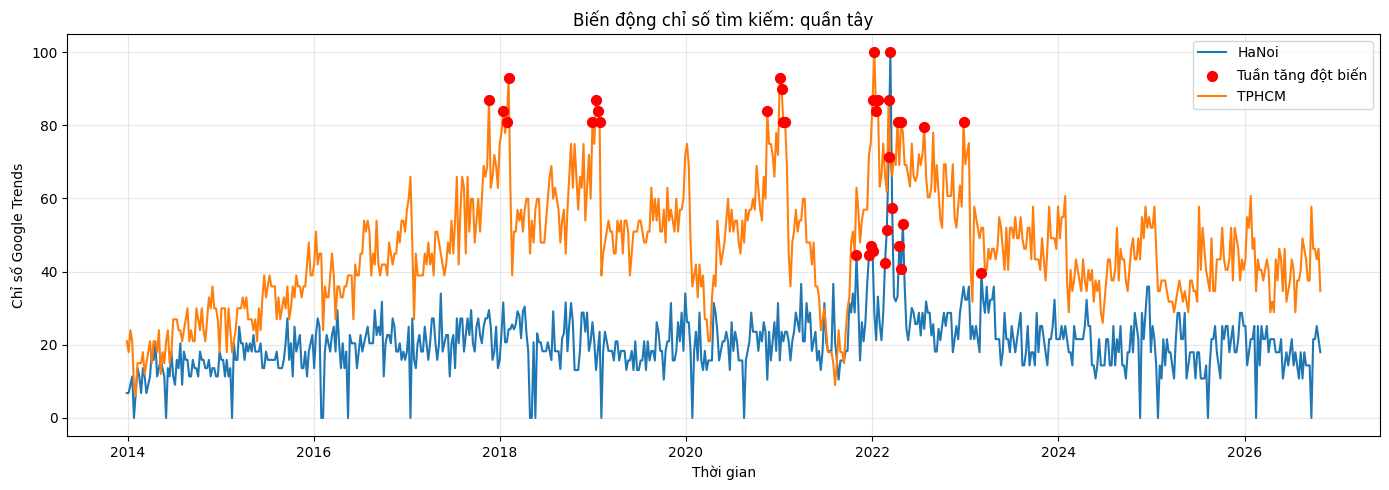

In [35]:
# Vẽ biểu đồ
plt.figure(figsize=(14, 5))

for i, city in enumerate(df_all["CityName"].unique()):

    city_df = df_all[
        df_all["CityName"] == city
    ].sort_values("date")

    # Vẽ đường chỉ số tìm kiếm
    plt.plot(
        city_df["date"],
        city_df[keyword],
        label=city
    )

    # Lấy các tuần tăng đột biến
    city_spikes = spike_df[
        spike_df["CityName"] == city
    ]

    # Đánh dấu các điểm tăng đột biến
    plt.scatter(
        city_spikes["date"],
        city_spikes[keyword],
        color="red",
        s=50,
        label="Tuần tăng đột biến" if i == 0 else None,
        zorder=3
    )

plt.title(f"Biến động chỉ số tìm kiếm: {keyword}")
plt.xlabel("Thời gian")
plt.ylabel("Chỉ số Google Trends")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [36]:
print(df_all.shape)
display(df_all.head())

(1340, 78)


,date,áo chống nắng,kính râm,áo thun,quần đùi,váy maxi,áo sơ mi,đồ bơi,dép sandal,áo mưa,...,weather_51,weather_53,weather_55,weather_61,weather_63,weather_65,CityName,Month,Season,YearMonth
0,2013-12-29,0.0,0.0,7.12,0.00,0.0,19.0,0.0,0.0,6.06,...,False,False,False,False,False,False,HaNoi,12,Mua lanh,2013-12
1,2014-01-05,0.0,0.0,6.56,0.00,0.0,28.0,0.0,0.0,5.39,...,True,False,False,False,False,False,HaNoi,1,Mua lanh,2014-01
2,2014-01-12,0.0,0.0,7.19,12.05,0.0,26.0,0.0,0.0,4.04,...,False,False,False,False,False,False,HaNoi,1,Mua lanh,2014-01
3,2014-01-19,0.0,0.0,7.31,0.00,0.0,31.0,0.0,0.0,5.39,...,False,False,False,False,False,False,HaNoi,1,Mua lanh,2014-01
4,2014-01-26,0.0,0.0,4.05,12.05,0.0,24.0,0.0,0.0,5.39,...,False,False,False,False,False,False,HaNoi,1,Mua lanh,2014-01


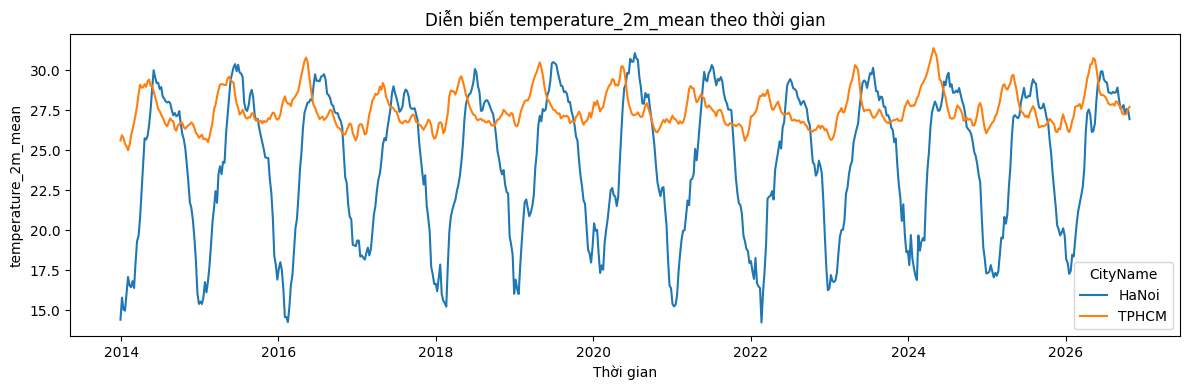

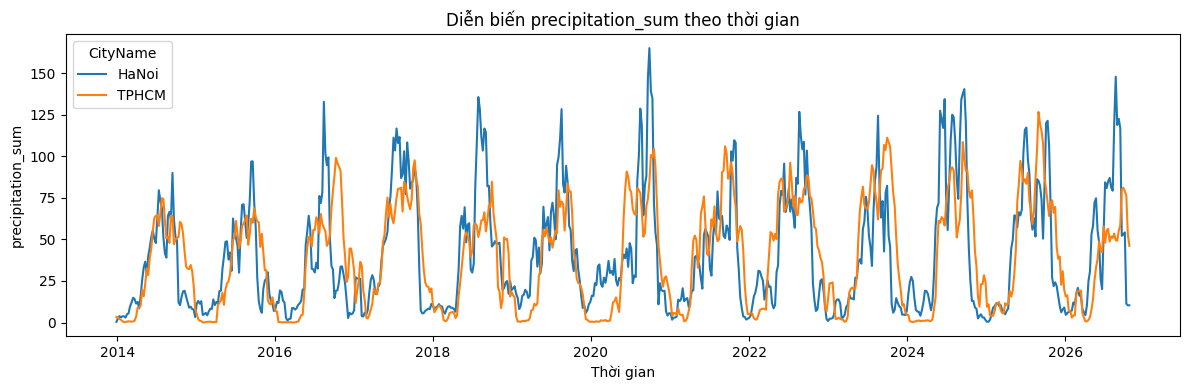

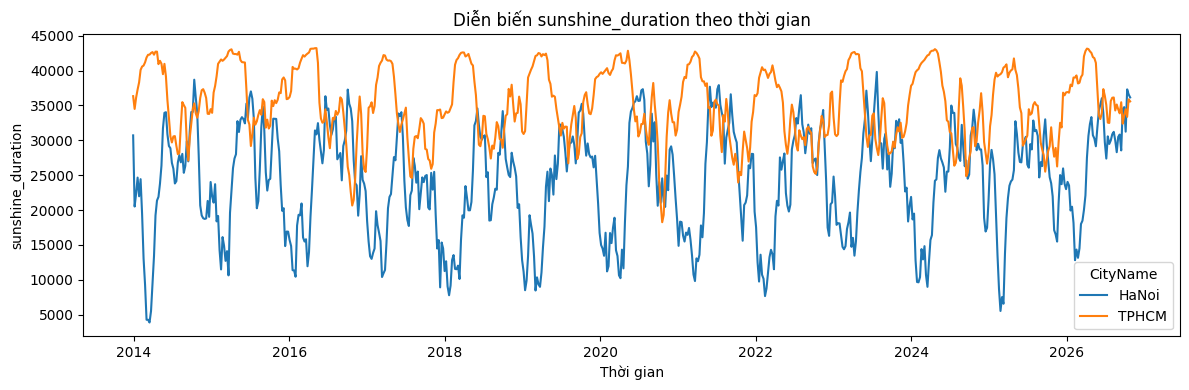

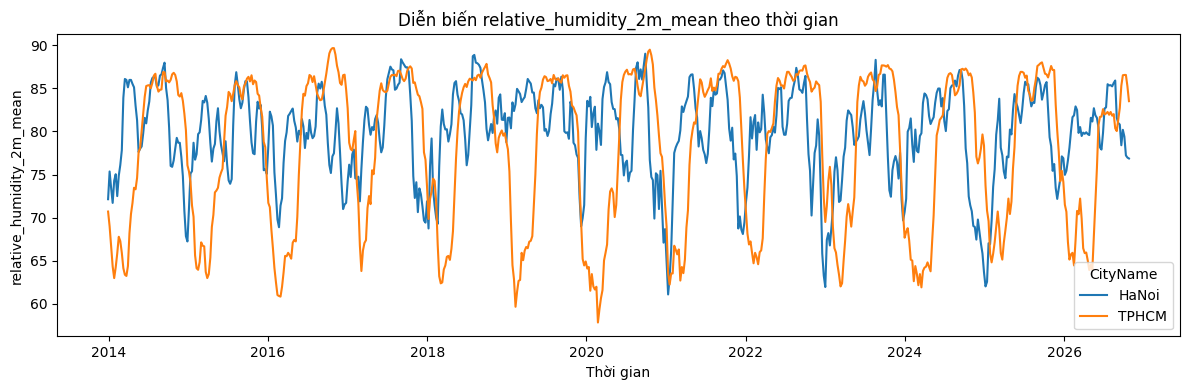

In [37]:
#3.4 Phân tích đặc điểm thời tiết tại ba thành phố:
#vẽ biểu đồ chuỗi thời tiết
import matplotlib.pyplot as plt
import seaborn as sns

# Sắp xếp dữ liệu theo thành phố và thời gian
df_weather = df_all.sort_values(  #sort_value: sắp xếp dữ liệu theo thành phố và ngày
    ["CityName", "date"]
).copy()

# Tính trung bình trượt 4 quan sát để làm mượt đường biểu diễn
for col in selected_weather:

    smooth_col = f"{col}_MA4"

    df_weather[smooth_col] = (
        df_weather.groupby("CityName")[col]  #groupby: xử lý dữ liệu riêng cho từng thành phố
        .transform(lambda x: x.rolling(4, min_periods=1).mean()) #rolling=4: Tính trung bình
        #trượt trên 4 quan sát liên tiếp để làm mượt các dao động ngắn hạn. Với dữ liệu tuần, 4 quan sát tương đương khoảng 4 tuần.
    )

    plt.figure(figsize=(12, 4))

    sns.lineplot(
        data=df_weather,
        x="date",
        y=smooth_col,
        hue="CityName"
    )

    plt.title(f"Diễn biến {col} theo thời gian")
    plt.xlabel("Thời gian")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

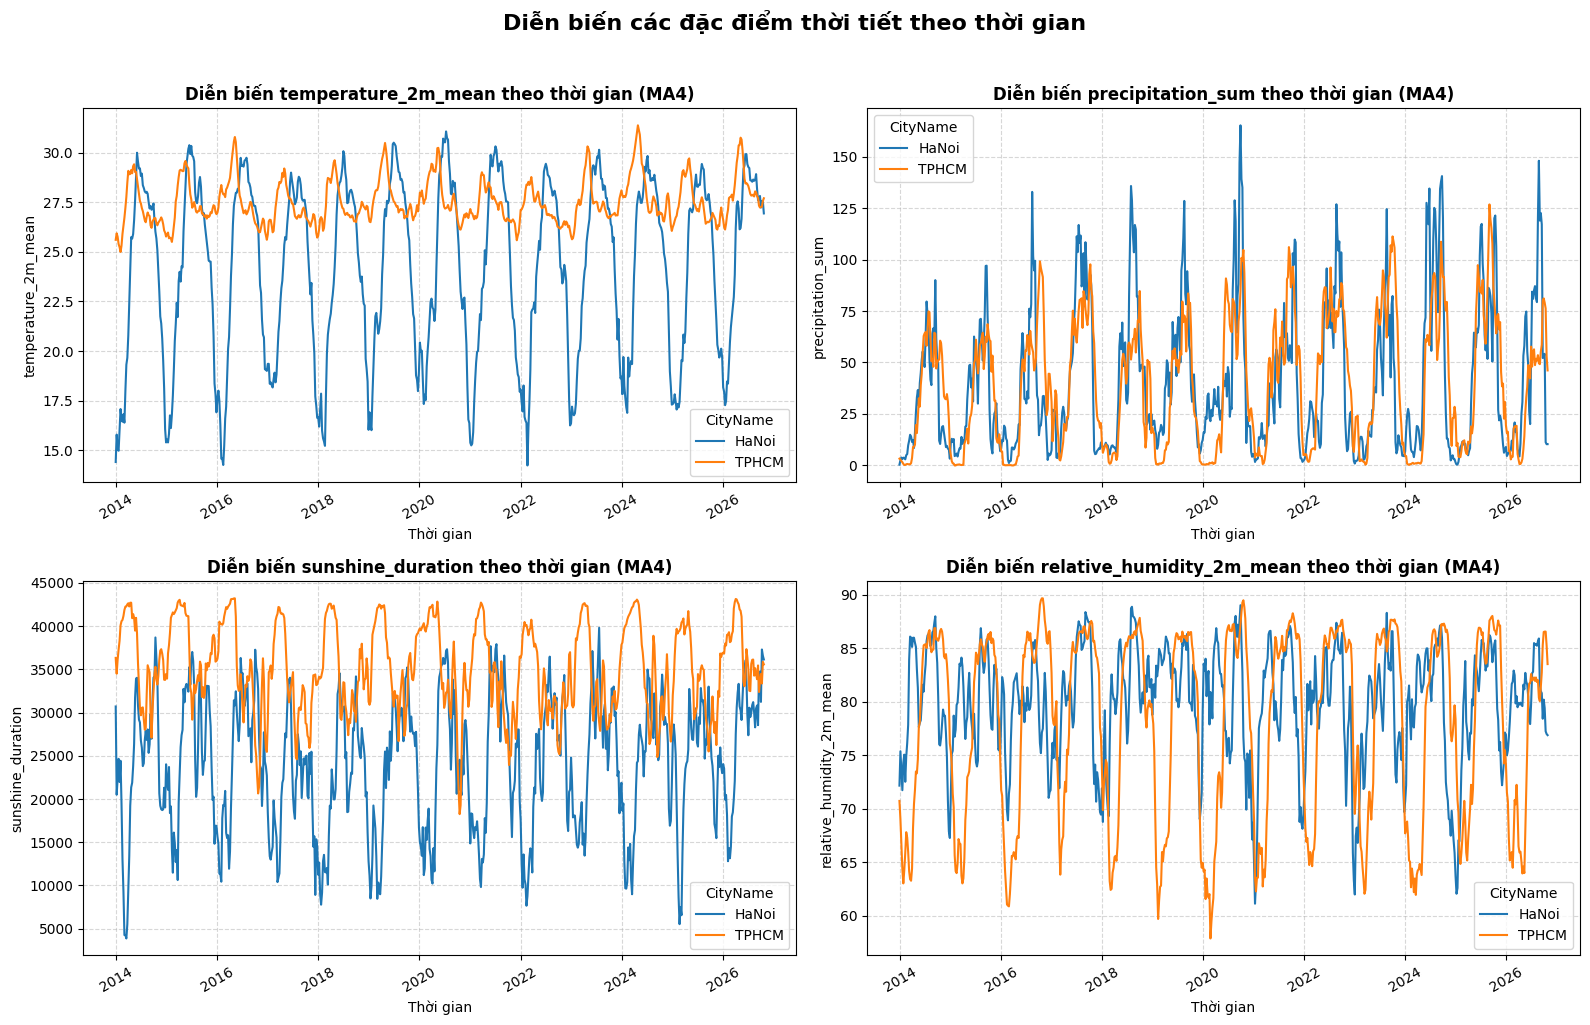

In [38]:
# Đoạn mã độc lập: Vẽ biểu đồ đặc điểm thời tiết gộp thành lưới 2x2
import matplotlib.pyplot as plt
import seaborn as sns

# Sắp xếp dữ liệu theo thành phố và thời gian
df_weather = df_all.sort_values(
    ["CityName", "date"]
).copy()

# Tính trung bình trượt 4 tuần (4 quan sát) để làm mượt đường biểu diễn
for col in selected_weather:
    smooth_col = f"{col}_MA4"
    df_weather[smooth_col] = (
        df_weather.groupby("CityName")[col]
        .transform(lambda x: x.rolling(4, min_periods=1).mean())
    )

# Khởi tạo lưới đồ họa 2x2
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

# Vẽ từng biến thời tiết lên lưới
for idx, col in enumerate(selected_weather):
    ax = axes[idx]
    smooth_col = f"{col}_MA4"

    sns.lineplot(
        data=df_weather,
        x="date",
        y=smooth_col,
        hue="CityName",
        ax=ax
    )

    ax.set_title(f"Diễn biến {col} theo thời gian (MA4)", fontsize=12, fontweight='bold')
    ax.set_xlabel("Thời gian")
    ax.set_ylabel(col)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.tick_params(axis='x', rotation=30)

plt.suptitle("Diễn biến các đặc điểm thời tiết theo thời gian", fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()

# Lưu ảnh chất lượng cao để chèn slide/báo cáo
plt.savefig("/content/weather_trends_grid.png", dpi=300, bbox_inches='tight')
plt.show()

In [39]:
weather_corr_cols = weather_cols.copy()

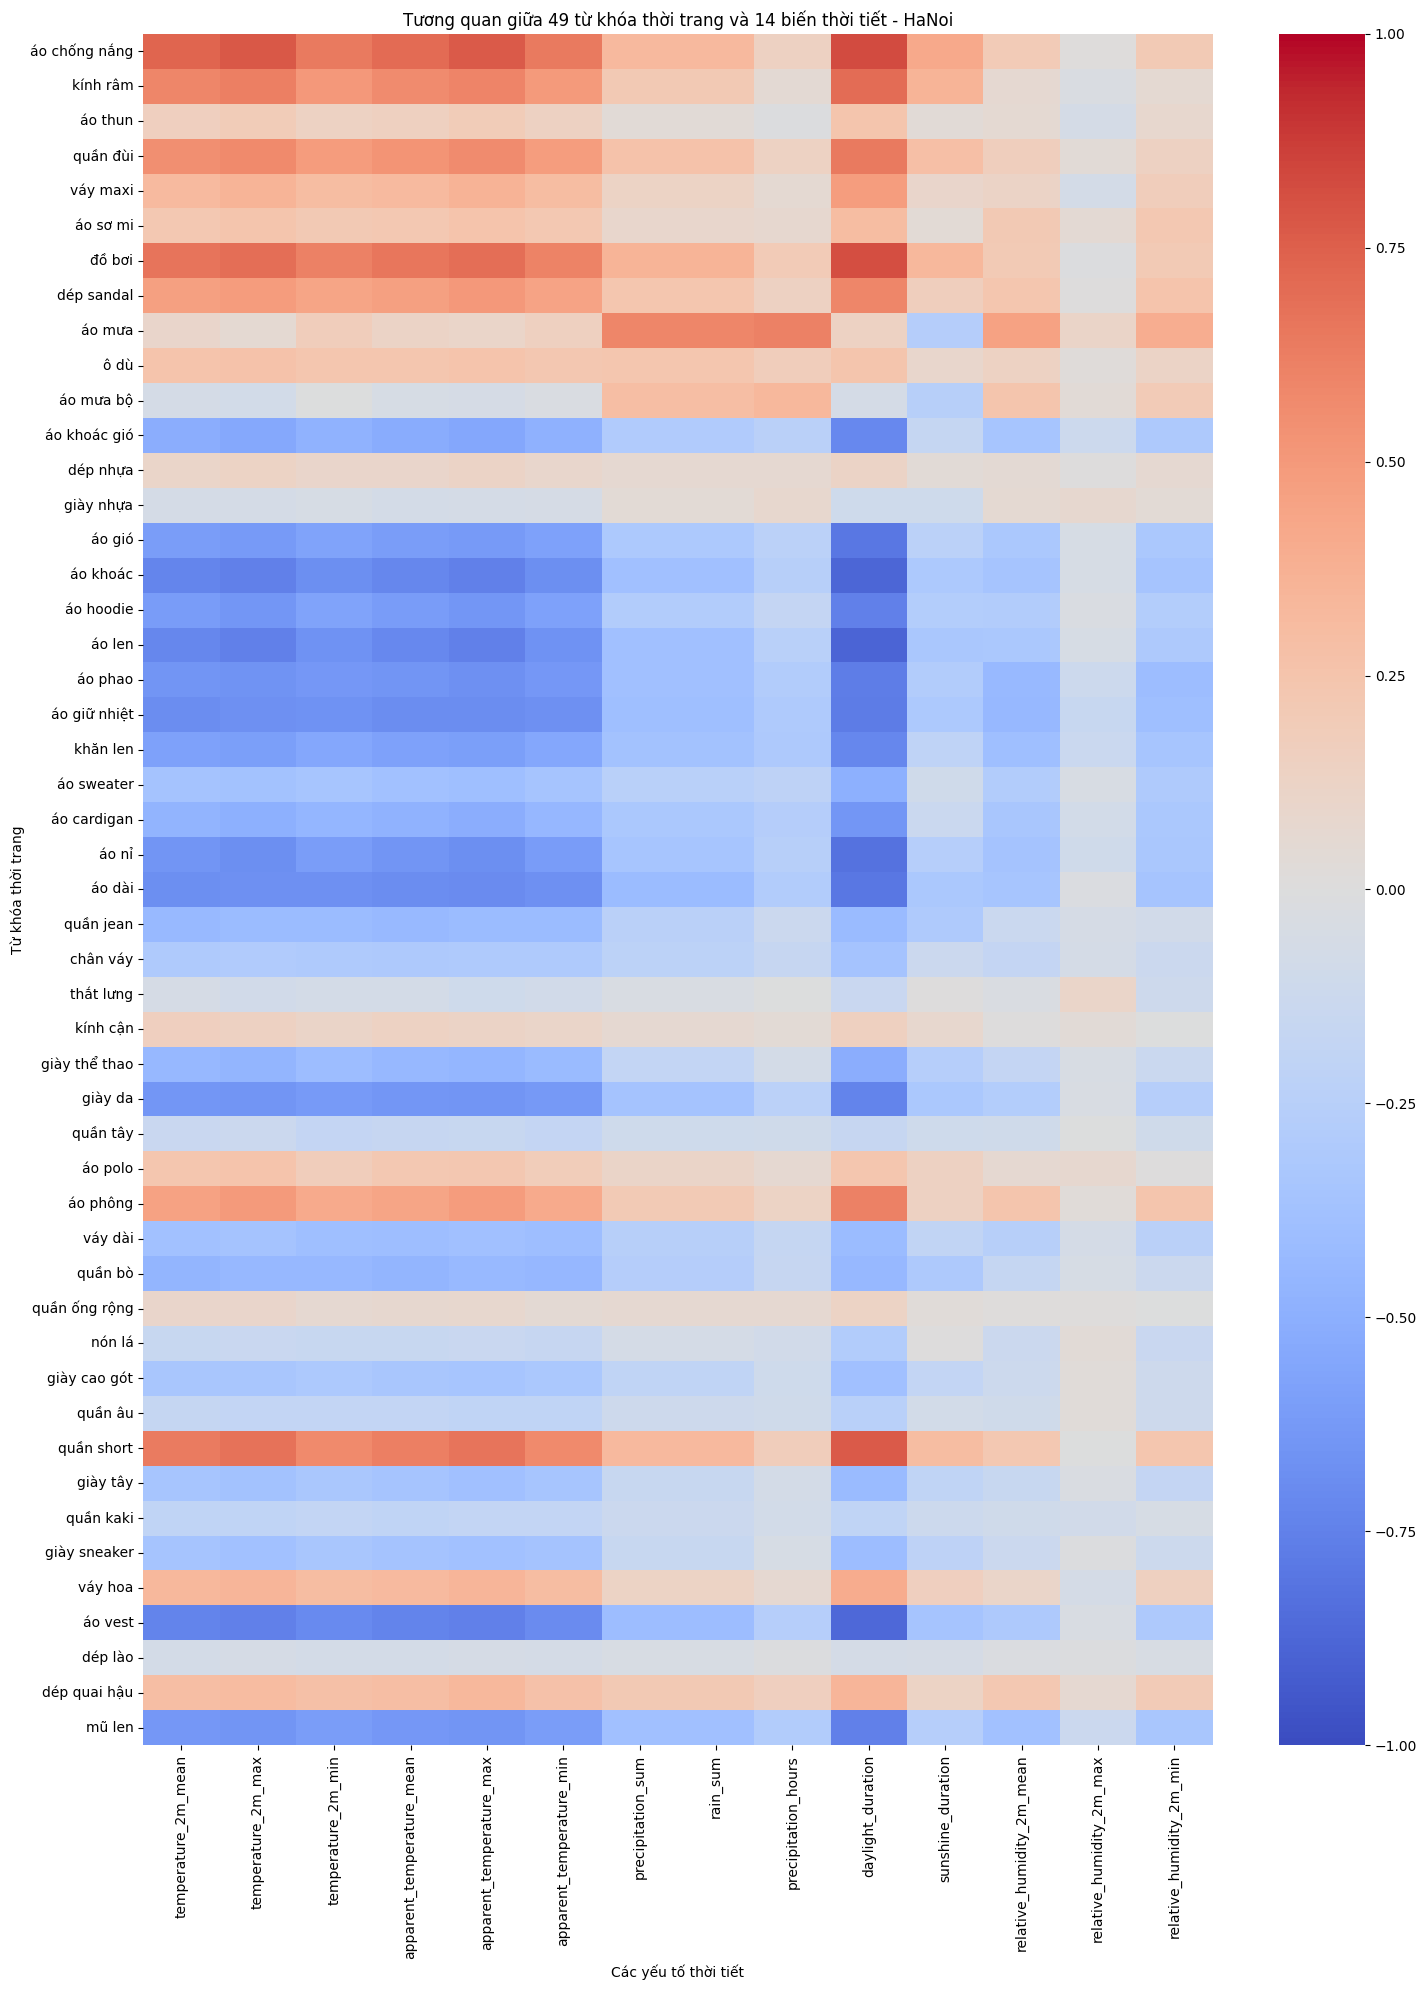

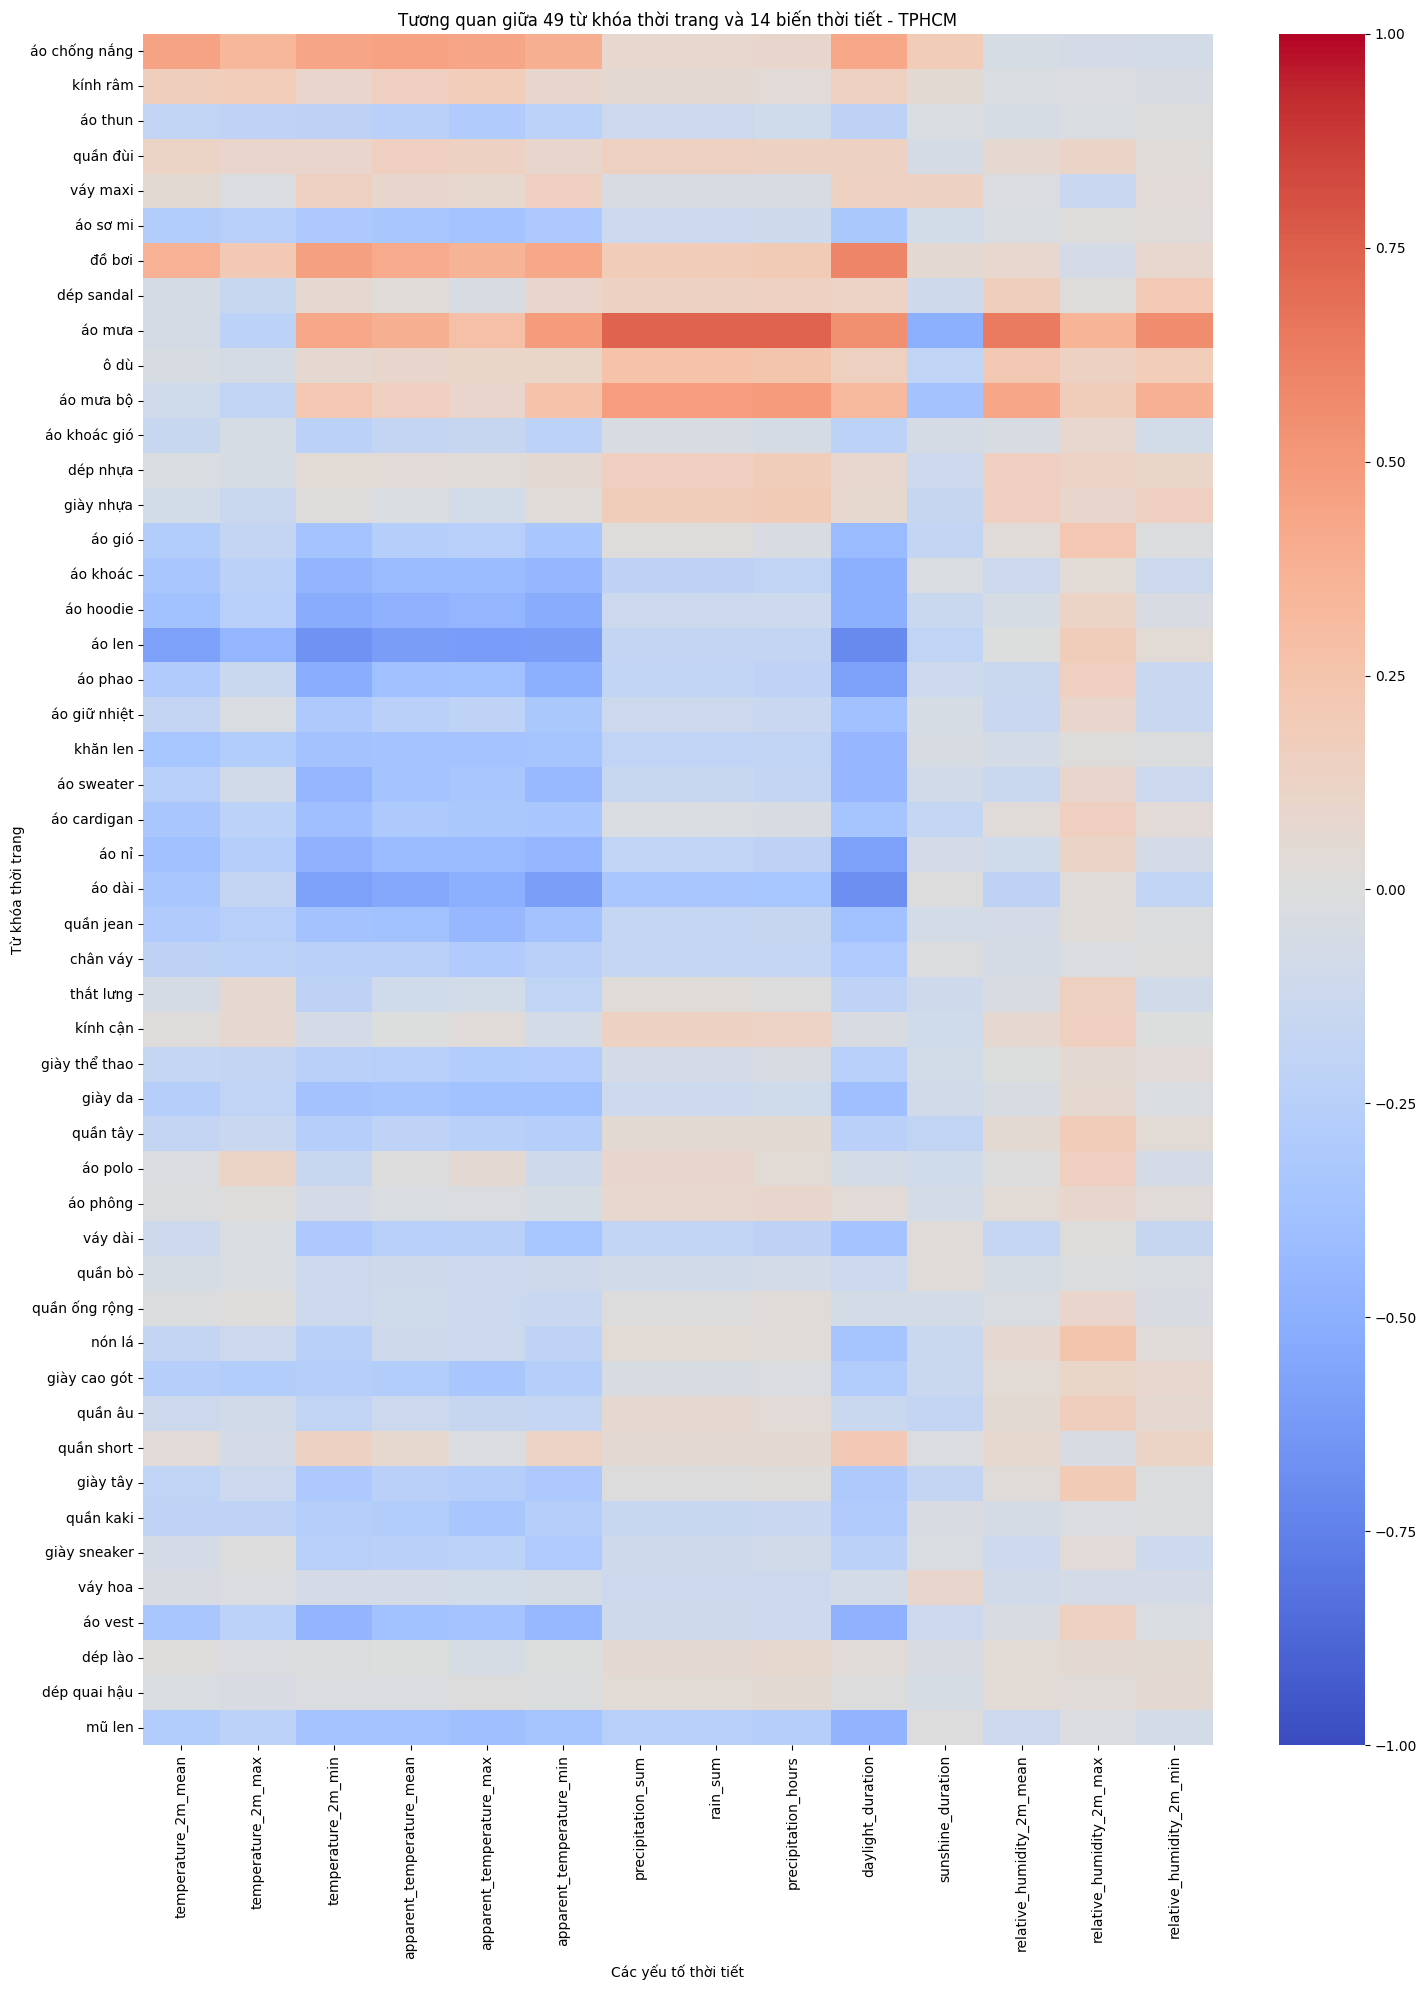

In [40]:
for city, data in df_all.groupby("CityName"):

    corr = data[
        trend_cols + weather_corr_cols
    ].corr(method="spearman")

    corr_matrix = corr.loc[
        trend_cols,
        weather_corr_cols
    ]

    plt.figure(figsize=(15, 20))

    sns.heatmap(
        corr_matrix,
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
        annot=False
    )

    plt.title(
        f"Tương quan giữa 49 từ khóa thời trang và 14 biến thời tiết - {city}"
    )
    plt.xlabel("Các yếu tố thời tiết")
    plt.ylabel("Từ khóa thời trang")
    plt.tight_layout()
    plt.show()

In [41]:
#Dùng một vài biến thời trang tiêu biểu để xét tương quan
selected_trends_corr = [
    "áo chống nắng",
    "kính râm",
    "áo thun",
    "đồ bơi",
    "dép sandal",
    "áo mưa",
    "ô dù",
    "áo len",
    "áo phao",
    "quần jean"
]


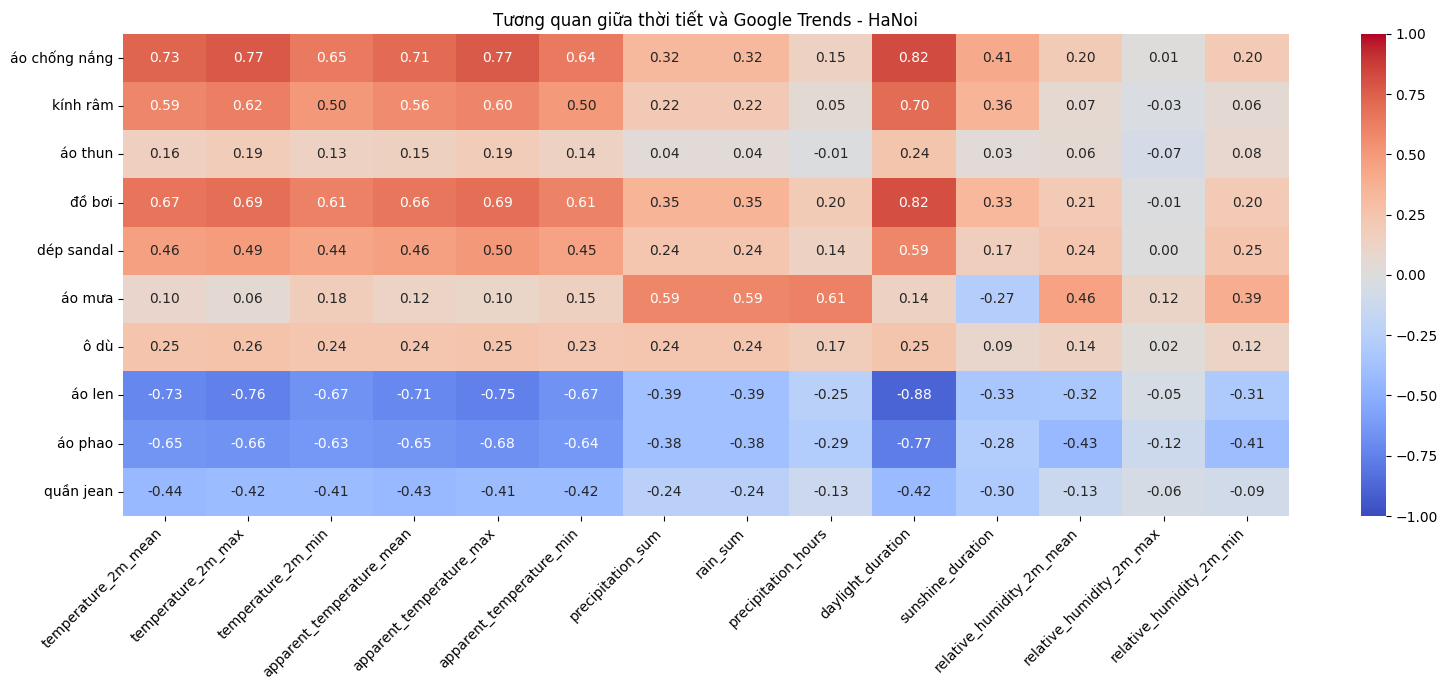

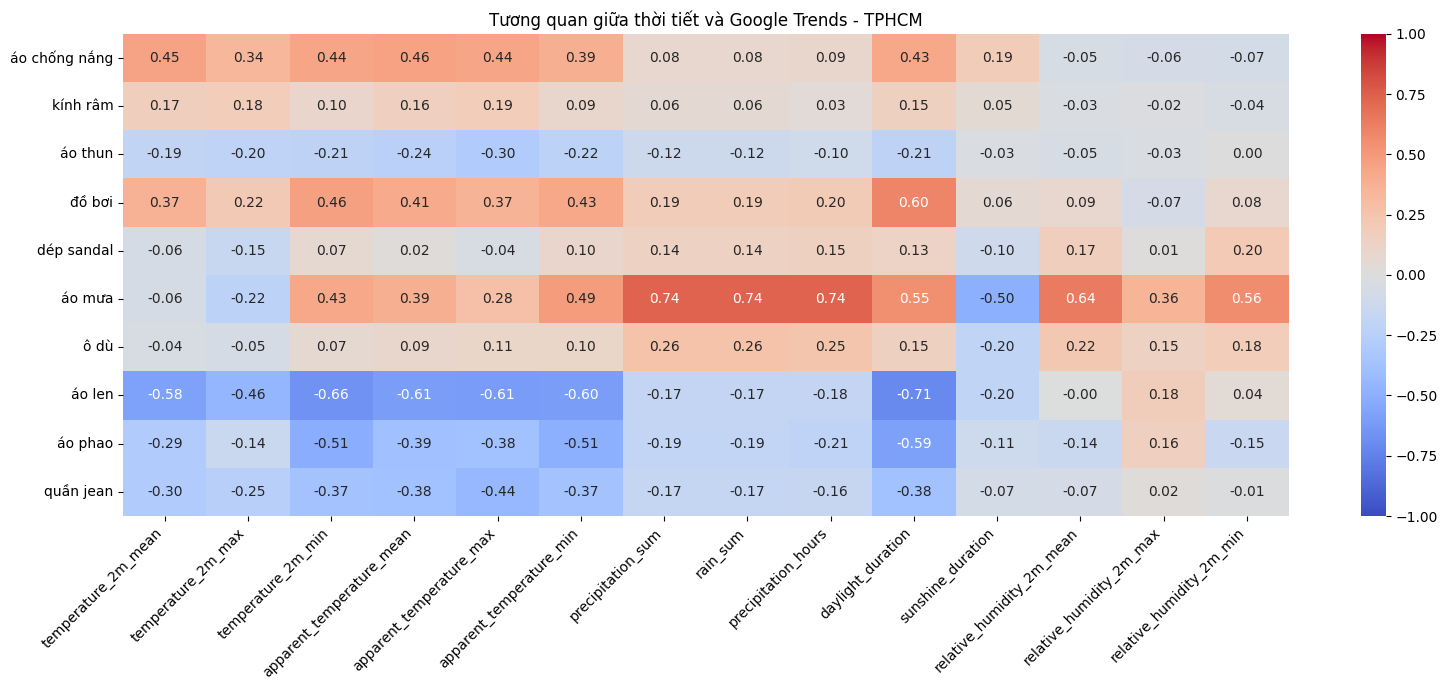

In [42]:
#3.5 Phân tích mối quan hệ giữa thời tiết và xu hướng tìm kiếm
#3.5.1 Phân tích tương quan giữa các biến
#Vẽ heatmap riêng cho từng thành phố
# Phân tích tương quan giữa Trends và Weather

selected_weather_corr = weather_cols.copy()

# Phân tích tương quan Spearman
for city, data in df_all.groupby("CityName"):

    corr = data[
        selected_trends_corr + selected_weather_corr
    ].corr(method="spearman")

    # Chỉ lấy tương quan giữa Trends và Weather
    corr_matrix = corr.loc[
        selected_trends_corr,
        selected_weather_corr
    ]

    plt.figure(figsize=(16, 7))

    sns.heatmap(
        corr_matrix,
        annot=True,
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
        fmt=".2f" #lấy 2 chữ số thập phân
    )

    plt.title(
        f"Tương quan giữa thời tiết và Google Trends - {city}"
    )
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

In [43]:
#3.5.2 So sánh xu hướng tìm kiếm theo điều kiện thời tiết
#Tạo nhóm nhiệt độ và lượng mưa
df_compare = df_all.copy()

# Chia nhiệt độ thành 3 nhóm theo từng thành phố
def classify_temperature(s):
    return pd.qcut(
        s.rank(method="first"),
        q=3,
        labels=["Thấp", "Trung bình", "Cao"]
    )

df_compare["Temperature_Group"] = (
    df_compare.groupby("CityName")["temperature_2m_mean"]
    .transform(classify_temperature)
)

# Chia lượng mưa thành 3 nhóm:
# Không mưa, mưa thấp và mưa cao
def classify_rain(s):

    result = pd.Series(index=s.index, dtype="object")

    result.loc[s == 0] = "Không mưa"

    rainy = s[s > 0]

    if len(rainy) > 0:
        median_rain = rainy.median()

        result.loc[rainy.index[rainy <= median_rain]] = "Mưa thấp"
        result.loc[rainy.index[rainy > median_rain]] = "Mưa cao"

    return result

df_compare["Rain_Group"] = (
    df_compare.groupby("CityName")["precipitation_sum"]
    .transform(classify_rain)
)

display(
    df_compare[
        ["CityName", "date", "temperature_2m_mean",
         "Temperature_Group", "precipitation_sum", "Rain_Group"]
    ].head(10)
)

,CityName,date,temperature_2m_mean,Temperature_Group,precipitation_sum,Rain_Group
0,HaNoi,2013-12-29,14.40,Thấp,0.4,Mưa thấp
1,HaNoi,2014-01-05,17.16,Thấp,4.6,Mưa thấp
2,HaNoi,2014-01-12,13.54,Thấp,6.5,Mưa thấp
3,HaNoi,2014-01-19,14.77,Thấp,0.8,Mưa thấp
4,HaNoi,2014-01-26,18.71,Thấp,3.2,Mưa thấp
5,HaNoi,2014-02-02,21.27,Thấp,4.3,Mưa thấp
6,HaNoi,2014-02-09,11.44,Thấp,3.6,Mưa thấp
7,HaNoi,2014-02-16,14.31,Thấp,8.9,Mưa thấp
8,HaNoi,2014-02-23,20.23,Thấp,5.3,Mưa thấp
9,HaNoi,2014-03-02,19.56,Thấp,21.3,Mưa thấp


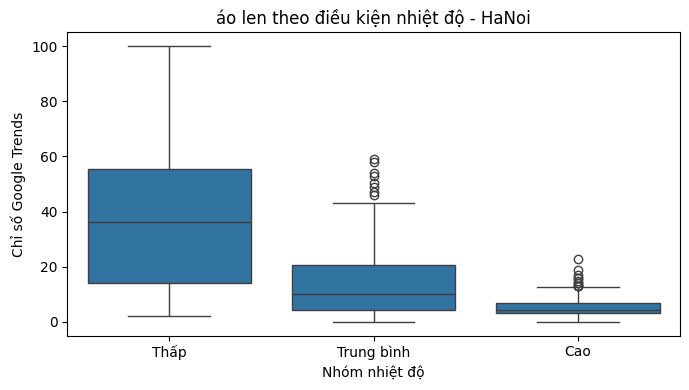

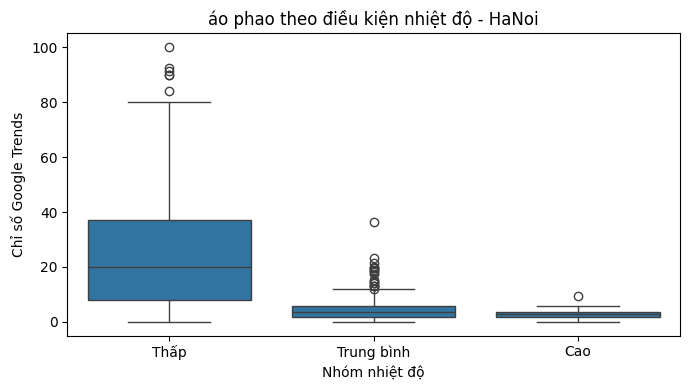

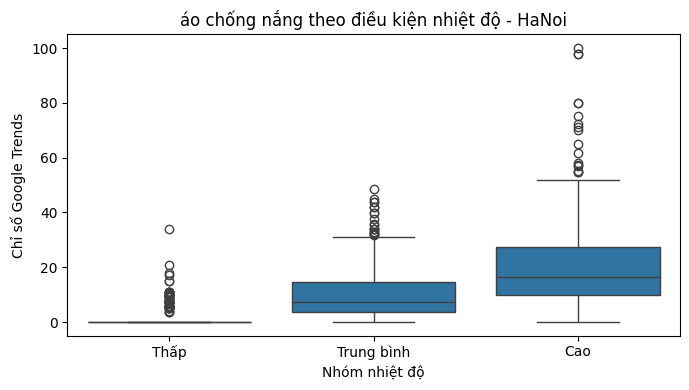

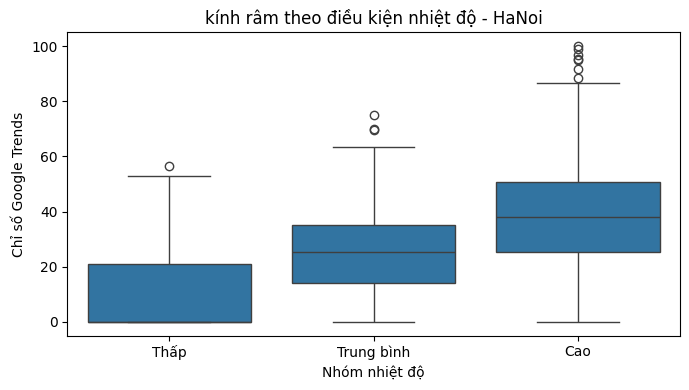

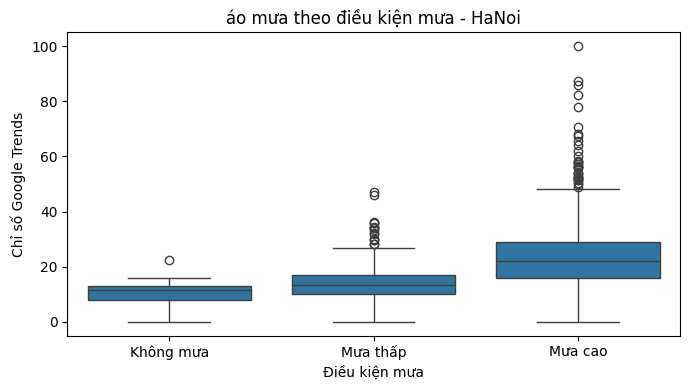

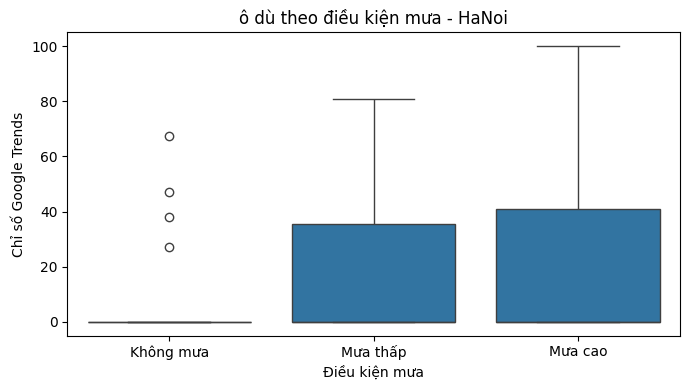

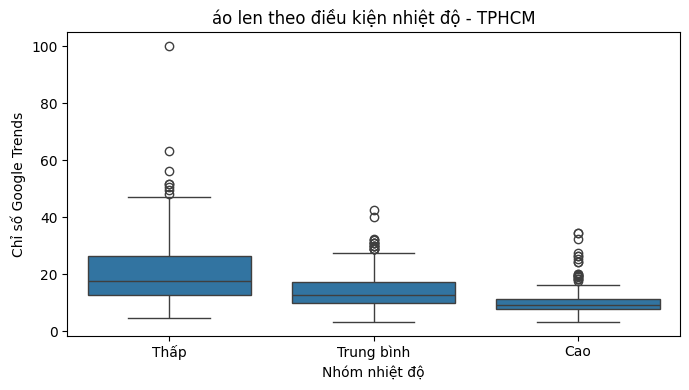

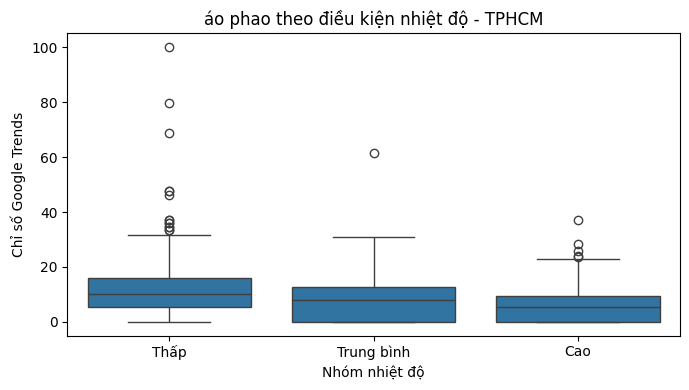

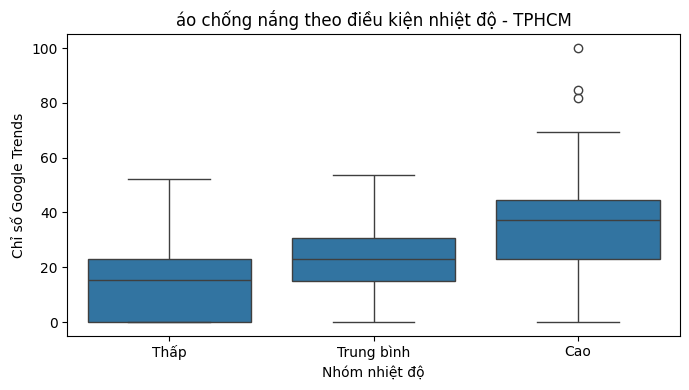

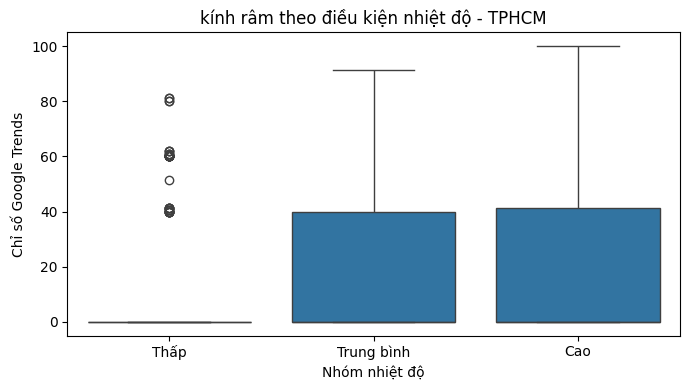

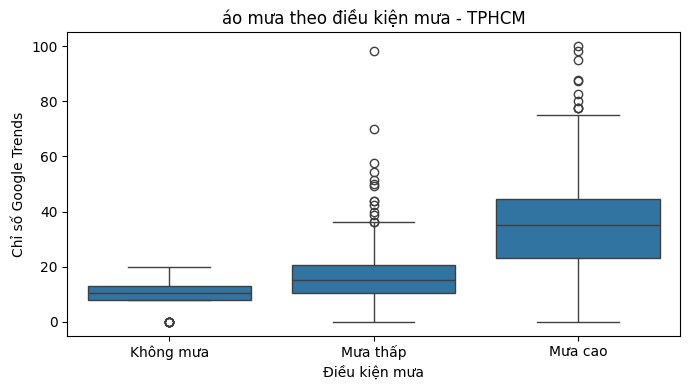

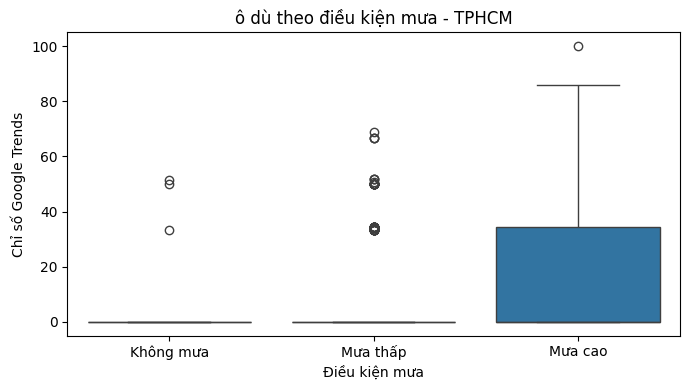

In [44]:
# Các từ khóa có liên quan đến nhiệt độ
temperature_keywords = [
    "áo len", "áo phao", "áo chống nắng", "kính râm"
]

# Các từ khóa có liên quan đến mưa
rain_keywords = [
    "áo mưa", "ô dù"
]

# Vẽ theo từng thành phố
for city, data in df_compare.groupby("CityName"):

    # So sánh theo nhóm nhiệt độ
    for col in temperature_keywords:

        plt.figure(figsize=(7, 4))

        sns.boxplot(
            data=data,
            x="Temperature_Group",
            y=col,
            order=["Thấp", "Trung bình", "Cao"]
        )

        plt.title(f"{col} theo điều kiện nhiệt độ - {city}")
        plt.xlabel("Nhóm nhiệt độ")
        plt.ylabel("Chỉ số Google Trends")
        plt.tight_layout()
        plt.show()

    # So sánh theo nhóm lượng mưa
    for col in rain_keywords:

        plt.figure(figsize=(7, 4))

        sns.boxplot(
            data=data,
            x="Rain_Group",
            y=col,
            order=["Không mưa", "Mưa thấp", "Mưa cao"]
        )

        plt.title(f"{col} theo điều kiện mưa - {city}")
        plt.xlabel("Điều kiện mưa")
        plt.ylabel("Chỉ số Google Trends")
        plt.tight_layout()
        plt.show()

Nhận xét:

- Đối với nhóm thời trang mùa lạnh (áo len, áo phao) tại Hà Nội: Chỉ số tìm kiếm tập trung cực kỳ cao ở nhóm nhiệt độ Thấp (trung vị đạt từ 30–40 điểm, có thời điểm chạm trần 100), sau đó giảm tiệm cận về 0 khi nhiệt độ chuyển sang mức Trung bình và Cao. Trong khi đó, tại TP.HCM, các mặt hàng này duy trì mức tìm kiếm thấp và ít biến động do không có mùa lạnh.

- Đối với nhóm thời trang chống nắng / mùa hè (áo chống nắng, kính râm): Xuất hiện chiều ngược lại hoàn toàn. Chỉ số tìm kiếm tăng mạnh và đạt giá trị phân phối cao nhất ở nhóm nhiệt độ Cao (đặc biệt rõ nét ở Hà Nội vào mùa nắng nóng).

- Đối với nhóm phụ kiện thời tiết (áo mưa, ô dù): Phản ánh rất đồng điệu với lượng mưa. Cả hai thành phố đều ghi nhận mức tìm kiếm tăng vọt tịnh tiến từ trạng thái Không mưa sang Mưa cao. Đặc biệt ở trạng thái Mưa cao, trung vị và biên độ phân tán của từ khóa áo mưa mở rộng rõ rệt, chứng minh phản ứng mua sắm trực tiếp của người dân khi điều kiện thời tiết chuyển xấu.

In [45]:
#3.5.3 So sánh sự khác biệt giữa các thành phố
#Sở dụng boxplot thời tiết ở 3.4
# Lập bảng so sánh tương quan giữa các thành phố -> nhóm có thể
#so sánh chiều hướng và mức độ tương quan giữa hai nơi.

comparison_rows = []

for city, data in df_all.groupby("CityName"):

    corr = data[selected_trends + selected_weather].corr(
        method="spearman"
    )

    corr_matrix = corr.loc[selected_trends, selected_weather]

    for trend in selected_trends:
        for weather in selected_weather:

            comparison_rows.append({
                "CityName": city,
                "Tu_khoa": trend,
                "Yeu_to_thoi_tiet": weather,
                "Spearman": corr_matrix.loc[trend, weather]
            })

comparison_table = pd.DataFrame(comparison_rows)

# Chuyển kết quả thành bảng so sánh giữa hai thành phố
comparison_pivot = comparison_table.pivot(
    index=["Tu_khoa", "Yeu_to_thoi_tiet"],
    columns="CityName",
    values="Spearman"
).reset_index()

comparison_pivot.columns.name = None

comparison_pivot = comparison_pivot.rename(columns={
    "Tu_khoa": "Từ khóa",
    "Yeu_to_thoi_tiet": "Yếu tố thời tiết",
    "HaNoi": "Hà Nội",
    "TPHCM": "TP.HCM"
})

display(comparison_pivot.round(3))

,Từ khóa,Yếu tố thời tiết,Hà Nội,TP.HCM
0,dép sandal,precipitation_sum,0.236,0.135
1,dép sandal,relative_humidity_2m_mean,0.237,0.168
2,dép sandal,sunshine_duration,0.168,-0.105
3,dép sandal,temperature_2m_mean,0.463,-0.062
4,quần jean,precipitation_sum,-0.241,-0.171
5,quần jean,relative_humidity_2m_mean,-0.134,-0.070
6,quần jean,sunshine_duration,-0.298,-0.075
7,quần jean,temperature_2m_mean,-0.435,-0.296
8,áo mưa,precipitation_sum,0.588,0.742
9,áo mưa,relative_humidity_2m_mean,0.456,0.640


In [46]:
# Kiểm tra thời gian và số quan sát của từng thành phố
display(
    df_all.groupby("CityName")["date"].agg(
        ["min", "max", "count"]
    )
)

# Kiểm tra bản ghi trùng thành phố và ngày
print(
    "Số bản ghi trùng:",
    df_all.duplicated(["CityName", "date"]).sum()
)

# Kiểm tra dữ liệu thiếu ở các biến được phân tích
display(
    df_all[
        selected_trends + selected_weather
    ].isnull().sum()
)

,min,max,count
CityName,,,
HaNoi,2013-12-29,2026-10-25,670
TPHCM,2013-12-29,2026-10-25,670


Số bản ghi trùng: 0


,0
đồ bơi,0
áo mưa,0
dép sandal,0
quần jean,0
temperature_2m_mean,0
precipitation_sum,0
sunshine_duration,0
relative_humidity_2m_mean,0


In [49]:
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42

## Phân cụm bằng K-Means

In [58]:
# Gán df bằng dữ liệu gộp df_all để phân cụm chạy trên cả hai thành phố
df = df_all.copy()
if 'CityName' in df.columns:
    df['City_name'] = df['CityName']
print("Dữ liệu gộp sẵn sàng cho phân cụm:", df.shape)

Dữ liệu gộp sẵn sàng cho phân cụm: (1340, 79)


In [59]:
GROUPS = {
    "hot":  ["áo chống nắng", "kính râm", "áo thun", "quần đùi", "váy maxi", "áo sơ mi", "đồ bơi", "dép sandal"],
    "rain": ["áo mưa", "ô dù", "áo mưa bộ", "áo khoác gió", "dép nhựa", "giày nhựa", "áo gió"],
    "cold": ["áo khoác", "áo hoodie", "áo len", "áo phao", "áo giữ nhiệt", "khăn len", "áo sweater", "áo cardigan", "áo nỉ", "mũ len"],
}
all_kw = list(df.columns[1:50])
used = GROUPS["hot"] + GROUPS["rain"] + GROUPS["cold"]
GROUPS["base"] = [c for c in all_kw if c not in used]

GROUP_LABEL = {"hot": "Mùa nóng", "rain": "Mùa mưa", "cold": "Mùa lạnh", "base": "Nền quanh năm"}
for g, cols in GROUPS.items():
    df[f"idx_{g}"] = df[cols].mean(axis=1)

FASHION_FEATS = [f"idx_{g}" for g in GROUPS]
df

,date,áo chống nắng,kính râm,áo thun,quần đùi,váy maxi,áo sơ mi,đồ bơi,dép sandal,áo mưa,...,weather_65,CityName,Month,Season,YearMonth,City_name,idx_hot,idx_rain,idx_cold,idx_base
0,2013-12-29,0.00,0.0,7.12,0.00,0.0,19.00,0.00,0.00,6.06,...,False,HaNoi,12,Mua lanh,2013-12,HaNoi,3.26500,5.561429,39.274,17.374583
1,2014-01-05,0.00,0.0,6.56,0.00,0.0,28.00,0.00,0.00,5.39,...,False,HaNoi,1,Mua lanh,2014-01,HaNoi,4.32000,20.147143,30.171,19.712500
2,2014-01-12,0.00,0.0,7.19,12.05,0.0,26.00,0.00,0.00,4.04,...,False,HaNoi,1,Mua lanh,2014-01,HaNoi,5.65500,4.347143,29.765,19.198333
3,2014-01-19,0.00,0.0,7.31,0.00,0.0,31.00,0.00,0.00,5.39,...,False,HaNoi,1,Mua lanh,2014-01,HaNoi,4.78875,3.944286,24.489,17.205000
4,2014-01-26,0.00,0.0,4.05,12.05,0.0,24.00,0.00,0.00,5.39,...,False,HaNoi,1,Mua lanh,2014-01,HaNoi,5.01250,1.828571,8.967,10.174583
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1335,2026-09-27,29.77,60.0,43.14,46.87,0.0,30.33,21.85,0.00,82.50,...,False,TPHCM,9,Mua mua,2026-09,TPHCM,28.99500,37.797143,10.958,30.334167
1336,2026-10-04,29.77,0.0,39.87,46.87,0.0,35.22,15.61,0.00,77.50,...,False,TPHCM,10,Mua mua,2026-10,TPHCM,20.91750,35.012857,13.024,27.366250
1337,2026-10-11,29.77,0.0,43.73,46.87,0.0,36.20,12.48,0.00,42.50,...,False,TPHCM,10,Mua mua,2026-10,TPHCM,21.13125,21.481429,10.657,28.745000
1338,2026-10-18,14.89,60.0,41.44,46.87,0.0,30.33,28.09,0.00,27.50,...,False,TPHCM,10,Mua mua,2026-10,TPHCM,27.70250,6.814286,12.633,24.734167


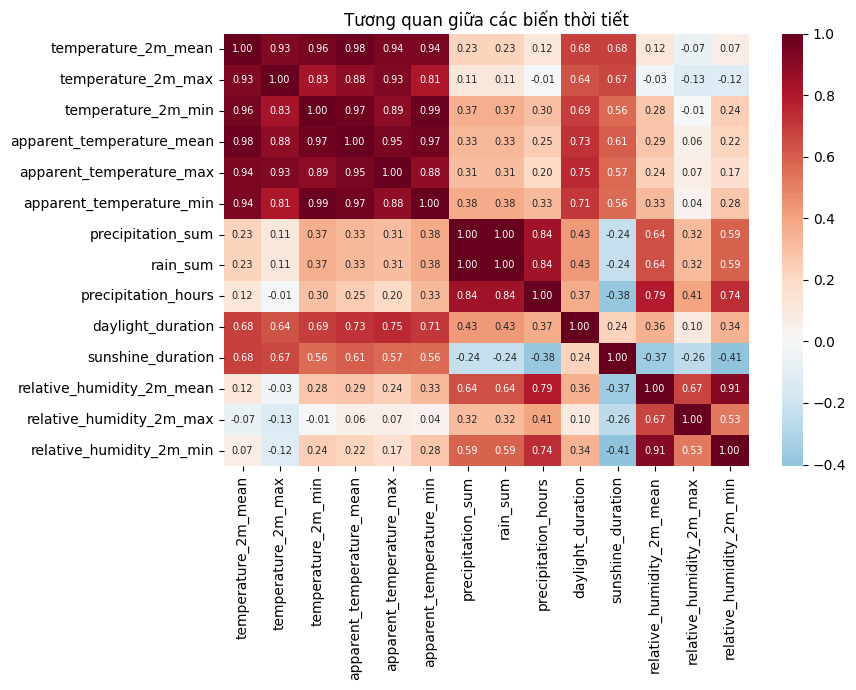

In [60]:
weather_all = ["temperature_2m_mean", "temperature_2m_max", "temperature_2m_min",
               "apparent_temperature_mean", "apparent_temperature_max", "apparent_temperature_min",
               "precipitation_sum", "rain_sum", "precipitation_hours",
               "daylight_duration", "sunshine_duration",
               "relative_humidity_2m_mean", "relative_humidity_2m_max", "relative_humidity_2m_min"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[weather_all].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, annot_kws={"size": 7})
plt.title("Tương quan giữa các biến thời tiết"); plt.tight_layout(); plt.show()

In [61]:
WEATHER_FEATS = ["temperature_2m_mean",        # đại diện nhóm nhiệt độ
                 "precipitation_sum",          # lượng mưa
                 "precipitation_hours",        # số giờ mưa
                 "sunshine_duration",          # thời gian nắng
                 "daylight_duration",          # độ dài ban ngày
                 "relative_humidity_2m_mean"]  # độ ẩm

FEATURES = WEATHER_FEATS + FASHION_FEATS
X_raw = df[FEATURES]
X = StandardScaler().fit_transform(X_raw)
print("Ma trận phân cụm:", X.shape)

Ma trận phân cụm: (1340, 10)


,Inertia (WCSS),Silhouette,Giảm inertia so với K-1 (%)
K,,,
2,9972.520,0.241,NaN
3,7939.062,0.241,20.4
4,7004.679,0.205,11.8
5,6398.884,0.204,8.6
6,5883.548,0.201,8.1
7,5409.871,0.202,8.1
8,5094.864,0.194,5.8
9,4823.559,0.192,5.3
10,4620.622,0.190,4.2


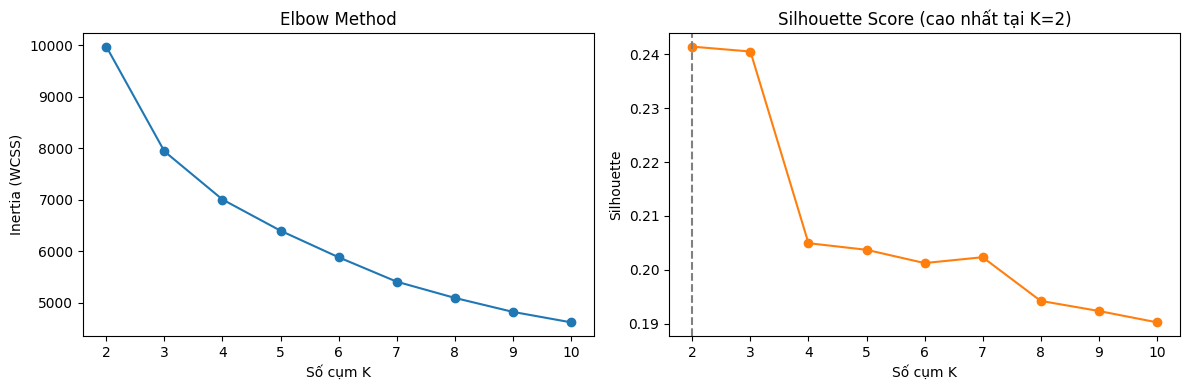

In [62]:
# xác định số cụm tối ưu
K_RANGE = range(2, 11)
rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X)
    rows.append({"K": k, "Inertia (WCSS)": km.inertia_, "Silhouette": silhouette_score(X, km.labels_)})
k_eval = pd.DataFrame(rows).set_index("K")
k_eval["Giảm inertia so với K-1 (%)"] = (-k_eval["Inertia (WCSS)"].pct_change() * 100).round(1)
display(k_eval.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(k_eval.index, k_eval["Inertia (WCSS)"], "o-")
ax[0].set(title="Elbow Method", xlabel="Số cụm K", ylabel="Inertia (WCSS)")
ax[1].plot(k_eval.index, k_eval["Silhouette"], "o-", color="tab:orange")
best_k = int(k_eval["Silhouette"].idxmax())
ax[1].axvline(best_k, ls="--", color="gray"); ax[1].set(title=f"Silhouette Score (cao nhất tại K={best_k})", xlabel="Số cụm K", ylabel="Silhouette")
plt.tight_layout(); plt.show()

In [63]:
# K=2 và K=3 có Silhouette bằng nhau (0.241)
K = 3
print(f"K tối ưu theo Silhouette = {best_k} | K được chọn = {K}")

km = KMeans(n_clusters=K, n_init=50, random_state=RANDOM_STATE).fit(X)

K tối ưu theo Silhouette = 2 | K được chọn = 3


In [64]:
# phân cụm K-means
df["cluster"] = km.labels_
# Sắp xếp lại nhãn theo nhiệt độ trung bình tăng dần (cụm 0 = lạnh nhất)
order = df.groupby("cluster")["temperature_2m_mean"].mean().sort_values().index
remap = {old: new for new, old in enumerate(order)}
df["cluster"] = df["cluster"].map(remap)

df["date"] = pd.to_datetime(df["date"])
df["month"] = df["date"].dt.month

counts = df["cluster"].value_counts().sort_index()
print(pd.DataFrame({"n_weeks": counts, "ratio": (counts / len(df)).round(3)}))
df[["date", "City_name", "cluster"]].head()

         n_weeks  ratio
cluster                
0            281  0.210
1            556  0.415
2            503  0.375


,date,City_name,cluster
0,2013-12-29,HaNoi,0
1,2014-01-05,HaNoi,0
2,2014-01-12,HaNoi,0
3,2014-01-19,HaNoi,0
4,2014-01-26,HaNoi,0


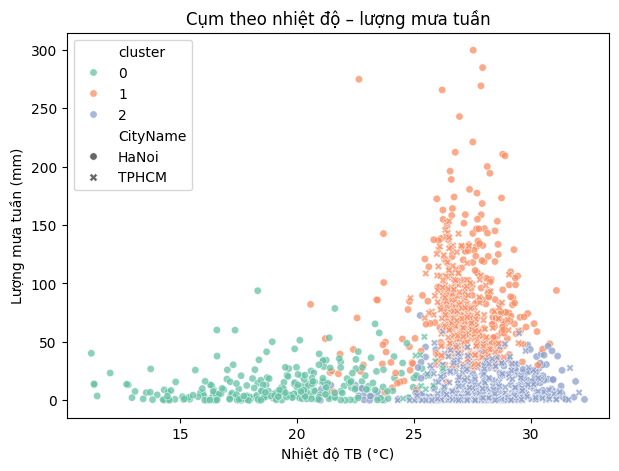

In [65]:
pal = sns.color_palette("Set2", K)

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="temperature_2m_mean", y="precipitation_sum", hue="cluster", palette=pal, style="CityName", s=28, alpha=.75)
plt.title("Cụm theo nhiệt độ – lượng mưa tuần")
plt.xlabel("Nhiệt độ TB (°C)"); plt.ylabel("Lượng mưa tuần (mm)")
plt.show()

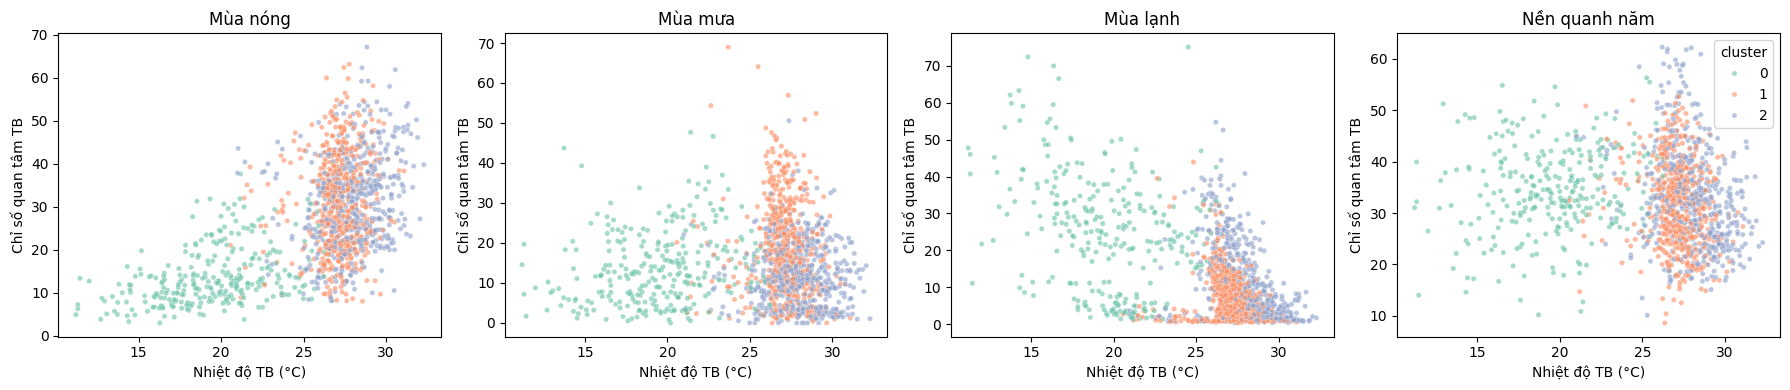

In [66]:
# nhiệt độ vs chỉ số quan tâm từng nhóm thời tiết và nhu cầu thời trang
fig, ax = plt.subplots(1, 4, figsize=(18, 4), sharex=True)
for a, g in zip(ax, GROUPS):
    sns.scatterplot(data=df, x="temperature_2m_mean", y=f"idx_{g}", hue="cluster", palette=pal, s=14, alpha=.6, ax=a, legend=(g == "base"))
    a.set(title=GROUP_LABEL[g], xlabel="Nhiệt độ TB (°C)", ylabel="Chỉ số quan tâm TB")
plt.tight_layout(); plt.show()

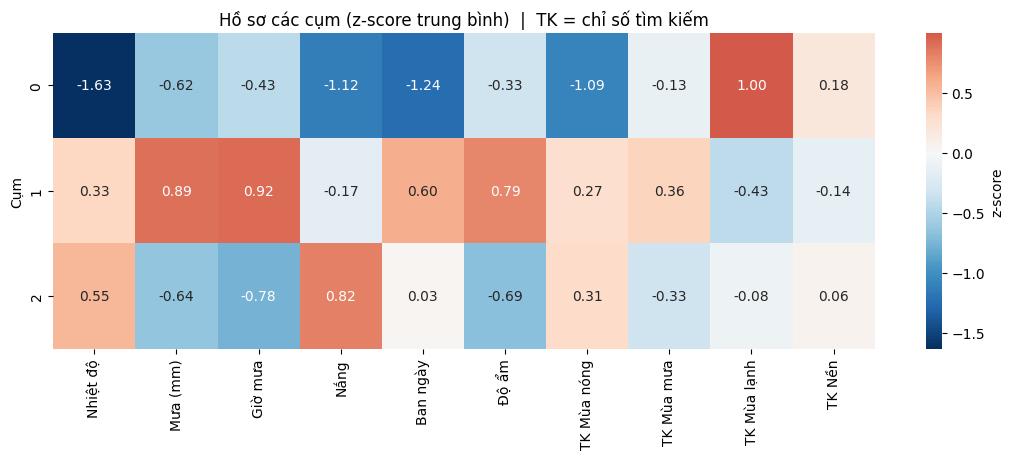

In [67]:
# z-score trung bình
prof_z = pd.DataFrame(X, columns=FEATURES).groupby(df["cluster"]).mean()
prof_z.columns = ["Nhiệt độ", "Mưa (mm)", "Giờ mưa", "Nắng", "Ban ngày", "Độ ẩm", "TK Mùa nóng", "TK Mùa mưa", "TK Mùa lạnh", "TK Nền"]
plt.figure(figsize=(11, 0.9 * K + 2))
sns.heatmap(prof_z, annot=True, fmt=".2f", cmap="RdBu_r", center=0, cbar_kws={"label": "z-score"})
plt.title("Hồ sơ các cụm (z-score trung bình)  |  TK = chỉ số tìm kiếm"); plt.ylabel("Cụm"); plt.tight_layout(); plt.show()

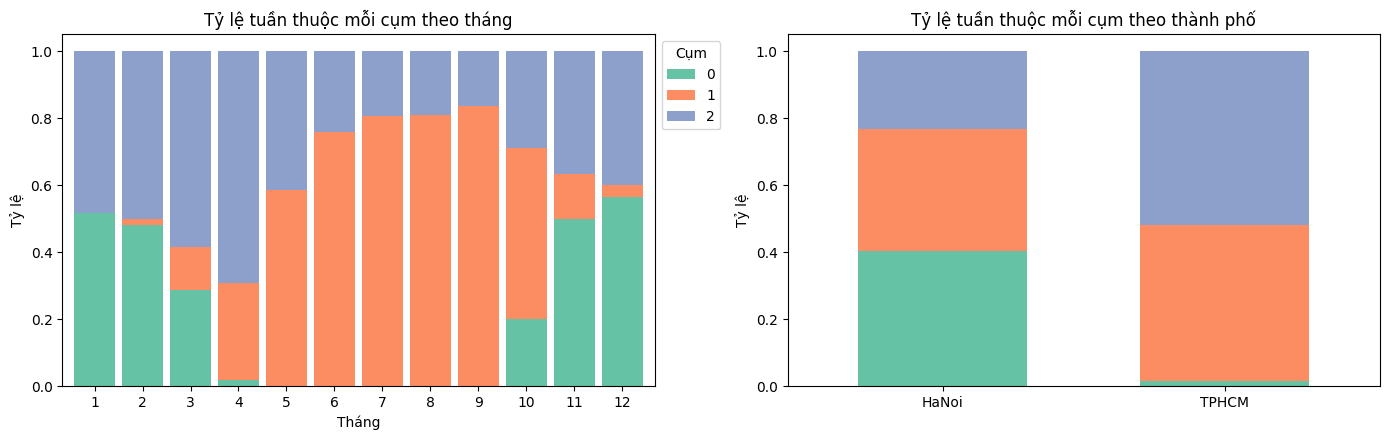

In [68]:
# Cụm phân bố theo tháng và theo thành phố
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ct_m = pd.crosstab(df["month"], df["cluster"], normalize="index")
ct_m.plot(kind="bar", stacked=True, color=pal, ax=ax[0], width=.85)
ax[0].set(title="Tỷ lệ tuần thuộc mỗi cụm theo tháng", xlabel="Tháng", ylabel="Tỷ lệ"); ax[0].legend(title="Cụm", bbox_to_anchor=(1, 1))
ax[0].tick_params(axis="x", rotation=0)

ct_c = pd.crosstab(df["CityName"], df["cluster"], normalize="index")
ct_c.plot(kind="bar", stacked=True, color=pal, ax=ax[1], width=.6, legend=False)
ax[1].set(title="Tỷ lệ tuần thuộc mỗi cụm theo thành phố", xlabel="", ylabel="Tỷ lệ"); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

In [69]:
profile = df.groupby("cluster").agg(
    so_tuan=("date", "size"),
    nhiet_do_C=("temperature_2m_mean", "mean"),
    mua_mm=("precipitation_sum", "mean"),
    gio_mua=("precipitation_hours", "mean"),
    nang_gio=("sunshine_duration", "mean"),
    do_am_pct=("relative_humidity_2m_mean", "mean"),
    TK_mua_nong=("idx_hot", "mean"), TK_mua_mua=("idx_rain", "mean"),
    TK_mua_lanh=("idx_cold", "mean"), TK_nen=("idx_base", "mean"),
)
profile["nang_gio"] = profile["nang_gio"] / 3600
profile = profile.round(1)

# tỷ lệ tuần thuộc Hà Nội trong mỗi cụm (%)
profile["%_HaNoi"] = (df["CityName"] == "HaNoi").groupby(df["cluster"]).mean() * 100
profile["%_HaNoi"] = profile["%_HaNoi"].round(0)

# 3 tháng xuất hiện nhiều nhất trong mỗi cụm
thang = []
for c in range(K):
    top3 = df[df["cluster"] == c]["month"].value_counts().head(3).index.sort_values()
    thang.append(", ".join(map(str, top3)))
profile["thang_noi_bat"] = thang

display(profile)

,so_tuan,nhiet_do_C,mua_mm,gio_mua,nang_gio,do_am_pct,TK_mua_nong,TK_mua_mua,TK_mua_lanh,TK_nen,%_HaNoi,thang_noi_bat
cluster,,,,,,,,,,,,
0,281,19.5,13.1,31.0,5.0,76.1,13.9,13.9,24.9,34.4,96.0,"1, 11, 12"
1,556,27.1,79.4,75.0,7.7,85.6,30.8,19.0,7.2,31.5,44.0,"7, 8, 9"
2,503,28.0,12.3,19.7,10.6,73.1,31.3,11.9,11.5,33.3,31.0,"1, 3, 4"


Cụm 0 - từ khóa cao nhất:
áo len          1.18
áo khoác gió    1.02
áo phao         0.96
áo hoodie       0.93
áo khoác        0.89
quần bò         0.84
Name: 0, dtype: float64
Cụm 0 - từ khóa thấp nhất:
dép sandal      -0.62
quần đùi        -0.74
áo thun         -0.77
áo chống nắng   -0.91
đồ bơi          -1.00
quần short      -1.21
Name: 0, dtype: float64
Cụm 1 - từ khóa cao nhất:
áo mưa        0.60
áo mưa bộ     0.41
đồ bơi        0.33
quần short    0.30
quần đùi      0.27
ô dù          0.25
Name: 1, dtype: float64
Cụm 1 - từ khóa thấp nhất:
áo khoác   -0.36
áo phao    -0.36
mũ len     -0.36
áo nỉ      -0.38
áo len     -0.42
áo dài     -0.45
Name: 1, dtype: float64
Cụm 2 - từ khóa cao nhất:
áo thun          0.38
quần short       0.34
áo chống nắng    0.32
quần tây         0.26
áo sơ mi         0.25
đồ bơi           0.19
Name: 2, dtype: float64
Cụm 2 - từ khóa thấp nhất:
áo len         -0.19
quần bò        -0.22
quần âu        -0.23
áo khoác gió   -0.26
áo mưa bộ      -0.36
áo mưa    

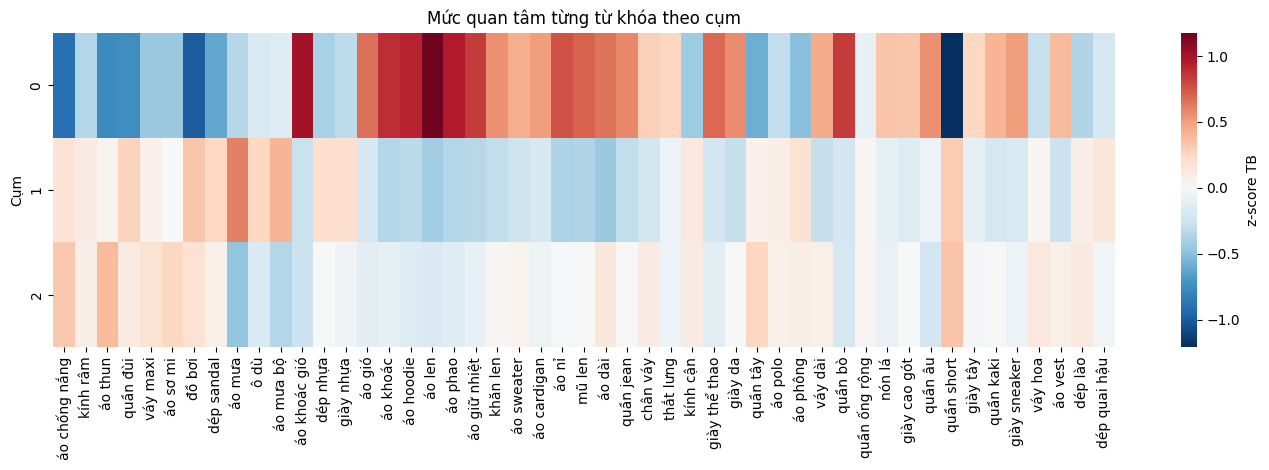

In [70]:
# Từ khóa nổi bật của từng cụm
kw_z = pd.DataFrame(StandardScaler().fit_transform(df[all_kw]), columns=all_kw).groupby(df["cluster"]).mean()
for c in range(K):
    s = kw_z.loc[c].sort_values(ascending=False)
    print(f"Cụm {c} - từ khóa cao nhất:")
    print(s.head(6).round(2))
    print(f"Cụm {c} - từ khóa thấp nhất:")
    print(s.tail(6).round(2))

plt.figure(figsize=(14, 0.6 * K + 3))
ordered = GROUPS["hot"] + GROUPS["rain"] + GROUPS["cold"] + GROUPS["base"]
sns.heatmap(kw_z[ordered], cmap="RdBu_r", center=0, cbar_kws={"label": "z-score TB"})
plt.title("Mức quan tâm từng từ khóa theo cụm"); plt.ylabel("Cụm"); plt.tight_layout(); plt.show()

In [71]:
# Đặt tên cụm
# Nhãn đã được sắp theo nhiệt độ tăng dần với cụm 0 lạnh nhất
if K == 3:
    CLUSTER_NAMES = {0: "Lạnh khô (đông Hà Nội)", 1: "Nóng ẩm, mưa nhiều", 2: "Nóng khô, nắng nhiều"}
else:
    CLUSTER_NAMES = {c: f"Cụm {c}" for c in range(K)}

df["cluster_name"] = df["cluster"].map(CLUSTER_NAMES)
df[["date", "CityName", "cluster", "cluster_name"]].to_csv("cluster_labels.csv", index=False, encoding="utf-8-sig")
profile.rename(index=CLUSTER_NAMES).to_csv("cluster_profile.csv", encoding="utf-8-sig")
kw_z.rename(index=CLUSTER_NAMES).round(2).to_csv("cluster_keyword_zscore.csv", encoding="utf-8-sig")
print("Đã lưu: cluster_labels.csv, cluster_profile.csv, cluster_keyword_zscore.csv")

Đã lưu: cluster_labels.csv, cluster_profile.csv, cluster_keyword_zscore.csv


In [72]:
print(pd.crosstab(df["CityName"], df["cluster"]))
print(pd.crosstab(df["CityName"], df["cluster"], normalize="index"))

cluster     0    1    2
CityName               
HaNoi     271  243  156
TPHCM      10  313  347
cluster          0         1         2
CityName                              
HaNoi     0.404478  0.362687  0.232836
TPHCM     0.014925  0.467164  0.517910


In [73]:
# η² cho từng biến: tỷ lệ biến thiên được 3 cụm giải thích
Z = pd.DataFrame(X, columns=FEATURES)
lab = df["cluster"].values
sst = (Z**2).sum()
ssw = sum(((Z[lab==c] - Z[lab==c].mean())**2).sum() for c in range(K))
eta2 = (1 - ssw/sst).sort_values(ascending=False).round(2)
print(eta2)

# Chênh lệch tâm cụm theo từng cặp
C = Z.groupby(lab).mean()
for a, b in [(0,1), (0,2), (1,2)]:
    d = (C.loc[a] - C.loc[b]).abs().sort_values(ascending=False)
    print(a, b, d.head(4).round(2).to_dict(), "khoảng cách tâm =", round(((C.loc[a]-C.loc[b])**2).sum()**0.5, 2))

temperature_2m_mean          0.72
precipitation_hours          0.62
precipitation_sum            0.56
sunshine_duration            0.53
daylight_duration            0.47
relative_humidity_2m_mean    0.46
idx_hot                      0.32
idx_cold                     0.29
idx_rain                     0.10
idx_base                     0.02
dtype: float64
0 1 {'temperature_2m_mean': 1.96, 'daylight_duration': 1.83, 'precipitation_sum': 1.51, 'idx_cold': 1.43} khoảng cách tâm = 4.21
0 2 {'temperature_2m_mean': 2.18, 'sunshine_duration': 1.94, 'idx_hot': 1.41, 'daylight_duration': 1.27} khoảng cách tâm = 3.68
1 2 {'precipitation_hours': 1.7, 'precipitation_sum': 1.53, 'relative_humidity_2m_mean': 1.47, 'sunshine_duration': 0.99} khoảng cách tâm = 3.06


# Import thư viện

In [74]:
# Kiểm tra XGBoost
try:
    import xgboost
except ImportError:
    !pip install -q xgboost
    import xgboost
print("XGBoost:", xgboost.__version__)

XGBoost: 3.4.1


In [75]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [76]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import ParameterGrid, ParameterSampler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, roc_auc_score,
                             average_precision_score, confusion_matrix)

In [77]:
warnings.filterwarnings("ignore")
random_state = 42
np.random.seed(random_state)

In [78]:
# Thư mục lưu kết quả
output_dir = "/content/output_classification/"
os.makedirs(output_dir, exist_ok=True)

In [80]:
# Kết nối với google drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [81]:
# Load file clean_data.csv
df_clean = ("/content/drive/MyDrive/dth/data mining/clean_data.csv")

# Đọc dữ liệu và chuyển sang Long Format

`clean_data.csv` gồm 670 tuần × 2 thành phố, mỗi dòng có 49 cột từ khóa và các cột thời tiết. Dữ liệu gốc `df_raw` được giữ nguyên; mọi xử lý thực hiện trên bản sao.

In [84]:
import pandas as pd
import os

# Fix: Since clean_data.csv is missing on Drive, we combine the locally created clean files
local_hanoi = "/content/clean_data_HaNoi.csv"
local_tphcm = "/content/clean_data_TPHCM.csv"

if os.path.exists(local_hanoi) and os.path.exists(local_tphcm):
    df_hanoi_local = pd.read_csv(local_hanoi, parse_dates=["date"])
    df_tphcm_local = pd.read_csv(local_tphcm, parse_dates=["date"])
    df_hanoi_local["CityName"] = "HaNoi"
    df_tphcm_local["CityName"] = "TPHCM"
    df_raw = pd.concat([df_hanoi_local, df_tphcm_local], ignore_index=True)
    print("Loaded and combined local clean files successfully.")
else:
    # Fallback to drive path if local files are missing
    df_raw = pd.read_csv(df_clean, parse_dates=["date"], encoding="utf-8-sig")

df = df_raw.copy()
print("Kích thước:", df.shape)
print(df.groupby("CityName")["date"].agg(["min", "max", "count"]))

Loaded and combined local clean files successfully.
Kích thước: (1340, 75)
                min        max  count
CityName                             
HaNoi    2013-12-29 2026-10-25    670
TPHCM    2013-12-29 2026-10-25    670


In [85]:
# 49 từ khóa chia theo 4 nhóm
keyword_groups = {
    "hot": ["áo chống nắng", "kính râm", "áo thun", "quần đùi", "váy maxi", "áo sơ mi", "đồ bơi", "dép sandal"],
    "rain": ["áo mưa", "ô dù", "áo mưa bộ", "áo khoác gió", "dép nhựa", "giày nhựa", "áo gió"],
    "cold": ["áo khoác", "áo hoodie", "áo len", "áo phao", "áo giữ nhiệt", "khăn len", "áo sweater",
             "áo cardigan", "áo nỉ", "mũ len"],
    "base": ["áo dài", "quần jean", "chân váy", "thắt lưng", "kính cận", "giày thể thao", "giày da", "quần tây",
             "áo polo", "áo phông", "váy dài", "quần bò", "quần ống rộng", "nón lá", "giày cao gót", "quần âu",
             "quần short", "giày tây", "quần kaki", "giày sneaker", "váy hoa", "áo vest", "dép lào", "dép quai hậu"],
}
group_of = {kw: group for group, kw_list in keyword_groups.items() for kw in kw_list}
keywords = list(group_of.keys())
assert len(keywords) == 49 and set(keywords) == set(df.columns[1:50]), "Danh sách từ khóa không khớp với dữ liệu"

In [86]:
# Chuyển sang Long Format: mỗi dòng = 1 tuần × 1 thành phố × 1 từ khóa
long_df = df.melt(id_vars=["CityName", "date"], value_vars=keywords,
                  var_name="keyword", value_name="interest")
long_df = long_df.rename(columns={"CityName": "city"})
long_df["kw_group"] = long_df["keyword"].map(group_of)
long_df = long_df.sort_values(["city", "keyword", "date"]).reset_index(drop=True)

In [87]:
# Bảng thời tiết theo thành phố × tuần
weather_raw_cols = [c for c in df.columns if c not in keywords + ["date", "CityName"]]
wx = df[["CityName", "date"] + weather_raw_cols].rename(columns={"CityName": "city"})

In [88]:
# Kiểm tra: đủ dòng, mỗi chuỗi cách nhau đúng 1 tuần, mỗi tuần đúng một mã thời tiết
assert len(long_df) == 670 * 2 * 49
assert (long_df.groupby(["city", "keyword"])["date"].diff().dropna() == pd.Timedelta(days=7)).all()
assert (df[[c for c in df.columns if c.startswith("weather_")]].sum(axis=1) == 1).all()

long_df.to_csv(output_dir + "long_data.csv", index=False, encoding="utf-8-sig")
print("Long Format:", long_df.shape)

Long Format: (65660, 5)


# Tạo nhãn Hot/ Normal

Với mỗi chuỗi (thành phố × từ khóa), ngưỡng P80 của tuần t được tính từ **52 tuần trước đó** (`shift(1)` để không dùng tuần t).
- `hot = 1` nếu Search Interest > P80, `hot = 0` nếu ≤ P80.
- 52 tuần đầu chưa đủ lịch sử nên không có nhãn.
- Nếu P80 = 0 thì nhãn không xác định (để trống, không gán Normal).

In [89]:
def make_labels(long_in):
    out = long_in.sort_values(["city", "keyword", "date"]).reset_index(drop=True)
    out["p80"] = out.groupby(["city", "keyword"])["interest"].transform(
        lambda s: s.shift(1).rolling(52, min_periods=52).quantile(0.80))
    out["hot"] = (out["interest"] > out["p80"]).astype(float)
    out.loc[out["p80"].isna() | (out["p80"] == 0), "hot"] = np.nan   # nhãn không xác định
    return out

labels = make_labels(long_df)

In [90]:
# Trạng thái từng dòng: ok / warmup (chưa đủ 52 tuần) / p80_zero (ngưỡng bằng 0)
labels["status"] = "ok"
labels.loc[labels["p80"].isna(), "status"] = "warmup"
labels.loc[labels["p80"] == 0, "status"] = "p80_zero"
print(labels["status"].value_counts())
print("\nSố dòng P80 = 0 theo thành phố:")
print(labels[labels["status"] == "p80_zero"].groupby("city").size())

status
ok          54399
p80_zero     6165
warmup       5096
Name: count, dtype: int64

Số dòng P80 = 0 theo thành phố:
city
HaNoi    2377
TPHCM    3788
dtype: int64


In [91]:
# Kiểm tra P80: tính lại bằng np.percentile cho một chuỗi mẫu
sample = labels[(labels["city"] == "HaNoi") & (labels["keyword"] == "áo thun")].reset_index(drop=True)
values = sample["interest"].values
manual_p80 = [np.percentile(values[t - 52:t], 80) for t in range(52, len(values))]
assert sample["p80"].iloc[:52].isna().all()
assert np.allclose(sample["p80"].iloc[52:].values, manual_p80)
print("Đã kiểm tra P80: khớp với cách tính thủ công.")

Đã kiểm tra P80: khớp với cách tính thủ công.


In [92]:
# Hai chuỗi cần loại: kiểm tra xem có đúng là hai chuỗi ít nhãn nhất không
label_count = labels.groupby(["city", "keyword"])["hot"].count()
print("5 chuỗi có ít nhãn nhất:")
print(label_count.sort_values().head(5))
drop_series = [("HaNoi", "dép lào"), ("TPHCM", "dép quai hậu")]
assert set(label_count.sort_values().head(2).index) == set(drop_series), "Hai chuỗi cần loại không khớp dữ liệu"

labels["excluded"] = [(c, k) in drop_series for c, k in zip(labels["city"], labels["keyword"])]
labels.to_csv(output_dir + "labels_p80.csv", index=False, encoding="utf-8-sig")

5 chuỗi có ít nhãn nhất:
city   keyword     
HaNoi  dép lào           0
TPHCM  dép quai hậu      3
       áo khoác gió    135
HaNoi  dép nhựa        211
TPHCM  áo giữ nhiệt    216
Name: hot, dtype: int64


# Feature Engineering

Thứ tự xử lý: tính toàn bộ lag/rolling trên **chuỗi thời gian đầy đủ** (kể cả các tuần chưa có nhãn và hai chuỗi bị loại), sau đó mới lọc dòng.
- Search Interest và label history: nhóm theo thành phố × từ khóa.
- Weather history: nhóm theo thành phố.
- Mọi lag/rolling chỉ dùng dữ liệu đến tuần t−1; `rel_lag1`, `rel_mean4` chia cho P80 của tuần t (P80 chỉ dùng lịch sử trước t).

In [93]:
def make_history_features(lab):
    # Feature lịch sử tìm kiếm và nhãn, chỉ dùng dữ liệu đến tuần t-1
    out = lab.copy()
    p80_safe = out["p80"].replace(0, np.nan)
    out["hot_known"] = out["hot"].fillna(0)
    out["hot_unknown"] = out["hot"].isna().astype(float)
    out["is_zero"] = (out["interest"] == 0).astype(float)
    g = out.groupby(["city", "keyword"])

    out["rel_lag1"] = g["interest"].shift(1) / p80_safe
    out["rel_mean4"] = g["interest"].transform(lambda s: s.shift(1).rolling(4, min_periods=4).mean()) / p80_safe
    out["zero_share52"] = g["is_zero"].transform(lambda s: s.shift(1).rolling(52, min_periods=52).mean())

    hot_prev = g["hot"].shift(1)
    out["hot_lag1_missing"] = hot_prev.isna().astype(int)
    out["hot_lag1"] = hot_prev.fillna(0)
    out["hot_cnt4"] = g["hot_known"].transform(lambda s: s.shift(1).rolling(4, min_periods=4).sum())
    out["hot_missing_cnt4"] = g["hot_unknown"].transform(lambda s: s.shift(1).rolling(4, min_periods=4).sum())
    return out.drop(columns=["hot_known", "hot_unknown", "is_zero"])

In [94]:
def make_weather_features(wx_in):
    # Feature thời tiết, lag/rolling nhóm theo thành phố
    w = wx_in.sort_values(["city", "date"]).reset_index(drop=True)
    out = pd.DataFrame({"city": w["city"], "date": w["date"]})
    out["temp_mean"] = w["temperature_2m_mean"]
    out["temp_range"] = w["temperature_2m_max"] - w["temperature_2m_min"]
    out["precip_sum"] = w["precipitation_sum"]
    out["rh_mean"] = w["relative_humidity_2m_mean"]
    out["sunshine"] = w["sunshine_duration"]

    # Nhóm thời tiết: 0-3 quang/mây, 51/53/55 mưa phùn, 61/63/65 mưa
    out["wx_dry"] = w[["weather_0", "weather_1", "weather_2", "weather_3"]].sum(axis=1).astype(int)
    out["wx_drizzle"] = w[["weather_51", "weather_53", "weather_55"]].sum(axis=1).astype(int)
    out["wx_rain"] = w[["weather_61", "weather_63", "weather_65"]].sum(axis=1).astype(int)

    g = out.groupby("city")
    out["temp_mean_lag1"] = g["temp_mean"].shift(1)
    out["temp_mean_lag2"] = g["temp_mean"].shift(2)
    out["precip_sum_lag1"] = g["precip_sum"].shift(1)
    out["precip_sum_lag2"] = g["precip_sum"].shift(2)
    out["d_temp"] = out["temp_mean"] - out["temp_mean_lag1"]
    out["temp_dev4"] = out["temp_mean"] - g["temp_mean"].transform(lambda s: s.shift(1).rolling(4, min_periods=4).mean())
    out["precip_dev4"] = out["precip_sum"] - g["precip_sum"].transform(lambda s: s.shift(1).rolling(4, min_periods=4).mean())
    return out

In [95]:
# Ghép feature lịch sử và thời tiết vào bảng nhãn (chưa lọc dòng nào)
data = make_history_features(labels)
data = data.merge(make_weather_features(wx), on=["city", "date"], how="left", validate="many_to_one")
assert len(data) == len(labels)

In [96]:
# Calendar: tuần trong năm (sin/cos) và khoảng cách tới Tết gần nhất
data["woy"] = data["date"].dt.isocalendar().week.astype(int)
data["woy_sin"] = np.sin(2 * np.pi * data["woy"] / 52)
data["woy_cos"] = np.cos(2 * np.pi * data["woy"] / 52)

In [97]:
# Mùng 1 Tết các năm 2014-2027; tet_offset > 0: tuần nằm trước Tết (đơn vị: tuần)
tet_dates = pd.to_datetime(["2014-01-31", "2015-02-19", "2016-02-08", "2017-01-28", "2018-02-16",
                            "2019-02-05", "2020-01-25", "2021-02-12", "2022-02-01", "2023-01-22",
                            "2024-02-10", "2025-01-29", "2026-02-17", "2027-02-06"])
tet_offset_by_week = {}
for week_start in data["date"].unique():
    days = (tet_dates - pd.Timestamp(week_start)).days.values
    tet_offset_by_week[week_start] = days[np.abs(days).argmin()] / 7
data["tet_offset"] = data["date"].map(tet_offset_by_week)

In [98]:
# Identity: thành phố, nhóm từ khóa, từ khóa (one-hot)
data["city_TPHCM"] = (data["city"] == "TPHCM").astype(int)
kwg_dummies = pd.get_dummies(data["kw_group"], prefix="kwg").astype(int)
kw_dummies = pd.get_dummies(data["keyword"], prefix="kw").astype(int)
data = pd.concat([data, kwg_dummies, kw_dummies], axis=1)

In [99]:
# Danh sách feature của từng nhóm
calendar_cols = ["woy_sin", "woy_cos", "tet_offset"]
kwg_cols = list(kwg_dummies.columns)
kw_cols = list(kw_dummies.columns)
identity_cols = ["city_TPHCM"] + kwg_cols + kw_cols
weather_cols = (["temp_mean", "temp_range", "precip_sum", "rh_mean", "sunshine"]
                + ["wx_dry", "wx_drizzle", "wx_rain"]
                + ["temp_mean_lag1", "temp_mean_lag2", "precip_sum_lag1", "precip_sum_lag2"]
                + ["d_temp", "temp_dev4", "precip_dev4"])
search_cols = (["rel_lag1", "rel_mean4", "zero_share52"]
               + ["hot_lag1", "hot_lag1_missing", "hot_cnt4", "hot_missing_cnt4"])

feats_s0 = calendar_cols + identity_cols
feats_s1 = feats_s0 + weather_cols
feats_s2 = feats_s1 + search_cols
feature_sets = {"S0": feats_s0, "S1": feats_s1, "S2": feats_s2}
feature_group = {c: "Calendar" for c in calendar_cols}
feature_group.update({c: "Identity" for c in identity_cols})
feature_group.update({c: "Weather" for c in weather_cols})
feature_group.update({c: "Search History" for c in search_cols})

print("Số feature S0 / S1 / S2:", len(feats_s0), len(feats_s1), len(feats_s2))

Số feature S0 / S1 / S2: 57 72 79


In [100]:
# Báo cáo thiếu dữ liệu: trước khi lọc (toàn bộ dòng) và sau khi lọc (dòng đưa vào mô hình)
model_data = data[(data["status"] == "ok") & (~data["excluded"])].copy()
model_data["hot"] = model_data["hot"].astype(int)

missing_report = pd.DataFrame({
    "feature": feats_s2,
    "nhom": [feature_group[c] for c in feats_s2],
    "thieu_truoc_khi_loc": data[feats_s2].isna().sum().values,
    "thieu_sau_khi_loc": model_data[feats_s2].isna().sum().values})
print("Số dòng toàn bộ:", len(data), "| số dòng đưa vào mô hình:", len(model_data))
print(missing_report[missing_report["thieu_truoc_khi_loc"] > 0].to_string(index=False))
missing_report.to_csv(output_dir + "bao_cao_thieu_feature.csv", index=False, encoding="utf-8-sig")

Số dòng toàn bộ: 65660 | số dòng đưa vào mô hình: 54396
         feature           nhom  thieu_truoc_khi_loc  thieu_sau_khi_loc
  temp_mean_lag1        Weather                   98                  0
  temp_mean_lag2        Weather                  196                  0
 precip_sum_lag1        Weather                   98                  0
 precip_sum_lag2        Weather                  196                  0
          d_temp        Weather                   98                  0
       temp_dev4        Weather                  392                  0
     precip_dev4        Weather                  392                  0
        rel_lag1 Search History                11261                  0
       rel_mean4 Search History                11261                  0
    zero_share52 Search History                 5096                  0
        hot_cnt4 Search History                  392                  0
hot_missing_cnt4 Search History                  392                  0


In [101]:
# Kiểm tra feature
assert (len(feats_s0), len(feats_s1), len(feats_s2)) == (57, 72, 79)
assert set(feats_s0) < set(feats_s1) < set(feats_s2)                      # S0 ⊂ S1 ⊂ S2
assert len(kwg_cols) == 4 and len(kw_cols) == 49
forbidden = ["month_sin", "month_cos", "wx_level", "rel_lag2", "rel_lag4", "rel_mean12",
             "rain_sum", "temp_anom", "precip_anom", "interest", "hot", "p80"]
assert not any(c in forbidden or c.startswith("apparent_") for c in feats_s2)   # không có feature bị cấm
assert (data[["wx_dry", "wx_drizzle", "wx_rain"]].sum(axis=1) == 1).all()        # one-hot đúng 1 nhóm / tuần
assert model_data[feats_s2].isna().sum().sum() == 0                              # không còn missing
assert np.isfinite(model_data[feats_s2].values).all()
print("Các kiểm tra feature đều đạt.")

Các kiểm tra feature đều đạt.


In [102]:
# Kiểm tra leakage: sửa dữ liệu tại tuần T rồi tính lại feature.
# Các feature chỉ dùng quá khứ thì KHÔNG được thay đổi ở các tuần trước T (và ở tuần T với feature lag).
t_index = 300
test_date = sample["date"].iloc[t_index]          # tuần T của chuỗi Hà Nội - áo thun
long_alt = long_df.copy()
mask = (long_alt["city"] == "HaNoi") & (long_alt["keyword"] == "áo thun") & (long_alt["date"] == test_date)
old_value = long_alt.loc[mask, "interest"].iloc[0]
long_alt.loc[mask, "interest"] = 100.0 if old_value < 50 else 0.0

wx_alt = wx.copy()
wx_mask = (wx_alt["city"] == "HaNoi") & (wx_alt["date"] == test_date)
wx_alt.loc[wx_mask, "temperature_2m_mean"] += 10
wx_alt.loc[wx_mask, "precipitation_sum"] += 50

data_alt = make_history_features(make_labels(long_alt))
data_alt = data_alt.merge(make_weather_features(wx_alt), on=["city", "date"], how="left")

compare_cols = ["p80", "hot"] + search_cols + weather_cols
before = data["date"] < test_date
assert np.allclose(data.loc[before, compare_cols].astype(float).values,
                   data_alt.loc[before, compare_cols].astype(float).values, equal_nan=True)

In [103]:
# Tại đúng tuần T: các feature lag / lịch sử (không phải dữ liệu hiện tại) vẫn phải giữ nguyên
history_only = ["p80"] + search_cols + ["temp_mean_lag1", "temp_mean_lag2", "precip_sum_lag1", "precip_sum_lag2"]
at_t = data["date"] == test_date
assert np.allclose(data.loc[at_t, history_only].astype(float).values,
                   data_alt.loc[at_t, history_only].astype(float).values, equal_nan=True)

In [104]:
# Đối chứng: tuần T+1 phải thay đổi (chứng tỏ việc sửa dữ liệu có tác dụng)
next_date = test_date + pd.Timedelta(days=7)
row_a = data[(data["city"] == "HaNoi") & (data["keyword"] == "áo thun") & (data["date"] == next_date)]["rel_lag1"].iloc[0]
row_b = data_alt[(data_alt["city"] == "HaNoi") & (data_alt["keyword"] == "áo thun") & (data_alt["date"] == next_date)]["rel_lag1"].iloc[0]
assert row_a != row_b
print("Kiểm tra leakage đạt: sửa dữ liệu tuần", test_date.date(), "không ảnh hưởng ngược về trước.")

Kiểm tra leakage đạt: sửa dữ liệu tuần 2019-09-29 không ảnh hưởng ngược về trước.


In [105]:
# Bảng mô tả feature và lưu dữ liệu feature
description = {
    "woy_sin": "sin của tuần trong năm (chu kỳ 52 tuần)", "woy_cos": "cos của tuần trong năm (chu kỳ 52 tuần)",
    "tet_offset": "số tuần từ đầu tuần tới Tết gần nhất (dương = trước Tết)",
    "city_TPHCM": "1 nếu là TP.HCM, 0 nếu là Hà Nội",
    "temp_mean": "nhiệt độ trung bình tuần", "temp_range": "biên độ nhiệt (max - min)",
    "precip_sum": "tổng lượng giáng thủy tuần", "rh_mean": "độ ẩm tương đối trung bình",
    "sunshine": "thời gian có nắng (giây)",
    "wx_dry": "thời tiết quang/mây (mã 0-3)", "wx_drizzle": "mưa phùn (mã 51/53/55)", "wx_rain": "mưa (mã 61/63/65)",
    "temp_mean_lag1": "nhiệt độ trung bình tuần t-1", "temp_mean_lag2": "nhiệt độ trung bình tuần t-2",
    "precip_sum_lag1": "lượng giáng thủy tuần t-1", "precip_sum_lag2": "lượng giáng thủy tuần t-2",
    "d_temp": "thay đổi nhiệt độ so với tuần trước", "temp_dev4": "nhiệt độ tuần t trừ trung bình 4 tuần trước",
    "precip_dev4": "lượng giáng thủy tuần t trừ trung bình 4 tuần trước",
    "rel_lag1": "Search Interest tuần t-1 chia P80 của tuần t",
    "rel_mean4": "trung bình Search Interest 4 tuần trước chia P80 của tuần t",
    "zero_share52": "tỷ lệ tuần có Search Interest = 0 trong 52 tuần trước",
    "hot_lag1": "nhãn Hot tuần t-1 (điền 0 nếu chưa xác định)", "hot_lag1_missing": "1 nếu nhãn tuần t-1 chưa xác định",
    "hot_cnt4": "số tuần Hot (đã biết) trong 4 tuần trước", "hot_missing_cnt4": "số tuần chưa có nhãn trong 4 tuần trước"}
feature_table = pd.DataFrame({"feature": feats_s2})
feature_table["nhom"] = feature_table["feature"].map(feature_group)
feature_table["tap_feature"] = ["S0" if c in feats_s0 else "S1" if c in feats_s1 else "S2" for c in feats_s2]
feature_table["mo_ta"] = [description.get(c, "one-hot nhóm từ khóa" if c.startswith("kwg_") else "one-hot từ khóa")
                          for c in feats_s2]
feature_table.to_csv(output_dir + "bang_mo_ta_feature.csv", index=False, encoding="utf-8-sig")

id_cols = ["city", "date", "keyword", "kw_group", "interest", "p80", "hot"]
model_data[id_cols + feats_s2].to_csv(output_dir + "features_buoc5.csv.gz", index=False,
                                      encoding="utf-8-sig", compression="gzip")
print(feature_table["tap_feature"].value_counts())

tap_feature
S0    57
S1    15
S2     7
Name: count, dtype: int64


# Chia dữ liệu theo thời gian và Time Series Cross-Validation

Chia theo mốc thời gian, không chia ngẫu nhiên; mọi quan sát cùng một tuần nằm trong cùng một tập.

In [106]:
train_end = pd.Timestamp("2022-12-25")
val_start, val_end = pd.Timestamp("2023-01-01"), pd.Timestamp("2023-12-31")
test_start, test_end = pd.Timestamp("2024-01-07"), pd.Timestamp("2026-10-25")

model_data["split"] = np.select(
    [model_data["date"] <= train_end,
     (model_data["date"] >= val_start) & (model_data["date"] <= val_end),
     (model_data["date"] >= test_start) & (model_data["date"] <= test_end)],
    ["train", "val", "test"], default="none")
assert (model_data["split"] != "none").all()

In [107]:
# Không tuần nào xuất hiện ở nhiều tập
weeks_train = set(model_data.loc[model_data["split"] == "train", "date"])
weeks_val = set(model_data.loc[model_data["split"] == "val", "date"])
weeks_test = set(model_data.loc[model_data["split"] == "test", "date"])
assert not (weeks_train & weeks_val) and not (weeks_train & weeks_test) and not (weeks_val & weeks_test)

train = model_data[model_data["split"] == "train"].reset_index(drop=True)
val = model_data[model_data["split"] == "val"].reset_index(drop=True)
test = model_data[model_data["split"] == "test"].reset_index(drop=True)

split_summary = model_data.groupby("split").agg(
    so_dong=("hot", "size"), so_tuan=("date", "nunique"),
    tu_ngay=("date", "min"), den_ngay=("date", "max"), ty_le_hot=("hot", "mean")).loc[["train", "val", "test"]]
print(split_summary)

y_train, y_val, y_test = train["hot"].values, val["hot"].values, test["hot"].values

       so_dong  so_tuan    tu_ngay   den_ngay  ty_le_hot
split                                                   
train    36607      418 2014-12-28 2022-12-25   0.218701
val       5010       53 2023-01-01 2023-12-31   0.110978
test     12779      147 2024-01-07 2026-10-25   0.149307


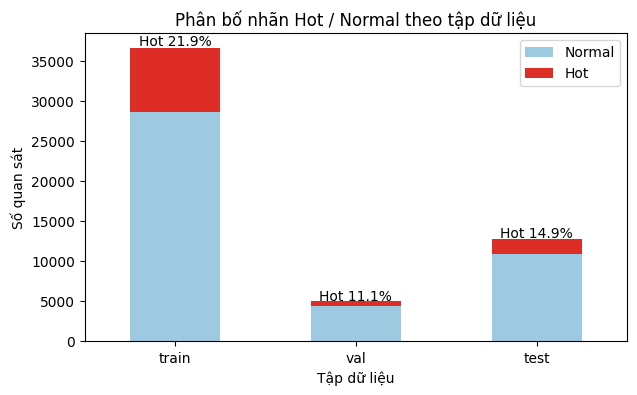

In [108]:
# Biểu đồ 1: phân bố nhãn Hot / Normal theo từng tập
label_count = model_data.groupby(["split", "hot"]).size().unstack().loc[["train", "val", "test"]]
label_count.columns = ["Normal", "Hot"]
ax = label_count.plot(kind="bar", stacked=True, figsize=(7, 4), color=["#9ecae1", "#de2d26"])
for i, split_name in enumerate(label_count.index):
    hot_pct = label_count.loc[split_name, "Hot"] / label_count.loc[split_name].sum() * 100
    ax.text(i, label_count.loc[split_name].sum() * 1.01, f"Hot {hot_pct:.1f}%", ha="center")
plt.title("Phân bố nhãn Hot / Normal theo tập dữ liệu")
plt.xlabel("Tập dữ liệu"); plt.ylabel("Số quan sát"); plt.xticks(rotation=0)
plt.savefig(output_dir + "bieu_do_phan_bo_nhan.png", dpi=150, bbox_inches="tight")
plt.show()

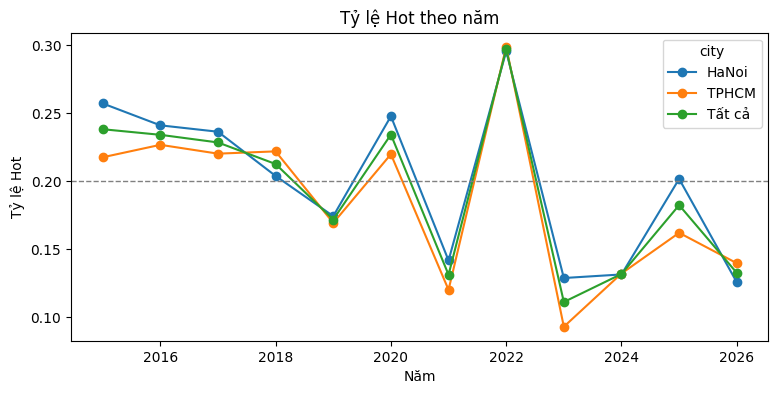

In [109]:
# Biểu đồ 2: tỷ lệ Hot theo năm (bỏ năm 2014 vì chỉ có 1 tuần có nhãn; năm 2026 mới đến tháng 10)
by_year = model_data[model_data["date"].dt.year != 2014].copy()
by_year["year"] = by_year["date"].dt.year
hot_by_year = by_year.groupby(["year", "city"])["hot"].mean().unstack()
hot_by_year["Tất cả"] = by_year.groupby("year")["hot"].mean()
hot_by_year.plot(marker="o", figsize=(9, 4))
plt.axhline(0.2, color="gray", linestyle="--", linewidth=1)
plt.title("Tỷ lệ Hot theo năm"); plt.xlabel("Năm"); plt.ylabel("Tỷ lệ Hot")
plt.savefig(output_dir + "bieu_do_ty_le_hot_theo_nam.png", dpi=150, bbox_inches="tight")
plt.show()

In [110]:
# Time Series CV: expanding window theo tuần trên tập Train (số tuần có nhãn)
train_weeks = np.sort(train["date"].unique())
assert len(train_weeks) == 418

fold_sizes = [(156, 66), (222, 66), (288, 65), (353, 65)]    # (số tuần train, số tuần validation)
fold_idx = []        # (chỉ số dòng train, chỉ số dòng validation) của từng fold
fold_rows = []
for i, (n_tr, n_va) in enumerate(fold_sizes, start=1):
    tr_weeks = train_weeks[:n_tr]
    va_weeks = train_weeks[n_tr:n_tr + n_va]
    assert tr_weeks[-1] < va_weeks[0]                       # validation luôn sau train
    tr_idx = np.where(train["date"].isin(tr_weeks))[0]
    va_idx = np.where(train["date"].isin(va_weeks))[0]
    fold_idx.append((tr_idx, va_idx))
    fold_rows.append({"fold": i, "train_weeks": n_tr, "val_weeks": n_va,
                      "train_start": tr_weeks[0], "train_end": tr_weeks[-1],
                      "val_start": va_weeks[0], "val_end": va_weeks[-1],
                      "train_rows": len(tr_idx), "val_rows": len(va_idx)})
tscv_folds = pd.DataFrame(fold_rows)
assert [n for n, _ in fold_sizes[1:]] == [a + b for a, b in fold_sizes[:-1]][:3]      # expanding window
assert fold_sizes[-1][0] + fold_sizes[-1][1] == len(train_weeks)
print(tscv_folds.to_string(index=False))
tscv_folds.to_csv(output_dir + "tscv_folds.csv", index=False, encoding="utf-8-sig")

 fold  train_weeks  val_weeks train_start  train_end  val_start    val_end  train_rows  val_rows
    1          156         66  2014-12-28 2017-12-17 2017-12-24 2019-03-24       13228      5772
    2          222         66  2014-12-28 2019-03-24 2019-03-31 2020-06-28       19000      5826
    3          288         65  2014-12-28 2020-06-28 2020-07-05 2021-09-26       24826      5943
    4          353         65  2014-12-28 2021-09-26 2021-10-03 2022-12-25       30769      5838


In [111]:
# Các dòng thuộc validation của ít nhất một fold (dùng cho out-of-fold prediction)
oof_mask = np.zeros(len(train), dtype=bool)
for _, va_idx in fold_idx:
    oof_mask[va_idx] = True
y_oof = y_train[oof_mask]

# Baseline

- **Majority (Always Normal):** luôn dự đoán lớp chiếm đa số trong Train.
- **Persistence:** dự đoán nhãn bằng nhãn tuần trước. Dòng nào không có nhãn tuần trước hợp lệ thì **không đánh giá** (không gán Normal), và báo cáo tỷ lệ dòng được đánh giá (`coverage`).

In [112]:
def evaluate(y_true, y_prob, threshold=0.5):
    # Tính các chỉ số đánh giá cho lớp Hot (lớp 1) tại một ngưỡng
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1_hot": f1_score(y_true, y_pred, zero_division=0),
            "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
            "balanced_acc": balanced_accuracy_score(y_true, y_pred),
            "roc_auc": roc_auc_score(y_true, y_prob),
            "pr_auc": average_precision_score(y_true, y_prob),
            "tn": tn, "fp": fp, "fn": fn, "tp": tp}

majority_class = int(y_train.mean() > 0.5)       # = 0 (Normal) nếu Hot chiếm dưới 50%
baseline_rows = []

In [113]:
for split_name, part in [("val", val), ("test", test)]:
    # Majority
    row = {"baseline": "Majority (Always Normal)", "split": split_name, "n_rows": len(part), "coverage": 1.0}
    row.update(evaluate(part["hot"].values, np.full(len(part), majority_class)))
    baseline_rows.append(row)
    # Persistence: chỉ đánh giá các dòng có nhãn tuần trước hợp lệ
    valid = part[part["hot_lag1_missing"] == 0]
    row = {"baseline": "Persistence", "split": split_name, "n_rows": len(valid), "coverage": len(valid) / len(part)}
    row.update(evaluate(valid["hot"].values, valid["hot_lag1"].values))
    baseline_rows.append(row)

baseline_results = pd.DataFrame(baseline_rows)
print(baseline_results[["baseline", "split", "n_rows", "coverage", "accuracy", "precision", "recall",
                        "f1_hot", "balanced_acc"]].round(3).to_string(index=False))
baseline_results.to_csv(output_dir + "baseline_results.csv", index=False, encoding="utf-8-sig")

                baseline split  n_rows  coverage  accuracy  precision  recall  f1_hot  balanced_acc
Majority (Always Normal)   val    5010     1.000     0.889      0.000   0.000   0.000         0.500
             Persistence   val    5008     1.000     0.888      0.494   0.519   0.506         0.726
Majority (Always Normal)  test   12779     1.000     0.851      0.000   0.000   0.000         0.500
             Persistence  test   12763     0.999     0.852      0.503   0.508   0.505         0.710


# Tuning bằng Time Series CV

- Mỗi mô hình được tuning **riêng cho từng tập feature** S0, S1, S2.
- Decision Tree: thử toàn bộ lưới nhỏ. Random Forest và XGBoost: lấy ngẫu nhiên 8 tổ hợp từ lưới (mức tuning vừa phải).
- Tiêu chí chọn tham số: **F1 của lớp Hot** trung bình trên 4 fold (ngưỡng 0.5). Các tham số `class_weight` / `scale_pos_weight` cho phép so sánh có và không có trọng số lớp.
- Đồng thời lưu out-of-fold prediction để phân tích ngưỡng ở bước sau.

In [114]:
def make_model(model_name, params):
    if model_name == "Decision Tree":
        return DecisionTreeClassifier(random_state=random_state, **params)
    if model_name == "Random Forest":
        return RandomForestClassifier(random_state=random_state, n_jobs=-1, **params)
    return XGBClassifier(random_state=random_state, n_jobs=-1, tree_method="hist",
                         eval_metric="logloss", **params)

pos_weight = float(round((y_train == 0).sum() / (y_train == 1).sum(), 1))     # tỷ lệ Normal / Hot trong Train

dt_grid = {"max_depth": [4, 6, 8], "min_samples_split": [20, 100], "min_samples_leaf": [10, 50],
           "class_weight": [None, "balanced"]}
rf_grid = {"n_estimators": [100, 200], "max_depth": [6, 10], "min_samples_split": [20, 100],
           "min_samples_leaf": [10, 50], "max_features": ["sqrt", 0.3],
           "class_weight": [None, "balanced_subsample"]}
xgb_grid = {"n_estimators": [100, 200], "max_depth": [3, 5], "learning_rate": [0.05, 0.1],
            "subsample": [0.8, 1.0], "colsample_bytree": [0.5, 0.8], "scale_pos_weight": [1, pos_weight]}

param_lists = {"Decision Tree": list(ParameterGrid(dt_grid)),
               "Random Forest": list(ParameterSampler(rf_grid, n_iter=8, random_state=random_state)),
               "XGBoost": list(ParameterSampler(xgb_grid, n_iter=8, random_state=random_state))}
model_names = list(param_lists.keys())

cv_rows = []
oof_store = {}       # (model, tập feature, combo) -> xác suất out-of-fold

In [115]:
for model_name in model_names:
    for set_name, cols in feature_sets.items():
        x_train = train[cols].values
        for combo_id, params in enumerate(param_lists[model_name]):
            fold_scores = []
            oof_prob = np.full(len(train), np.nan)
            for tr_idx, va_idx in fold_idx:
                model = make_model(model_name, params)
                model.fit(x_train[tr_idx], y_train[tr_idx])
                prob = model.predict_proba(x_train[va_idx])[:, 1]
                oof_prob[va_idx] = prob
                fold_scores.append(evaluate(y_train[va_idx], prob))
            scores = pd.DataFrame(fold_scores)
            oof_store[(model_name, set_name, combo_id)] = oof_prob[oof_mask]
            cv_rows.append({"model": model_name, "feature_set": set_name, "combo_id": combo_id,
                            "params": str(params),
                            "f1_hot_mean": scores["f1_hot"].mean(), "f1_hot_std": scores["f1_hot"].std(),
                            "f1_macro_mean": scores["f1_macro"].mean(),
                            "pr_auc_mean": scores["pr_auc"].mean(), "roc_auc_mean": scores["roc_auc"].mean()})
        print("Xong:", model_name, set_name)

cv_results = pd.DataFrame(cv_rows)
cv_results.to_csv(output_dir + "cv_results.csv", index=False, encoding="utf-8-sig")

Xong: Decision Tree S0
Xong: Decision Tree S1
Xong: Decision Tree S2
Xong: Random Forest S0
Xong: Random Forest S1
Xong: Random Forest S2
Xong: XGBoost S0
Xong: XGBoost S1
Xong: XGBoost S2


In [116]:
# Tham số tốt nhất của từng (mô hình, tập feature)
best_cv = cv_results.loc[cv_results.groupby(["model", "feature_set"])["f1_hot_mean"].idxmax()]
print(best_cv[["model", "feature_set", "params", "f1_hot_mean", "pr_auc_mean"]].round(3).to_string(index=False))

        model feature_set                                                                                                                                              params  f1_hot_mean  pr_auc_mean
Decision Tree          S0                                                             {'class_weight': None, 'max_depth': 8, 'min_samples_leaf': 10, 'min_samples_split': 20}        0.504        0.459
Decision Tree          S1                                                       {'class_weight': 'balanced', 'max_depth': 8, 'min_samples_leaf': 10, 'min_samples_split': 20}        0.503        0.443
Decision Tree          S2                                                       {'class_weight': 'balanced', 'max_depth': 4, 'min_samples_leaf': 50, 'min_samples_split': 20}        0.612        0.609
Random Forest          S0 {'n_estimators': 100, 'min_samples_split': 100, 'min_samples_leaf': 10, 'max_features': 0.3, 'max_depth': 10, 'class_weight': 'balanced_subsample'}        0.542        0.547


# Huấn luyện trên Train, so sánh trên Validation, phân tích ngưỡng

- Mô hình cuối của mỗi (mô hình, tập feature) được huấn luyện **chỉ trên Train** với tham số tốt nhất từ CV.
- Validation dùng để so sánh S0/S1/S2 và chọn mô hình, tiêu chí `selection_metric` = F1 lớp Hot tại ngưỡng 0.5.
- Ngưỡng tối ưu lấy từ **out-of-fold prediction** của Train (không tối ưu riêng trên Validation hay Test), chỉ là phân tích bổ sung.

In [117]:
selection_metric = "f1_hot"
thresholds = np.arange(0.05, 0.96, 0.01)

final_models, val_probs, oof_thresholds = {}, {}, {}
comparison_rows, threshold_rows = [], []

In [118]:
for _, best in best_cv.iterrows():
    model_name, set_name, combo_id = best["model"], best["feature_set"], int(best["combo_id"])
    cols = feature_sets[set_name]
    params = param_lists[model_name][combo_id]

    # Huấn luyện lại trên toàn bộ Train
    model = make_model(model_name, params)
    model.fit(train[cols].values, y_train)
    prob_val = model.predict_proba(val[cols].values)[:, 1]
    final_models[(model_name, set_name)] = model
    val_probs[(model_name, set_name)] = prob_val

    # Kết quả Validation tại ngưỡng 0.5
    row = {"model": model_name, "feature_set": set_name, "params": str(params),
           "cv_f1_hot": best["f1_hot_mean"], "cv_pr_auc": best["pr_auc_mean"]}
    row.update(evaluate(y_val, prob_val, 0.5))
    comparison_rows.append(row)

    # Ngưỡng tối ưu (F1 lớp Hot) từ out-of-fold prediction
    oof_prob = oof_store[(model_name, set_name, combo_id)]
    oof_f1 = [f1_score(y_oof, (oof_prob >= t).astype(int), zero_division=0) for t in thresholds]
    best_threshold = float(thresholds[int(np.argmax(oof_f1))])
    oof_thresholds[(model_name, set_name)] = best_threshold

    at_best = evaluate(y_val, prob_val, best_threshold)
    at_half = evaluate(y_val, prob_val, 0.5)
    threshold_rows.append({"model": model_name, "feature_set": set_name, "oof_threshold": best_threshold,
                           "oof_f1_at_0.5": f1_score(y_oof, (oof_prob >= 0.5).astype(int), zero_division=0),
                           "oof_f1_at_best": max(oof_f1),
                           "val_precision_0.5": at_half["precision"], "val_recall_0.5": at_half["recall"],
                           "val_f1_0.5": at_half["f1_hot"],
                           "val_precision_best": at_best["precision"], "val_recall_best": at_best["recall"],
                           "val_f1_best": at_best["f1_hot"]})

model_comparison = pd.DataFrame(comparison_rows)
threshold_results = pd.DataFrame(threshold_rows)
model_comparison.to_csv(output_dir + "model_comparison.csv", index=False, encoding="utf-8-sig")
threshold_results.to_csv(output_dir + "threshold_results.csv", index=False, encoding="utf-8-sig")

print("SO SÁNH TRÊN VALIDATION (ngưỡng 0.5):")
print(model_comparison[["model", "feature_set", "cv_f1_hot", "accuracy", "precision", "recall", "f1_hot",
                        "f1_macro", "balanced_acc", "roc_auc", "pr_auc"]].round(3).to_string(index=False))
print("\nPHÂN TÍCH NGƯỠNG (ngưỡng lấy từ out-of-fold):")
print(threshold_results.round(3).to_string(index=False))

SO SÁNH TRÊN VALIDATION (ngưỡng 0.5):
        model feature_set  cv_f1_hot  accuracy  precision  recall  f1_hot  f1_macro  balanced_acc  roc_auc  pr_auc
Decision Tree          S0      0.504     0.854      0.381   0.511   0.437     0.676         0.704    0.803   0.374
Decision Tree          S1      0.503     0.711      0.244   0.766   0.371     0.592         0.735    0.807   0.379
Decision Tree          S2      0.612     0.856      0.409   0.664   0.506     0.711         0.772    0.847   0.466
Random Forest          S0      0.542     0.758      0.278   0.739   0.404     0.626         0.750    0.826   0.449
Random Forest          S1      0.548     0.765      0.284   0.734   0.410     0.632         0.752    0.822   0.464
Random Forest          S2      0.634     0.864      0.428   0.680   0.525     0.723         0.783    0.887   0.601
      XGBoost          S0      0.534     0.728      0.261   0.788   0.392     0.608         0.754    0.828   0.441
      XGBoost          S1      0.550     0

In [119]:
# Chọn tập feature tốt nhất của từng mô hình và mô hình tốt nhất, chỉ dựa trên Validation
best_set_per_model = {}
for model_name in model_names:
    sub = model_comparison[model_comparison["model"] == model_name]
    best_set_per_model[model_name] = sub.loc[sub[selection_metric].idxmax(), "feature_set"]
best_overall = model_comparison.loc[model_comparison[selection_metric].idxmax()]
print("Tập feature tốt nhất của từng mô hình (theo Validation):", best_set_per_model)
print("Mô hình tốt nhất tổng thể (theo Validation):", best_overall["model"], "-", best_overall["feature_set"])

Tập feature tốt nhất của từng mô hình (theo Validation): {'Decision Tree': 'S2', 'Random Forest': 'S2', 'XGBoost': 'S2'}
Mô hình tốt nhất tổng thể (theo Validation): XGBoost - S2


# Đánh giá cuối cùng trên Test

Test được đánh giá **đúng một lần** bằng các mô hình đã huấn luyện trên Train. Không thay đổi mô hình, tham số hay ngưỡng dựa trên kết quả này, và không huấn luyện lại trên Train + Validation.

Bảng `test_results.csv` gồm kết quả tại ngưỡng 0.5 (kết quả chính) và tại ngưỡng out-of-fold (phân tích bổ sung); cột `selected` đánh dấu tập feature được chọn theo Validation cho từng mô hình.

In [120]:
test_rows = []
test_probs = {}
for (model_name, set_name), model in final_models.items():
    prob_test = model.predict_proba(test[feature_sets[set_name]].values)[:, 1]
    test_probs[(model_name, set_name)] = prob_test
    for threshold_type, threshold in [("0.5", 0.5), ("oof_best", oof_thresholds[(model_name, set_name)])]:
        row = {"model": model_name, "feature_set": set_name, "threshold_type": threshold_type,
               "threshold": threshold, "selected": best_set_per_model[model_name] == set_name}
        row.update(evaluate(y_test, prob_test, threshold))
        test_rows.append(row)

test_results = pd.DataFrame(test_rows)
test_results.to_csv(output_dir + "test_results.csv", index=False, encoding="utf-8-sig")

print("KẾT QUẢ TEST – tập feature được chọn theo Validation, ngưỡng 0.5:")
main_test = test_results[(test_results["selected"]) & (test_results["threshold_type"] == "0.5")]
print(main_test[["model", "feature_set", "accuracy", "precision", "recall", "f1_hot", "f1_macro",
                 "balanced_acc", "roc_auc", "pr_auc", "tn", "fp", "fn", "tp"]].round(3).to_string(index=False))
print("\nBaseline trên Test:")
print(baseline_results[baseline_results["split"] == "test"][["baseline", "coverage", "accuracy", "precision",
                                                              "recall", "f1_hot", "balanced_acc"]].round(3).to_string(index=False))

KẾT QUẢ TEST – tập feature được chọn theo Validation, ngưỡng 0.5:
        model feature_set  accuracy  precision  recall  f1_hot  f1_macro  balanced_acc  roc_auc  pr_auc   tn   fp  fn   tp
Decision Tree          S2     0.815      0.427   0.703   0.531     0.708         0.769    0.838   0.494 9073 1798 567 1341
Random Forest          S2     0.826      0.447   0.712   0.549     0.721         0.779    0.869   0.589 9194 1677 550 1358
      XGBoost          S2     0.824      0.445   0.737   0.555     0.722         0.788    0.876   0.617 9118 1753 502 1406

Baseline trên Test:
                baseline  coverage  accuracy  precision  recall  f1_hot  balanced_acc
Majority (Always Normal)     1.000     0.851      0.000   0.000   0.000          0.50
             Persistence     0.999     0.852      0.503   0.508   0.505          0.71


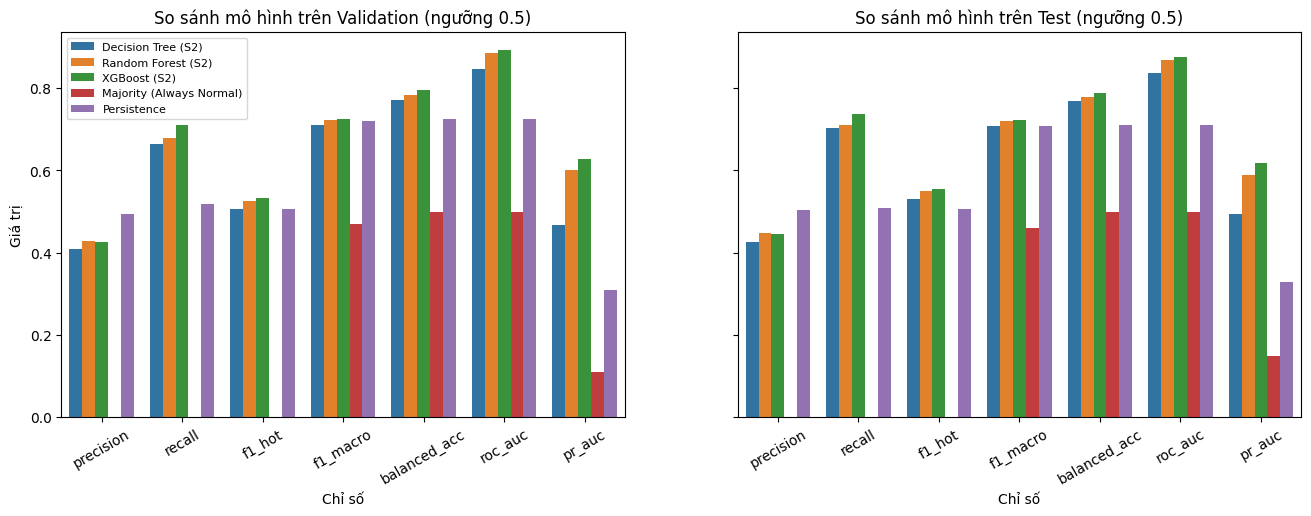

In [121]:
# Biểu đồ 3: so sánh mô hình và baseline (Validation và Test, ngưỡng 0.5)
metric_list = ["precision", "recall", "f1_hot", "f1_macro", "balanced_acc", "roc_auc", "pr_auc"]
plot_rows = []
for split_name, part_name in [("val", "Validation"), ("test", "Test")]:
    for model_name in model_names:
        set_name = best_set_per_model[model_name]
        if split_name == "val":
            row = model_comparison[(model_comparison["model"] == model_name) & (model_comparison["feature_set"] == set_name)].iloc[0]
        else:
            row = main_test[main_test["model"] == model_name].iloc[0]
        for metric in metric_list:
            plot_rows.append({"Tập": part_name, "Mô hình": f"{model_name} ({set_name})", "Chỉ số": metric, "Giá trị": row[metric]})
    for _, row in baseline_results[baseline_results["split"] == split_name].iterrows():
        for metric in metric_list:
            plot_rows.append({"Tập": part_name, "Mô hình": row["baseline"], "Chỉ số": metric, "Giá trị": row[metric]})
plot_df = pd.DataFrame(plot_rows)

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, part_name in zip(axes, ["Validation", "Test"]):
    sns.barplot(data=plot_df[plot_df["Tập"] == part_name], x="Chỉ số", y="Giá trị", hue="Mô hình", ax=ax)
    ax.set_title(f"So sánh mô hình trên {part_name} (ngưỡng 0.5)")
    ax.tick_params(axis="x", rotation=30)
axes[0].legend(fontsize=8)
axes[1].get_legend().remove()
plt.savefig(output_dir + "bieu_do_so_sanh_mo_hinh.png", dpi=150, bbox_inches="tight")
plt.show()

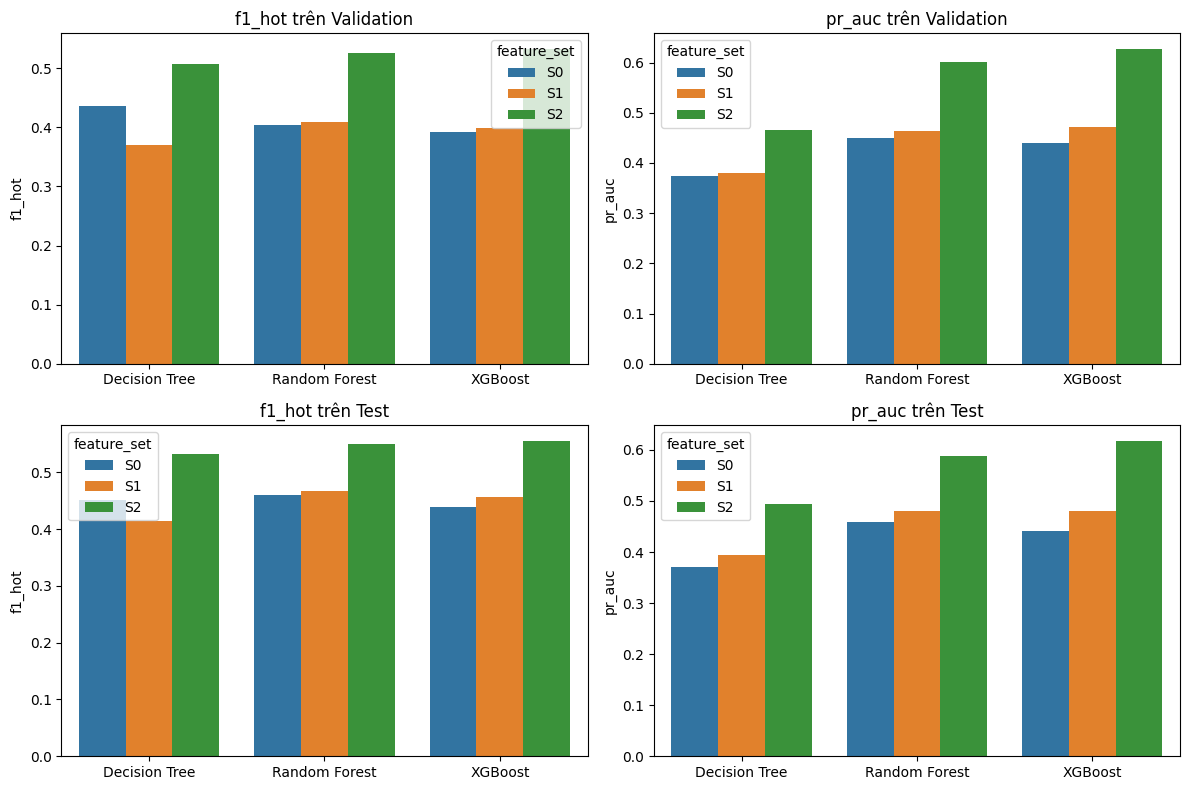

In [122]:
# Biểu đồ 4: so sánh S0 / S1 / S2 cho từng mô hình (F1 lớp Hot và PR-AUC)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, (part_name, table) in enumerate([("Validation", model_comparison),
                                        ("Test", test_results[test_results["threshold_type"] == "0.5"])]):
    for j, metric in enumerate(["f1_hot", "pr_auc"]):
        sns.barplot(data=table, x="model", y=metric, hue="feature_set", ax=axes[i, j])
        axes[i, j].set_title(f"{metric} trên {part_name}")
        axes[i, j].set_xlabel("")
plt.tight_layout()
plt.savefig(output_dir + "bieu_do_so_sanh_S0_S1_S2.png", dpi=150, bbox_inches="tight")
plt.show()

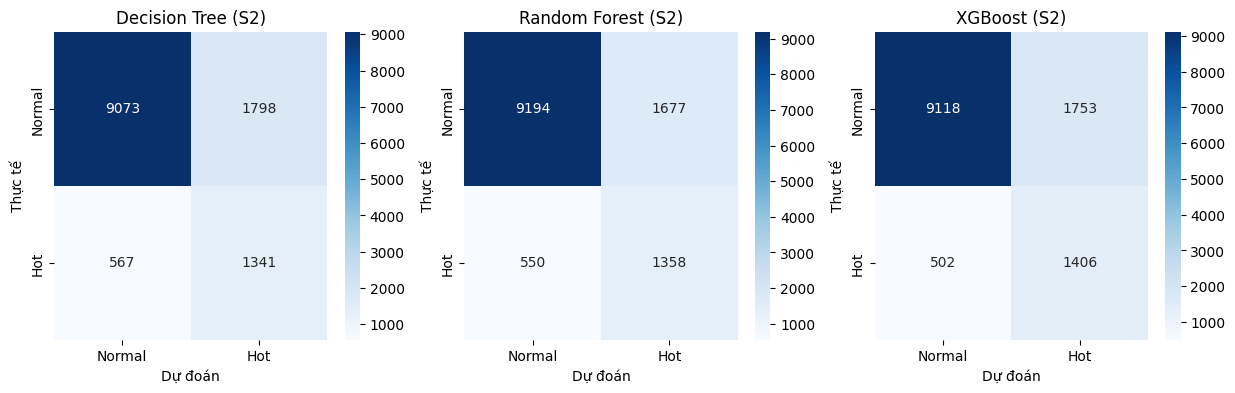

In [123]:
# Biểu đồ 5: Confusion Matrix trên Test (ngưỡng 0.5, tập feature chọn theo Validation)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, model_name in zip(axes, model_names):
    set_name = best_set_per_model[model_name]
    y_pred = (test_probs[(model_name, set_name)] >= 0.5).astype(int)
    sns.heatmap(confusion_matrix(y_test, y_pred, labels=[0, 1]), annot=True, fmt="d", cmap="Blues",
                xticklabels=["Normal", "Hot"], yticklabels=["Normal", "Hot"], ax=ax)
    ax.set_title(f"{model_name} ({set_name})")
    ax.set_xlabel("Dự đoán"); ax.set_ylabel("Thực tế")
plt.savefig(output_dir + "bieu_do_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# Feature Importance

Lấy từ các mô hình cây đã huấn luyện trên Train. Lưu ý:
- Importance chỉ cho biết feature được mô hình sử dụng nhiều hay ít, **không phải quan hệ nhân quả**.
- `kw_*` và `kwg_*` chứa thông tin trùng lặp (mỗi từ khóa thuộc đúng một nhóm), nên importance có thể bị chia sẻ giữa hai loại biến này.

In [124]:
importance_rows = []
for (model_name, set_name), model in final_models.items():
    for feature, value in zip(feature_sets[set_name], model.feature_importances_):
        importance_rows.append({"model": model_name, "feature_set": set_name, "feature": feature,
                                "group": feature_group[feature], "importance": value,
                                "selected": best_set_per_model[model_name] == set_name})
feature_importance = pd.DataFrame(importance_rows)
feature_importance.to_csv(output_dir + "feature_importance.csv", index=False, encoding="utf-8-sig")

selected_imp = feature_importance[feature_importance["selected"]]

In [125]:
# Màu cố định cho từng nhóm feature để các biểu đồ đồng nhất
group_order = ["Calendar", "Identity", "Weather", "Search History"]
group_colors = dict(zip(group_order, ["#e6550d", "#756bb1", "#31a354", "#3182bd"]))

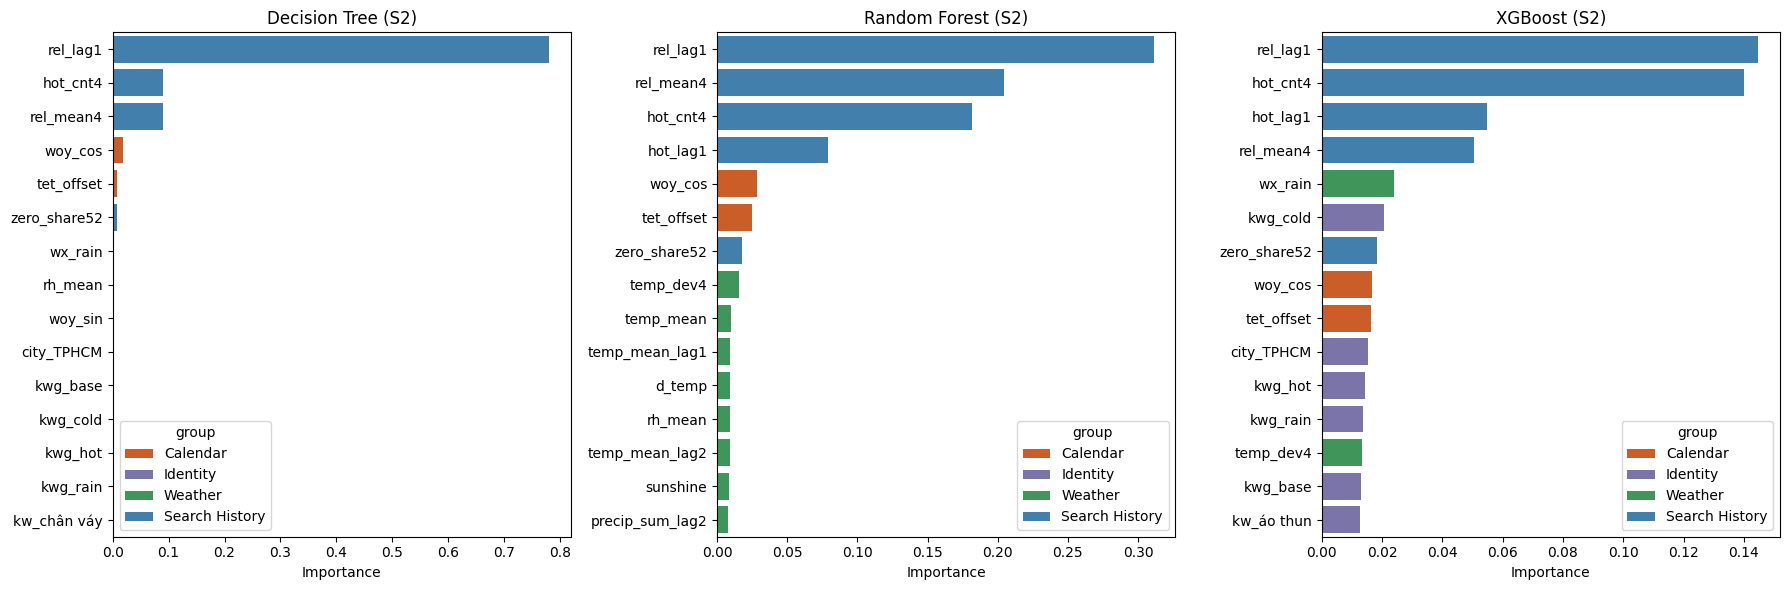

In [126]:
# Biểu đồ 6a: top 15 feature quan trọng nhất của mỗi mô hình
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, model_name in zip(axes, model_names):
    top = selected_imp[selected_imp["model"] == model_name].nlargest(15, "importance")
    sns.barplot(data=top, x="importance", y="feature", hue="group", hue_order=group_order,
                palette=group_colors, dodge=False, ax=ax)
    ax.set_title(f"{model_name} ({best_set_per_model[model_name]})")
    ax.set_xlabel("Importance"); ax.set_ylabel("")
plt.tight_layout()
plt.savefig(output_dir + "bieu_do_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

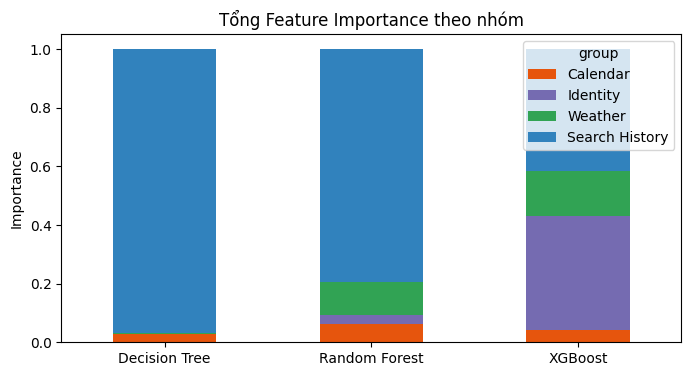

group          Calendar  Identity  Weather  Search History
model                                                     
Decision Tree     0.028     0.000    0.004           0.968
Random Forest     0.061     0.032    0.112           0.795
XGBoost           0.042     0.387    0.155           0.416


In [127]:
# Biểu đồ 6b: tổng importance theo nhóm feature
group_imp = selected_imp.groupby(["model", "group"])["importance"].sum().unstack().loc[model_names, group_order]
group_imp.plot(kind="bar", stacked=True, figsize=(8, 4), color=[group_colors[g] for g in group_order])
plt.title("Tổng Feature Importance theo nhóm"); plt.xlabel(""); plt.ylabel("Importance"); plt.xticks(rotation=0)
plt.savefig(output_dir + "bieu_do_importance_theo_nhom.png", dpi=150, bbox_inches="tight")
plt.show()
print(group_imp.round(3))

# Kiểm tra cuối và lưu kết quả

In [129]:
import pandas as pd
import os

# Kiểm tra tính toàn vẹn bằng cách gộp lại từ 2 file sạch cục bộ
local_hanoi = "/content/clean_data_HaNoi.csv"
local_tphcm = "/content/clean_data_TPHCM.csv"

assert os.path.exists(local_hanoi) and os.path.exists(local_tphcm), "Thiếu các tệp sạch cục bộ để đối chiếu!"

df_hanoi_check = pd.read_csv(local_hanoi, parse_dates=["date"])
df_tphcm_check = pd.read_csv(local_tphcm, parse_dates=["date"])
df_hanoi_check["CityName"] = "HaNoi"
df_tphcm_check["CityName"] = "TPHCM"
df_check = pd.concat([df_hanoi_check, df_tphcm_check], ignore_index=True)

# Đảm bảo df_raw khớp hoàn toàn với dữ liệu sạch ban đầu
assert df_raw.equals(df_check)
print("Xác nhận: Dữ liệu gốc df_raw hoàn toàn chính xác và không bị sửa đổi!")

Xác nhận: Dữ liệu gốc df_raw hoàn toàn chính xác và không bị sửa đổi!


In [130]:
# Đủ 12 file đầu ra
output_files = ["long_data.csv", "labels_p80.csv", "features_buoc5.csv.gz", "bang_mo_ta_feature.csv",
                "bao_cao_thieu_feature.csv", "tscv_folds.csv", "baseline_results.csv", "cv_results.csv",
                "model_comparison.csv", "threshold_results.csv", "test_results.csv", "feature_importance.csv"]
for name in output_files:
    assert os.path.exists(output_dir + name), "Thiếu file " + name
print("Đã tạo đủ", len(output_files), "file kết quả trong", output_dir)

Đã tạo đủ 12 file kết quả trong /content/output_classification/


In [131]:
# Lưu kết quả lên Google Drive
save_to_drive = True
if save_to_drive:
    import shutil
    from google.colab import drive
    drive.mount("/content/drive")
    shutil.copytree(output_dir, "/content/drive/MyDrive/dth/data mining/output_buoc5", dirs_exist_ok=True)
    print("Đã lưu kết quả lên Google Drive.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Đã lưu kết quả lên Google Drive.
